# SAR analysis

### USER INPUT

In [421]:
MINE_POLYGON = "niedzwiedzia_gora_mine_polygon.geojson"
VOIVODESHIP = "malopolskie"
START_DATE = "2024-04-01"
END_DATE = "2024-11-30"
STABLE_POINTS_LONGITUDE = 19.613624
STABLE_POINTS_LATITUDE = 50.118559


### 1. Imports and parameters

In [422]:
import ee
import re
import json
import geemap
import zipfile
import numpy as np
import asf_search as asf
from pathlib import Path
from scipy.ndimage import zoom
from pyproj import Transformer
from scipy.ndimage import label
import matplotlib.pyplot as plt
from PIL import Image as PilImage
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch
from rasterio.transform import Affine
from shapely import wkt as shapely_wkt
from rasterio.features import rasterize
from rasterio.warp import reproject, Resampling
from datetime import datetime, timedelta
from shapely.geometry import shape, Polygon
from shapely.ops import unary_union, transform
from esa_snappy import ProductIO, GPF, HashMap, jpy
from asf_search.constants import INTERNAL as ASF_INTERNAL
from IPython.display import display, Image as NotebookImage

Integer = jpy.get_type("java.lang.Integer")
Double = jpy.get_type("java.lang.Double")
Boolean = jpy.get_type("java.lang.Boolean")
GeoPos = jpy.get_type("org.esa.snap.core.datamodel.GeoPos")
PixelPos = jpy.get_type("org.esa.snap.core.datamodel.PixelPos")

if "asf-urs" not in ASF_INTERNAL.AUTH_COOKIES:
    ASF_INTERNAL.AUTH_COOKIES = list(ASF_INTERNAL.AUTH_COOKIES) + ["asf-urs"]

HOME_DIR = Path(r"c:\space_technologies\Kopalnie\open-pit-mining\sar")
EARTHDATA_TOKEN = (HOME_DIR / "token_asf").read_text(encoding="utf-8").strip()
GEE_PROJECT = (HOME_DIR / "gee_project").read_text(encoding="utf-8").strip()

AOI_MINE = None
AOI_STABLE_POINTS = None
AOI_PROCESSING = None

POLYGON_PATH = HOME_DIR / "mines_polygons" / MINE_POLYGON
MINE_NAME = MINE_POLYGON.removesuffix(".geojson").removesuffix("_mine_polygon")

DOWNLOAD_DIR = HOME_DIR / "safe_downloads"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = HOME_DIR / ("output_activity_maps_" + MINE_NAME)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


### 2. Prepare AOIs


In [423]:
def make_polygon_buffer(path):
    print("Preparing AOI for analysis ...")
    buffer = 200
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    feats = data["features"] if data.get("type") == "FeatureCollection" else [data]
    geom = unary_union([shape(f["geometry"]) for f in feats])

    lon, lat = geom.centroid.x, geom.centroid.y
    zone = int((lon + 180) // 6) + 1
    utm_epsg = (32600 if lat >= 0 else 32700) + zone

    to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{utm_epsg}", always_xy=True)
    to_wgs = Transformer.from_crs(f"EPSG:{utm_epsg}", "EPSG:4326", always_xy=True)

    geom_utm = transform(to_utm.transform, geom)
    bbox_utm = geom_utm.buffer(buffer).envelope
    bbox_wgs = transform(to_wgs.transform, bbox_utm)

    print("  polygon bounds:", geom.bounds)
    print("  AOI bounds:", bbox_wgs.bounds)
    print("  buffer: %d m" % buffer)

    return bbox_wgs.wkt


def make_reference_window():
    print("Preparing reference window %s ...")
    buffer = 1500
    zone = int((STABLE_POINTS_LONGITUDE + 180) // 6) + 1
    utm_epsg = (32600 if STABLE_POINTS_LATITUDE >= 0 else 32700) + zone
    
    to_utm = Transformer.from_crs("EPSG:4326", "EPSG:%d" % utm_epsg, always_xy=True)
    to_wgs = Transformer.from_crs("EPSG:%d" % utm_epsg, "EPSG:4326", always_xy=True)

    center = shapely_wkt.loads("POINT (%s %s)" % (STABLE_POINTS_LONGITUDE, STABLE_POINTS_LATITUDE))
    center_utm = transform(to_utm.transform, center)
    bbox_wgs = transform(to_wgs.transform, center_utm.buffer(buffer).envelope)

    print("  window bounds:", bbox_wgs.bounds)
    print("  buffer: %d m" % buffer)
    return bbox_wgs.wkt


### 3. Stack of Sentinel-1 SLC products


In [424]:
def _search_in_geo_search():
    start = datetime.combine(
        datetime.strptime(START_DATE, "%Y-%m-%d").date(),
        datetime.min.time(),
    )
    end = datetime.combine(
        datetime.strptime(END_DATE, "%Y-%m-%d").date(),
        datetime.max.time(),
    )
    assert end >= start, "END_DATE < START_DATE"

    results = asf.geo_search(
        platform=[asf.PLATFORM.SENTINEL1],
        processingLevel=[asf.PRODUCT_TYPE.SLC],
        beamMode=[asf.BEAMMODE.IW],
        polarization=[asf.POLARIZATION.VV_VH],
        intersectsWith=AOI_MINE,
        start=start,
        end=end,
        maxResults=250,
    )

    whole_aoi_inside = []
    for r in results:
        scene = shape(r.geojson()["geometry"])
        if scene.covers(shapely_wkt.loads(AOI_PROCESSING)):
            whole_aoi_inside.append(r)
    return sorted(whole_aoi_inside, key=lambda r: r.properties.get("startTime", ""))


def _prepare_scene_stack(results):
    assert results, "  No scene in date %s .. %s" % (START_DATE, END_DATE)
    first = results[0]
    rel_orbit = first.properties.get("pathNumber")
    flight_dir = first.properties.get("flightDirection")
    stack = []
    seen_dates = set()

    winter_days = []
    for r in results:
        p = r.properties
        if p.get("pathNumber") != rel_orbit:
            continue
        if p.get("flightDirection") != flight_dir:
            continue
        day = (p.get("startTime") or "")[:10]
        if not day or day in seen_dates:
            continue
        if int(day[5:7]) in (12, 1, 2):
            winter_days.append(day)
            continue
        seen_dates.add(day)
        stack.append(r)
    
    if winter_days:
        print("  rejected %d winter scenes: %s" % (len(winter_days), ", ".join(winter_days)))
    return stack, rel_orbit, flight_dir


def find_sentinel_1_scenes():
    print("Searching for Sentinel-1 scenes ...")

    raw_results = _search_in_geo_search()
    scene_stack, rel_orbit, flight_dir = _prepare_scene_stack(raw_results)

    print("  scenes found: %d" % len(scene_stack))
    print("  date range: %s - %s" % (START_DATE, END_DATE))
    print("  relative orbit = %s;  flight direction = %s" % (rel_orbit, flight_dir))

    for i, r in enumerate(scene_stack, 1):
        p = r.properties
        name = p.get("fileName")
        day = (p.get("startTime"))[:10]
        print("  %2d. %s  %s" % (i, day, name))

    assert len(scene_stack) >= 10, (
        "Need at least 10 scenes for valid analysis — got %d" % len(scene_stack)
    )
    return scene_stack


### 4. Close and remove products

In [425]:
def _java_field(obj, name):
    unsafe = _unsafe()
    cls = obj.getClass()
    while cls is not None:
        try:
            field = cls.getDeclaredField(name)
        except Exception:
            cls = cls.getSuperclass()
            continue
        try:
            field.setAccessible(True)
            return field.get(obj)
        except Exception:
            return unsafe.getObject(obj, unsafe.objectFieldOffset(field))
    return None


def _unsafe():
    Class = jpy.get_type("java.lang.Class")
    unsafe_cls = Class.forName("sun.misc.Unsafe")
    unsafe_field = unsafe_cls.getDeclaredField("theUnsafe")
    unsafe_field.setAccessible(True)
    return unsafe_field.get(None)


def _release_product(product):
    reader = product.getProductReader()
    data_dir = _java_field(reader, "dataDir")
    if data_dir is not None:
        _java_field(_java_field(data_dir, "productDir"), "zipFile").close()
    product.dispose()


def _release_zip_sources(path):
    unsafe = _unsafe()
    Class = jpy.get_type("java.lang.Class")
    source_cls = Class.forName("java.util.zip.ZipFile$Source")
    files_field = source_cls.getDeclaredField("files")
    files = unsafe.getObject(unsafe.staticFieldBase(files_field), unsafe.staticFieldOffset(files_field))
    refs_offset = unsafe.objectFieldOffset(source_cls.getDeclaredField("refs"))
    zfile_offset = unsafe.objectFieldOffset(source_cls.getDeclaredField("zfile"))
    target = str(Path(path).resolve()).lower()
    
    for key in files.keySet().toArray():
        file_obj = unsafe.getObject(key, unsafe.objectFieldOffset(key.getClass().getDeclaredField("file")))
        if str(file_obj.getCanonicalPath()).lower() != target:
            continue
        src = files.remove(key)
        raf = unsafe.getObject(src, zfile_offset)
        raf.close()
        unsafe.putObject(src, zfile_offset, None)
        unsafe.putInt(src, refs_offset, 0)


def close_products(products):
    already_closed = set()
    for product in reversed(products):
        identity = int(product.hashCode())
        if identity in already_closed:
            continue
        already_closed.add(identity)
        _release_product(product)


def remove_scene(path):
    _release_zip_sources(path)
    path.unlink()
    print("Removed: %s" % path.name)


### 5. Download SLC products

In [426]:
def _zip_is_complete(path, product):
    expected = product.properties.get("bytes")
    if path.stat().st_size != int(expected):
        return False
    if not zipfile.is_zipfile(path):
        return False
    with zipfile.ZipFile(path) as archive:
        return any(name.endswith("manifest.safe") for name in archive.namelist())
        

def scene_day(path):
    return datetime.strptime(re.search(r"(\d{8})T", Path(path).name).group(1), "%Y%m%d")


def start_asf_session():
    session = asf.ASFSession()
    session.auth_cookie_names = list(
        dict.fromkeys(list(session.auth_cookie_names) + ["asf-urs"])
    )
    session.auth_with_token(EARTHDATA_TOKEN)
    print("Logging in ASF Data Search Vertex ...")
    return session


def _initialize_gee():
    ee.Initialize(project=GEE_PROJECT)


def download_images(product, session):
    image = product.properties.get("fileName")
    dest = Path(DOWNLOAD_DIR) / image

    print("Download: %s ..." % image)
    if dest.exists() and _zip_is_complete(dest, product):
        print("  File is already downloaded: %s (%.2f GB)" % (dest.resolve(), dest.stat().st_size / 1e9))
        return dest
    if dest.exists():
        print("  Incomplete file, downloading again: %s (%.2f GB)" % (dest.name, dest.stat().st_size / 1e9))
        _release_zip_sources(dest)
        dest.unlink()

    print("Downloading: %s ..." % image)
    product.download(path=str(Path(DOWNLOAD_DIR)), session=session)

    if not _zip_is_complete(dest, product):
        _release_zip_sources(dest)
        dest.unlink()
        raise RuntimeError("  Downloaded file is incomplete: %s" % dest.name)
        
    print("Downloaded: %s (%.2f GB)" % (dest.name, dest.stat().st_size / 1e9))
    return dest
    

### 6. Open SLC product

In [427]:
def open_slc(zip_path):
    product = ProductIO.readProduct(str(zip_path))
    print("Opening: ", product.getName())
    return product

### 7. Apply Orbit File

In [428]:
def apply_orbit_file(product):
    print("Apply Orbit File ...")
    
    params = HashMap()
    params.put("orbitType", "Sentinel Precise (Auto Download)")
    params.put("polyDegree", Integer(3))
    params.put("continueOnFail", Boolean.FALSE)
    
    orbit = GPF.createProduct("Apply-Orbit-File", params, product)
    return orbit
    

### 8. TOPS Split

In [429]:
def _swath_to_rectangle(product, band_name):
    band = product.getBand(band_name)
    gc = band.getGeoCoding()
    w, h = band.getRasterWidth(), band.getRasterHeight()
    corners = []

    for x, y in ((0, 0), (w - 1, 0), (w - 1, h - 1), (0, h - 1)):
        gp = GeoPos()
        gc.getGeoPos(PixelPos(float(x), float(y)), gp)
        corners.append((gp.lon, gp.lat))
    return Polygon(corners)


def choose_subswaths_for_aoi(product):
    swaths = []

    for swath in ("IW1", "IW2", "IW3"):
        rectangle = _swath_to_rectangle(product, f"Intensity_{swath}_VV")
        intersection = rectangle.intersection(shapely_wkt.loads(AOI_PROCESSING))
        area = intersection.area if not intersection.is_empty else 0.0
        if area > 0:
            swaths.append(swath)

    print("  subswaths: %s" % ", ".join(swaths))
    return swaths


def topsar_split(product, subswath):
    print("S-1 TOPS Split ...")

    params = HashMap()
    params.put("subswath", subswath)
    params.put("selectedPolarisations", "VV")
    params.put("wktAoi", AOI_PROCESSING)
    
    split = GPF.createProduct("TOPSAR-Split", params, product)
    return split


### 9. Back Geocoding

In [430]:
def back_geocoding(master, slave):
    print("S-1 Back-Geocoding: Copernicus 30m, bilinear ...")

    params = HashMap()
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("resamplingType", "BILINEAR_INTERPOLATION")
    params.put("maskOutAreaWithoutElevation", Boolean.TRUE)
    params.put("outputRangeAzimuthOffset", Boolean.FALSE)
    params.put("outputDerampDemodPhase", Boolean.FALSE)
    params.put("disableReramp", Boolean.FALSE)
    Product = jpy.get_type("org.esa.snap.core.datamodel.Product")
    sources = jpy.array(Product, 2)
    sources[0] = master
    sources[1] = slave

    geocoding = GPF.createProduct("Back-Geocoding", params, sources)
    return geocoding
    

### 10. Coherence Estimation

In [431]:
def coherence_estimation(raster):
    print("Coherence Estimation: Copernicus 30m, topographic phase, window 10x3 ...")

    params = HashMap()
    params.put("subtractFlatEarthPhase", Boolean.TRUE)
    params.put("srpPolynomialDegree", Integer(5))
    params.put("srpNumberPoints", Integer(501))
    params.put("orbitDegree", Integer(3))
    params.put("squarePixel", Boolean.FALSE)
    params.put("cohWinRg", Integer(10))
    params.put("cohWinAz", Integer(3))
    params.put("subtractTopographicPhase", Boolean.TRUE)
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")

    coherence = GPF.createProduct("Coherence", params, raster)
    return coherence


### 11. TOPS Deburst

In [432]:
def topsar_deburst(raster):
    print("S-1 TOPS Deburst ...")

    params = HashMap()
    params.put("selectedPolarisations", "VV")
    
    deburst = GPF.createProduct("TOPSAR-Deburst", params, raster)
    return deburst


### 12. TOPS Merge

In [433]:
def topsar_merge(raster):
    print("S-1 TOPS Merge ...")

    params = HashMap()
    params.put("selectedPolarisations", "VV")
    Product = jpy.get_type("org.esa.snap.core.datamodel.Product")
    sources = jpy.array(Product, len(raster))
    for i, product in enumerate(raster):
        sources[i] = product

    merged = GPF.createProduct("TOPSAR-Merge", params, sources)
    return merged
    

### 13. Multilook

In [434]:
def multilook(raster):
    print("Multilook: 6 range x 1 azimuth ...")

    params = HashMap()
    params.put("nRgLooks", Integer(6))
    params.put("nAzLooks", Integer(1))
    params.put("outputIntensity", Boolean.FALSE)
    params.put("grSquarePixel", Boolean.FALSE)

    looked = GPF.createProduct("Multilook", params, raster)
    return looked

### 14. Range-Doppler Terrain Correction

In [435]:
def terrain_correction(raster):
    print("Range-Doppler Terrain Correction: Copernicus 30m, bilinear ...")

    WGS84 = (
        'GEOGCS["WGS84(DD)",'
        'DATUM["WGS84",SPHEROID["WGS84",6378137.0,298.257223563]],'
        'PRIMEM["Greenwich",0.0],'
        'UNIT["degree",0.017453292519943295],'
        'AXIS["Geodetic longitude",EAST],'
        'AXIS["Geodetic latitude",NORTH],'
        'AUTHORITY["EPSG","4326"]]'
    )

    params = HashMap()
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("imgResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("mapProjection", WGS84)
    params.put("pixelSpacingInMeter", Double(13.92475))
    params.put("nodataValueAtSea", Boolean.TRUE)
    params.put("saveSelectedSourceBand", Boolean.TRUE)
    params.put("saveDEM", Boolean.FALSE)
    params.put("saveLatLon", Boolean.FALSE)
    params.put("saveLocalIncidenceAngle", Boolean.FALSE)
    params.put("saveLayoverShadowMask", Boolean.TRUE)
    params.put("outputComplex", Boolean.FALSE)
    params.put("alignToStandardGrid", Boolean.TRUE)
    params.put("applyRadiometricNormalization", Boolean.FALSE)

    terrain_correction = GPF.createProduct("Terrain-Correction", params, raster)
    return terrain_correction
    

### 15. Subset

In [436]:
def subset(raster, region):
    print("Subset ...")

    params = HashMap()
    params.put("geoRegion", region)
    params.put("copyMetadata", Boolean.TRUE)
    params.put("fullSwath", Boolean.FALSE)
    
    subset = GPF.createProduct("Subset", params, raster)
    return subset

### 16. Rasters to arrays


In [437]:
def _band_name(raster, key):
    for name in raster.getBandNames():
        if key(str(name).lower()):
            return str(name)
    return None


def _read_pixels(band):
    width = band.getRasterWidth()
    height = band.getRasterHeight()
    arr = np.empty(width * height, dtype=np.float32)
    band.readPixels(0, 0, width, height, arr)
    return arr.reshape(height, width)


def _scene_grid(raster):
    gc = raster.getSceneGeoCoding()
    width = raster.getSceneRasterWidth()
    height = raster.getSceneRasterHeight()

    def geo(x, y):
        gp = GeoPos()
        gc.getGeoPos(PixelPos(float(x), float(y)), gp)
        return float(gp.lon), float(gp.lat)

    lon00, lat00 = geo(0, 0)
    lon10, _ = geo(1, 0)
    _, lat01 = geo(0, 1)
    dx = lon10 - lon00
    dy = lat01 - lat00
    grid = Affine(dx, 0.0, lon00 - dx / 2.0, 0.0, dy, lat00 - dy / 2.0)
    left = grid.c
    top = grid.f
    extent = (left, left + dx * width, top + dy * height, top)
    profile = {
        "driver": "GTiff",
        "dtype": "float32",
        "count": 1,
        "width": width,
        "height": height,
        "crs": "EPSG:4326",
        "transform": grid,
    }
    return grid, extent, profile


def raster_to_array(raster, master_zip, slave_zip, label):
    print("Convert raster %s to array ..." % label)
    master_day = scene_day(master_zip)
    slave_day = scene_day(slave_zip)
    master_slave_dates = "%s_%s" % (master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d"))

    coherence_name = _band_name(raster, lambda name: name.startswith("coh"))
    coh_pixels = _read_pixels(raster.getBand(coherence_name))
    coherence = np.where((coh_pixels < 0) | (coh_pixels > 1), np.nan, coh_pixels).astype(np.float32, copy=False)

    shadow_name = _band_name(raster, lambda name: "layover" in name or "shadow" in name)
    shadow = _read_pixels(raster.getBand(shadow_name)) if shadow_name is not None else None

    grid, extent, profile = _scene_grid(raster)
    return {
        "name": master_slave_dates,
        "coherence": coherence,
        "shadow": shadow,
        "transform": grid,
        "extent": extent,
        "profile": profile,
    }


### 17. Stable points

In [438]:
def _polygons_from_gee(collection):
    data = collection.getInfo() or {}
    polygons = []
    for feature in data.get("features", []):
        geometry = feature.get("geometry")
        geom = shape(geometry)
        if not geom.is_valid:
            geom = geom.buffer(0)
        if geom.geom_type == "Polygon":
            polygons.append(geom)
        elif geom.geom_type == "MultiPolygon":
            polygons.extend([part for part in geom.geoms if not part.is_empty])
    return polygons


def _rasterize_polygon(polygons, shape_hw, grid_transform):
    mask =  rasterize(
        [(geom, 1) for geom in polygons],
        out_shape=shape_hw,
        transform=grid_transform,
        fill=0,
        dtype="uint8",
    )
    return mask


def _cluster_size_mask(mask, min_pixels, structure):
    labeled, n = label(mask, structure=structure)
    if n == 0:
        return np.zeros(mask.shape, dtype=bool)
    counts = np.bincount(labeled.ravel())
    keep = counts >= min_pixels
    keep[0] = False
    return keep[labeled]


def _show_stable_points(mean, stable):
    fig, ax = plt.subplots(figsize=(8, 8))
    show = np.ma.masked_invalid(mean)
    ax.imshow(show, cmap="gray", vmin=0, vmax=1)
    overlay = np.zeros(mean.shape + (4,), dtype=np.float32)
    overlay[stable] = (0.88, 0.04, 0.0, 0.85)
    ax.imshow(overlay)
    ax.set_axis_off()
    fig.tight_layout()
    plt.show()


def calculate_stable_points(references):
    print("Stable points ...")

    base = references[0]

    _initialize_gee()
    aoi = ee.Geometry(shapely_wkt.loads(AOI_STABLE_POINTS).__geo_interface__)

    stack = np.stack([ref["coherence"] for ref in references], axis=0)
    grid_transform = base["transform"]
    shape_hw = stack.shape[1:]

    folder = "projects/mining-457808/assets/%s" % VOIVODESHIP
    buildings = _polygons_from_gee(ee.FeatureCollection("%s/buildings" % folder).filterBounds(aoi))
    if not buildings:
        raise RuntimeError("No building in the reference window")
    building_mask = _rasterize_polygon(buildings, shape_hw, grid_transform).astype(bool)

    count = np.sum(np.isfinite(stack), axis=0)
    enough = count >= max(3, int(0.8 * stack.shape[0]))
    reference = building_mask & enough
    print("  building pixels in the reference window: %d" % int(reference.sum()))

    mean = np.nanmean(np.where(reference, stack, np.nan), axis=0)
    std = np.nanstd(np.where(reference, stack, np.nan), axis=0)
    finite = reference & np.isfinite(mean) & np.isfinite(std)
    strict = finite & (mean > 0.8) & (std < 0.2)
    stable = _cluster_size_mask(strict, 3, np.ones((3, 3), dtype=int))
    
    print("  building pixels with mean > 0.8 and std < 0.2: %d" % int(strict.sum()))
    print("  after removing isolated pixels, stable pixels accepted: %d" % int(stable.sum()))
    accepted = int(stable.sum()) >= 30
    if not accepted:
        raise RuntimeError("Fewer than 30 compact building pixels. The analysis cannot continue.")

    pairs = []
    gammas = []
    center = float("nan")

    print("  stable coherence mean: %.3f" % float(np.nanmean(mean[stable])))
    print("  stable coherence std: %.3f" % float(np.nanmean(std[stable])))

    for ref, image in zip(references, stack):
        values = image[stable]
        values = values[np.isfinite(values)]
        gamma = float(np.mean(values)) if values.size else float("nan")
        gammas.append(gamma)
        pairs.append({
            "name": ref["name"],
            "gamma_stable": None if np.isnan(gamma) else round(gamma, 4),
        })
    
    center = float(np.nanmedian(gammas))
    kept = []
    for pair, gamma in zip(pairs, gammas):
        if not np.isnan(gamma) and gamma >= center - 0.10:
            kept.append(pair)
        else:
            print("  reject pair %s, gamma_stable %.3f" % (pair["name"], gamma))

    print("  pairs kept: %d" % len(kept))
    if not kept:
        raise RuntimeError("Every pair was rejected. The analysis cannot continue.")

    _show_stable_points(mean, stable)
    return kept


### 18. Water and vegetation mask from Sentinel-2

In [439]:
def _ten_meter_grid(extent):
    minx, maxx, miny, maxy = extent
    lon = 0.5 * (minx + maxx)
    lat = 0.5 * (miny + maxy)
    zone = int((lon + 180) // 6) + 1
    epsg = (32600 if lat >= 0 else 32700) + zone
    to_utm = Transformer.from_crs("EPSG:4326", "EPSG:%d" % epsg, always_xy=True)
    corners = ((minx, miny), (maxx, miny), (maxx, maxy), (minx, maxy))
    east, north = zip(*(to_utm.transform(x, y) for x, y in corners))
    left = float(np.floor(min(east) / 10.0) * 10.0)
    right = float(np.ceil(max(east) / 10.0) * 10.0)
    bottom = float(np.floor(min(north) / 10.0) * 10.0)
    top = float(np.ceil(max(north) / 10.0) * 10.0)
    width = int(round((right - left) / 10.0))
    height = int(round((top - bottom) / 10.0))
    transform = Affine(10.0, 0.0, left, 0.0, -10.0, top)
    return epsg, transform, height, width


def _index_array_10m(index, band, extent):
    epsg, transform, height, width = _ten_meter_grid(extent)
    struct = ee.data.computePixels({
        "expression": index.unmask(-9999),
        "fileFormat": "NUMPY_NDARRAY",
        "bandIds": [band],
        "grid": {
            "dimensions": {"width": width, "height": height},
            "affineTransform": {
                "scaleX": 10,
                "shearX": 0,
                "translateX": transform.c,
                "shearY": 0,
                "scaleY": -10,
                "translateY": transform.f,
            },
            "crsCode": "EPSG:%d" % epsg,
        },
    })
    values = np.asarray(struct[band], dtype=np.float32)
    values[values < -1.5] = np.nan
    return values, transform, "EPSG:%d" % epsg


def _bands_on_10m(image, bands, extent):
    epsg, transform, height, width = _ten_meter_grid(extent)
    struct = ee.data.computePixels({
        "expression": image.unmask(-9999),
        "fileFormat": "NUMPY_NDARRAY",
        "bandIds": list(bands),
        "grid": {
            "dimensions": {"width": width, "height": height},
            "affineTransform": {
                "scaleX": 10,
                "shearX": 0,
                "translateX": transform.c,
                "shearY": 0,
                "scaleY": -10,
                "translateY": transform.f,
            },
            "crsCode": "EPSG:%d" % epsg,
        },
    })
    arrays = {}
    for band in bands:
        values = np.asarray(struct[band], dtype=np.float32)
        values[values < -1.5] = np.nan
        arrays[band] = values
    return arrays, transform, "EPSG:%d" % epsg


def _reproject_boolean(mask, src_transform, src_crs, shape_hw, grid_transform):
    dest = np.zeros(shape_hw, dtype=np.uint8)
    reproject(
        source=np.asarray(mask, dtype=np.uint8),
        destination=dest,
        src_transform=src_transform,
        src_crs=src_crs,
        dst_transform=grid_transform,
        dst_crs="EPSG:4326",
        resampling=Resampling.nearest,
    )
    return dest.astype(bool)


def _mask_on_sar_grid(index, band, extent, shape_hw, grid_transform, threshold):
    values, src_transform, src_crs = _index_array_10m(index, band, extent)
    mask = np.isfinite(values) & (values >= threshold)
    return _reproject_boolean(mask, src_transform, src_crs, shape_hw, grid_transform)


def _extend_date_range_by_month(day, months):
    month = day.month - 1 + months
    year = day.year + month // 12
    month = month % 12 + 1
    lengths = [31, 29 if year % 4 == 0 and (year % 100 != 0 or year % 400 == 0) else 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    return day.replace(year=year, month=month, day=min(day.day, lengths[month - 1]))


def _image_label(image):
    meta = ee.Dictionary({
        "id": image.get("system:index"),
        "date": ee.Date(image.get("system:time_start")).format("YYYY.MM.dd"),
    }).getInfo()
    return "%s %s" % (meta["date"], meta["id"])


def _contains_whole_aoi(image, aoi):
    contains_aoi = bool(image.geometry().contains(aoi, ee.ErrorMargin(1)).getInfo())
    return contains_aoi


def _check_clouds(image, aoi):
    scl = image.select("SCL")
    cloud = (scl.eq(3).Or(scl.eq(8)).Or(scl.eq(9)).Or(scl.eq(10)).rename("cloud"))
    clouds_fraction = cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=20,
        maxPixels=1e8,
    ).get("cloud").getInfo()
    return clouds_fraction


def ndwi_mask(image, extent, shape_hw, grid_transform):
    print("    water mask from NDWI, NDWI >= -0.1  ...")
    ndwi = image.select(["B3", "B8"]).divide(10000).normalizedDifference(["B3", "B8"]).rename("NDWI")
    water = _mask_on_sar_grid(ndwi, "NDWI", extent, shape_hw, grid_transform, -0.1)
    if not water.any():
        print("    No water on the image")
    return water


def ndvi_swir_mask(image, extent, shape_hw, grid_transform):
    print("    vegetation mask from NDVI and SWIR, NDVI >= 0.40 and B11 < 0.26 ...")
    ndvi = image.select(["B8", "B4"]).divide(10000).normalizedDifference(["B8", "B4"]).rename("NDVI")
    swir = image.select(["B11"]).divide(10000).rename("SWIR")
    arrays, src_transform, src_crs = _bands_on_10m(ndvi.addBands(swir), ["NDVI", "SWIR"], extent)
    mask = (
        np.isfinite(arrays["NDVI"]) & (arrays["NDVI"] >= 0.4)
        & np.isfinite(arrays["SWIR"]) & (arrays["SWIR"] < 0.26)
    )
    vegetation = _reproject_boolean(mask, src_transform, src_crs, shape_hw, grid_transform)
    if not vegetation.any():
        print("    No NDVI and SWIR vegetation in the mine area")
    return vegetation


def find_sentinel2_images(start, end, first_only=False):
    print("    searching for Sentinel-2 images ...")
    print("      date range: %s - %s" % (start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")))

    aoi = ee.Geometry(shapely_wkt.loads(AOI_MINE).__geo_interface__)

    start = datetime.combine(start.date(), datetime.min.time())
    end = datetime.combine(end.date(), datetime.max.time())

    col = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(start, end)
        .sort("system:time_start")
    )

    total = col.size().getInfo()
    if not total:
        return []

    listed = col.toList(total)
    image_accepted = []
    for image in range(total):
        image = ee.Image(listed.get(image))

        if not _contains_whole_aoi(image, aoi):
            continue

        clouds = _check_clouds(image, aoi)
        if clouds is None or clouds > 0:
            continue

        if first_only:
            return image
        
        image_accepted.append(image)

    return image_accepted


### 19. Normalized Differential Activity Index

In [440]:
def _shadow_mask(record, shape_hw, announced):
    shadow = record["shadow"]
    if shadow is None:
        if not announced[0]:
            print("  Shadow mask is missing. Radar shadow is not removed.")
            announced[0] = True
        return np.zeros(shape_hw, dtype=bool)
    return np.isfinite(shadow) & (shadow > 0)


def _ndai_threshold(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    low, high = np.quantile(values, [0.005, 0.995])
    clipped = np.clip(values, low, high)
    if np.std(clipped) < 1e-6:
        return float(np.median(clipped)), "median, no spread"
    if clipped.size > 200000:
        clipped = np.random.default_rng(0).choice(clipped, 200000, replace=False)

    density_grid = np.linspace(float(low), float(high), 512)
    density = gaussian_kde(clipped)(density_grid)
    slope = np.sign(np.diff(density))
    valleys = np.where((slope[:-1] < 0) & (slope[1:] > 0))[0] + 1
    span = float(high - low)
    interior = [
        index for index in valleys
        if low + 0.1 * span < density_grid[index] < high - 0.1 * span
    ]
    if len(interior):
        best = min(interior, key=lambda index: density[index])
        return float(density_grid[best]), "density minimum"

    hist, edges = np.histogram(clipped, bins=256)
    centers = (edges[:-1] + edges[1:]) / 2.0
    weight_low = np.cumsum(hist).astype(np.float64)
    weight_high = np.cumsum(hist[::-1])[::-1].astype(np.float64)
    sum_low = np.cumsum(hist * centers)
    sum_high = np.cumsum((hist * centers)[::-1])[::-1]
    mean_low = sum_low / np.maximum(weight_low, 1)
    mean_high = sum_high / np.maximum(weight_high, 1)
    between = weight_low[:-1] * weight_high[1:] * (mean_low[:-1] - mean_high[1:]) ** 2
    return float(centers[int(np.argmax(between))]), "otsu, no interior minimum"


def changed_area_inside_polygon(change, mine_mask, grid_transform):
    mine = np.asarray(mine_mask, dtype=bool)
    inside = np.asarray(change, dtype=bool) & mine
    count = int(inside.sum())
    mine_count = int(mine.sum())
    percent = 100.0 * count / mine_count if mine_count else 0.0
    rows = np.flatnonzero(np.asarray(mine_mask).any(axis=1))
    row = 0.5 * (rows[0] + rows[-1]) if rows.size else mine_mask.shape[0] / 2.0
    lat = grid_transform.f + grid_transform.e * row
    lat_rad = np.deg2rad(lat)
    meters_lat = 111132.92 - 559.82 * np.cos(2 * lat_rad) + 1.175 * np.cos(4 * lat_rad)
    meters_lon = 111412.84 * np.cos(lat_rad) - 93.5 * np.cos(3 * lat_rad)
    pixel_area = abs(float(grid_transform.a)) * meters_lon * abs(float(grid_transform.e)) * meters_lat
    return count * pixel_area, percent


def activity_map(arr, polygon, master_day, slave_day, extent, area, percent):
    ...


def activity_map_with_masks(arr, polygon, master_day, slave_day, extent, area, percent, water, vegetation, shadow, file_suffix="activity_map_with_mask", title="Activity Map", vegetation_label="vegetation"):
    ...


def activity_map_with_sentinel2_references(array, polygon, master_day, slave_day, extent, area, percent):
    ...


def ndai_maps(stack_coherence_mine, gamma_stable_for_raster):
    print("Calculating Normalized Differential Activity Index treshold ...")

    by_name = {raster["name"]: raster for raster in stack_coherence_mine}
    mine_raster = by_name[gamma_stable_for_raster[0]["name"]]
    extent = mine_raster["extent"]
    grid_transform = mine_raster["transform"]
    shape_hw = mine_raster["coherence"].shape

    mine = shape(json.loads(POLYGON_PATH.read_text(encoding="utf-8"))["features"][0]["geometry"])
    mine_mask = _rasterize_polygon([mine], shape_hw, grid_transform).astype(bool)
    announced = [False]
    samples = []
    prepared = []
    pair_count = len(gamma_stable_for_raster)
    for index, reference in enumerate(gamma_stable_for_raster, 1):
        master_day = datetime.strptime(reference["name"].split("_")[0], "%Y.%m.%d")
        slave_day = datetime.strptime(reference["name"].split("_")[1], "%Y.%m.%d")
        print(
            "  pair %d/%d: %s - %s"
            % (index, pair_count, master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d"))
        )
        sentinel2_images = find_sentinel2_images(
            slave_day + timedelta(days=1),
            _extend_date_range_by_month(slave_day, 1),
            first_only=True,
        )
        if not sentinel2_images:
            print("    skip %s, no cloud-free Sentinel-2 scene within one month after" % reference["name"])
            continue
        print("      Sentinel-2 scene selected: %s" % _image_label(sentinel2_images))
        
        water = ndwi_mask(sentinel2_images, extent, shape_hw, grid_transform)
        vegetation = ndvi_swir_mask(sentinel2_images, extent, shape_hw, grid_transform)

        mine_raster = by_name[reference["name"]]
        gamma = mine_raster["coherence"]
        shadow = _shadow_mask(mine_raster, shape_hw, announced)
        numerator = reference["gamma_stable"] - gamma
        denominator = reference["gamma_stable"] + gamma
        ndai = np.full(shape_hw, np.nan, dtype=np.float32)
        valid = np.isfinite(gamma) & (np.abs(denominator) > 1e-6)
        ndai[valid] = numerator[valid] / denominator[valid]
        sample = ndai[mine_mask & ~water & ~vegetation & ~shadow & np.isfinite(ndai)]
        if sample.size:
            samples.append(sample)
        prepared.append((index, reference, ndai, shadow, water, vegetation, master_day, slave_day))

    if not samples:
        raise RuntimeError("No NDAI samples inside the mine")

    pooled = np.concatenate(samples)
    threshold, rule = _ndai_threshold(pooled)
    print("  NDAI threshold: %.4f, rule used: %s)" % (threshold, rule))

    print("Calculating Normalized Differential Activity Index maps ...")
    saved = []
    for index, reference, ndai, shadow, water, vegetation, master_day, slave_day in prepared:
        print(
            "  pair %d/%d: %s - %s"
            % (index, pair_count, master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d"))
        )
        
        change = np.isfinite(ndai) & (ndai > threshold) & ~water & ~vegetation & ~shadow
        change = _cluster_size_mask(change, 3, np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=int))
        area, percent = changed_area_inside_polygon(change, mine_mask, grid_transform)
        print(
            "    area changed inside the polygon: %.0f m2, %.1f%% of the polygon"
            % (area, percent)
        )

        activity_map_with_masks(
            change.astype(np.uint8), mine, master_day, slave_day, extent, area, percent,
            water, vegetation, shadow,
        )
        
        final_map = activity_map(
            change.astype(np.uint8), mine, master_day, slave_day, extent, area, percent,
        )
        saved.append(final_map)

        activity_map_with_sentinel2_references(
            change.astype(np.uint8), mine, master_day, slave_day, extent, area, percent,
        )

    return saved

### 20. Visualization

In [441]:
def _visualization_info(master_day, slave_day, area, percent):
    dates = "%s - %s" % (master_day.strftime("%d.%m.%Y"), slave_day.strftime("%d.%m.%Y"))
    area_changed = "area altered: %.2f ha (%.1f%% of the mine)" % (area / 10000.0, percent)
    mine_name = MINE_NAME.replace("_", " ").title()
    return dates, area_changed, mine_name

def _draw_outline(ax, arr, geom, extent):
    if isinstance(geom, str):
        geom = shapely_wkt.loads(geom)
    if geom.geom_type == "Polygon":
        parts = [geom]
    else:
        parts = [part for part in geom.geoms if part.geom_type == "Polygon"]

    minx, maxx, miny, maxy = extent
    arr = np.asarray(arr)
    height, width = arr.shape[:2]

    for part in parts:
        rings = [part.exterior, *part.interiors]
        for ring in rings:
            xs, ys = ring.xy
            cols = (np.asarray(xs) - minx) / (maxx - minx) * width - 0.5
            rows = (maxy - np.asarray(ys)) / (maxy - miny) * height - 0.5
            ax.plot(cols, rows, color="#e10600", linewidth=1.4)


def _activity_rgb(array, water, vegetation, shadow):
    gray = np.clip(np.asarray(array, dtype=np.float32), 0, 1)
    rgb = np.repeat(gray[..., None], 3, axis=-1)
    if vegetation is not None:
        rgb[np.asarray(vegetation, dtype=bool)] = (50 / 255, 205 / 255, 50 / 255)
    if water is not None:
        rgb[np.asarray(water, dtype=bool)] = (135 / 255, 206 / 255, 250 / 255)
    if shadow is not None:
        rgb[np.asarray(shadow, dtype=bool)] = (147 / 255, 112 / 255, 219 / 255)
    return rgb


def _draw_activity_map(ax, legend_ax, array, polygon, extent, water=None, vegetation=None, shadow=None, vegetation_label="vegetation"):
    ax.imshow(_activity_rgb(array, water, vegetation, shadow), interpolation="nearest")
    _draw_outline(ax, array, polygon, extent)
    ax.set_axis_off()
    legend_ax.set_axis_off()
    handles = [
        Patch(facecolor="white", edgecolor="black", label="surface change"),
        Patch(facecolor="black", edgecolor="black", label="no change"),
    ]
    if vegetation is not None:
        handles.append(Patch(facecolor=(50 / 255, 205 / 255, 50 / 255), edgecolor="black", label=vegetation_label))
    if water is not None:
        handles.append(Patch(facecolor=(135 / 255, 206 / 255, 250 / 255), edgecolor="black", label="water"))
    if shadow is not None:
        handles.append(Patch(facecolor=(147 / 255, 112 / 255, 219 / 255), edgecolor="black", label="shadow"))
    handles.append(Line2D([0], [0], color="#e10600", linewidth=2, label="mine area"))
    legend = legend_ax.legend(
        handles=handles,
        title="Legend",
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        borderaxespad=0,
        borderpad=0.8,
        ncol=3,
        columnspacing=1.6,
        frameon=True,
        fancybox=False,
        edgecolor="#CCCCCC",
        facecolor="white",
        framealpha=1,
        fontsize=10.5,
        title_fontsize=12,
    )
    legend._legend_box.sep = 1.0 * 10.5


def _render_activity_map(array, polygon, master_day, slave_day, extent, area, percent, water, vegetation, shadow, file_suffix, legend_h, title="Activity Map", vegetation_label="vegetation"):
    dates, area_changed, mine_name = _visualization_info(master_day, slave_day, area, percent)

    title_size = 16
    mine_size = 13
    area_size = 10
    text_gap = 0.34 - title_size / 72.0
    map_w, gap = 7.0, 0.24
    margin_v = 0.27
    margin_h = 0.27
    title_top = margin_v
    mine_top = title_top + title_size / 72.0 + text_gap
    area_top = mine_top + mine_size / 72.0 + text_gap
    title_h = (area_top - margin_v) + area_size / 72.0 + 0.08
    arr_h, arr_w = np.asarray(array).shape[:2]
    map_h = map_w * arr_h / arr_w
    fig_w = 2 * margin_h + map_w
    fig_h = 2 * margin_v + title_h + gap + map_h + gap + legend_h
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)
    legend_ax = fig.add_axes([margin_h / fig_w, margin_v / fig_h, map_w / fig_w, legend_h / fig_h])
    ax = fig.add_axes(
        [margin_h / fig_w, (margin_v + legend_h + gap) / fig_h, map_w / fig_w, map_h / fig_h]
    )

    fig.text(
        0.5, 1 - title_top / fig_h, title,
        fontsize=title_size, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - mine_top / fig_h, "%s  |  %s" % (mine_name, dates),
        fontsize=mine_size, color="black", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - area_top / fig_h, area_changed,
        fontsize=area_size, color="black", ha="center", va="top",
    )
    _draw_activity_map(ax, legend_ax, array, polygon, extent, water=water, vegetation=vegetation, shadow=shadow, vegetation_label=vegetation_label)

    out = OUTPUT_DIR / ("%s-%s_%s.png" % (master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d"), file_suffix))
    fig.savefig(out, facecolor="white")
    print("Saved map: %s" % out)
    plt.show()
    return out


def _first_sentinel2_image(anchor, direction):
    first_only=True

    if direction < 0:
        start = _extend_date_range_by_month(anchor, -1)
        end = anchor - timedelta(days=1)
        first_only = False
    else:
        start = anchor + timedelta(days=1)
        end = _extend_date_range_by_month(anchor, 1)

    images = find_sentinel2_images(start, end, first_only)

    if not images:
        return None
    image = images[-1] if direction < 0 else images

    label = _image_label(image)
    print("    Sentinel-2 image scelected: %s" % label)
    date_text, _scene_id = label.split(" ", 1)
    date = datetime.strptime(date_text, "%Y.%m.%d")
    return image, date


def _sentinel_rgb(image, extent, shape_hw):
    rgb = image.select(["B4", "B3", "B2"])
    minx, maxx, miny, maxy = extent
    region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], proj="EPSG:4326", geodesic=False)
    arr = geemap.ee_to_numpy(rgb, region=region, scale=10, bands=["B4", "B3", "B2"])
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim == 3 and arr.shape[0] == 3 and arr.shape[-1] != 3:
        arr = np.moveaxis(arr, 0, -1)
    arr = np.clip(arr[:, :, :3] / 3000.0, 0, 1)

    zy = shape_hw[0] / arr.shape[0]
    zx = shape_hw[1] / arr.shape[1]
    out = zoom(arr, (zy, zx, 1), order=1)
    fixed = np.zeros((shape_hw[0], shape_hw[1], 3), dtype=np.float32)
    h = min(shape_hw[0], out.shape[0])
    w = min(shape_hw[1], out.shape[1])
    fixed[:h, :w] = out[:h, :w]
    return np.clip(fixed, 0, 1)


def activity_map_with_masks(array, polygon, master_day, slave_day, extent, area, percent, water, vegetation, shadow, file_suffix="activity_map_with_mask", title="Activity Map", vegetation_label="vegetation"):
    return _render_activity_map(
        array, polygon, master_day, slave_day, extent, area, percent,
        water, vegetation, shadow, file_suffix, 1.05, title, vegetation_label,
    )


def activity_map(array, polygon, master_day, slave_day, extent, area, percent):
    return _render_activity_map(
        array, polygon, master_day, slave_day, extent, area, percent,
        None, None, None, "activity_map", 0.67,
    )


def activity_map_with_sentinel2_references(array, polygon, master_day, slave_day, extent, area, percent):
    dates, area_changed, mine_name = _visualization_info(master_day, slave_day, area, percent)
    shape_hw = np.asarray(array).shape[:2]

    panels = []
    for hit in (_first_sentinel2_image(master_day, -1), _first_sentinel2_image(slave_day, 1)):
        if hit is None:
            panels.append(None)
            continue
        image, date = hit
        rgb = _sentinel_rgb(image, extent, shape_hw)
        panels.append((rgb, date))

    title_size = 16
    mine_size = 16
    optical_size = 13
    activity_size = 13
    area_size = 10
    text_gap = 0.12
    pad_above_map = 0.10

    arr_h, arr_w = shape_hw
    s2_w, col_gap, row_gap = 3.35, 0.36, 0.28
    title_h = title_size / 72.0 + text_gap + mine_size / 72.0 + 0.08
    optical_caption_h = 0.58
    sar_caption_h = pad_above_map + area_size / 72.0 + text_gap + activity_size / 72.0 + 0.08
    legend_h = 0.67
    margin_v, margin_h = 0.27, 0.27
    s2_h = s2_w * arr_h / arr_w
    sar_w = 2 * s2_w + col_gap
    sar_h = sar_w * arr_h / arr_w
    fig_w = 2 * margin_h + sar_w
    fig_h = (
        2 * margin_v + title_h + optical_caption_h + s2_h + row_gap
        + sar_caption_h + sar_h + row_gap + legend_h
    )
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)

    y_legend = margin_v
    y_sar = y_legend + legend_h + row_gap
    y_s2 = y_sar + sar_h + sar_caption_h + row_gap
    legend_ax = fig.add_axes([margin_h / fig_w, y_legend / fig_h, sar_w / fig_w, legend_h / fig_h])
    sar_ax = fig.add_axes([margin_h / fig_w, y_sar / fig_h, sar_w / fig_w, sar_h / fig_h])
    left_ax = fig.add_axes([margin_h / fig_w, y_s2 / fig_h, s2_w / fig_w, s2_h / fig_h])
    right_ax = fig.add_axes(
        [(margin_h + s2_w + col_gap) / fig_w, y_s2 / fig_h, s2_w / fig_w, s2_h / fig_h]
    )

    mine_top = margin_v + title_size / 72.0 + text_gap
    fig.text(
        0.5, 1 - margin_v / fig_h, "Activity Map and Optical Images Comparison",
        fontsize=title_size, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - mine_top / fig_h, mine_name,
        fontsize=mine_size, color="black", ha="center", va="top",
    )

    for ax, panel in ((left_ax, panels[0]), (right_ax, panels[1])):
        if panel is None:
            ax.imshow(np.full((shape_hw[0], shape_hw[1], 3), 0.94, dtype=np.float32), interpolation="nearest")
            ax.text(
                shape_hw[1] / 2, shape_hw[0] / 2,
                "No image found\nwithin one month",
                ha="center", va="center", fontsize=11, color="#333333",
            )
            caption = "Optical Image"
        else:
            rgb, date = panel
            ax.imshow(rgb, interpolation="nearest")
            _draw_outline(ax, array, polygon, extent)
            caption = "Optical Image  |  %s" % date.strftime("%d.%m.%Y")
            
        ax.set_axis_off()
        pos = ax.get_position()
        fig.text(
            pos.x0 + pos.width / 2, pos.y1 + 0.012, caption,
            fontsize=optical_size, ha="center", va="bottom",
        )

    _draw_activity_map(sar_ax, legend_ax, array, polygon, extent)
    sar_pos = sar_ax.get_position()
    map_top = y_sar + sar_h
    area_top = map_top + pad_above_map + area_size / 72.0
    activity_top = area_top + text_gap + activity_size / 72.0
    fig.text(
        sar_pos.x0 + sar_pos.width / 2, activity_top / fig_h, "Activity Map  |  %s" % dates,
        fontsize=activity_size, ha="center", va="top",
    )
    fig.text(
        sar_pos.x0 + sar_pos.width / 2, area_top / fig_h, area_changed,
        fontsize=area_size, ha="center", va="top",
    )

    out = OUTPUT_DIR / ("%s-%s_activity_map_optical_images.png" % (master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d")))
    fig.savefig(out, facecolor="white")
    print("Saved map: %s" % out)
    plt.show()
    return out


def show_activity_gif(paths):
    frames = [PilImage.open(path).convert("RGB") for path in paths]
    gif_path = OUTPUT_DIR / "activity_maps.gif"
    frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=1000, loop=0)
    print("Saved GIF: %s" % gif_path)
    display(NotebookImage(filename=str(gif_path)))



### 21. Run workflow

Preparing AOI for analysis ...
  polygon bounds: (19.632026243631024, 50.09946865368299, 19.64239972198604, 50.10891317730729)
  AOI bounds: (19.628962588795748, 50.097547499882396, 19.64532515111427, 50.11080080774081)
  buffer: 200 m
Preparing reference window %s ...
  window bounds: (19.59225295075435, 50.104819886720364, 19.634983270779216, 50.13229452969378)
  buffer: 1500 m
Searching for Sentinel-1 scenes ...
  scenes found: 20
  date range: 2024-04-01 - 2024-11-30
  relative orbit = 175;  flight direction = ASCENDING
   1. 2024-04-03  S1A_IW_SLC__1SDV_20240403T163514_20240403T163542_053272_0674F9_C7C8.zip
   2. 2024-04-15  S1A_IW_SLC__1SDV_20240415T163514_20240415T163542_053447_067BEB_07FB.zip
   3. 2024-04-27  S1A_IW_SLC__1SDV_20240427T163515_20240427T163543_053622_0682CB_B8BC.zip
   4. 2024-05-09  S1A_IW_SLC__1SDV_20240509T163515_20240509T163543_053797_068995_9958.zip
   5. 2024-05-21  S1A_IW_SLC__1SDV_20240521T163514_20240521T163542_053972_068F96_5B45.zip
   6. 2024-06-02  S1

C:\Users\User\AppData\Local\Temp\ipykernel_3108\476288198.py:72: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(np.where(reference, stack, np.nan), axis=0)
c:\space_technologies\Kopalnie\open-pit-mining\.venv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


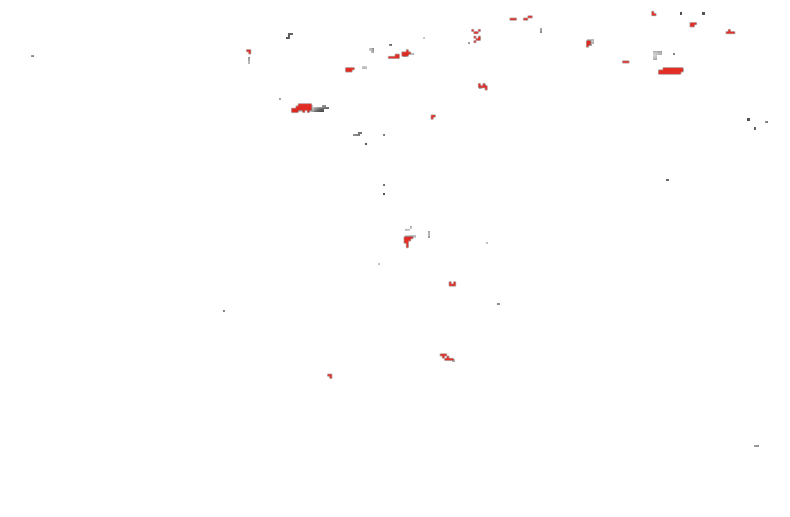

Calculating Normalized Differential Activity Index treshold ...
  pair 1/18: 2024.04.03 - 2024.04.15
    searching for Sentinel-2 images ...
      date range: 2024-04-16 - 2024-05-15
      Sentinel-2 scene selected: 2024.05.01 20240501T095031_20240501T095031_T34UDA
    water mask from NDWI, NDWI >= -0.1  ...
    vegetation mask from NDVI and SWIR, NDVI >= 0.40 and B11 < 0.26 ...
  pair 2/18: 2024.04.15 - 2024.04.27
    searching for Sentinel-2 images ...
      date range: 2024-04-28 - 2024-05-27
      Sentinel-2 scene selected: 2024.05.01 20240501T095031_20240501T095031_T34UDA
    water mask from NDWI, NDWI >= -0.1  ...
    vegetation mask from NDVI and SWIR, NDVI >= 0.40 and B11 < 0.26 ...
  pair 3/18: 2024.04.27 - 2024.05.09
    searching for Sentinel-2 images ...
      date range: 2024-05-10 - 2024-06-09
      Sentinel-2 scene selected: 2024.05.13 20240513T093549_20240513T093835_T34UDA
    water mask from NDWI, NDWI >= -0.1  ...
    vegetation mask from NDVI and SWIR, NDVI >= 0.40 a

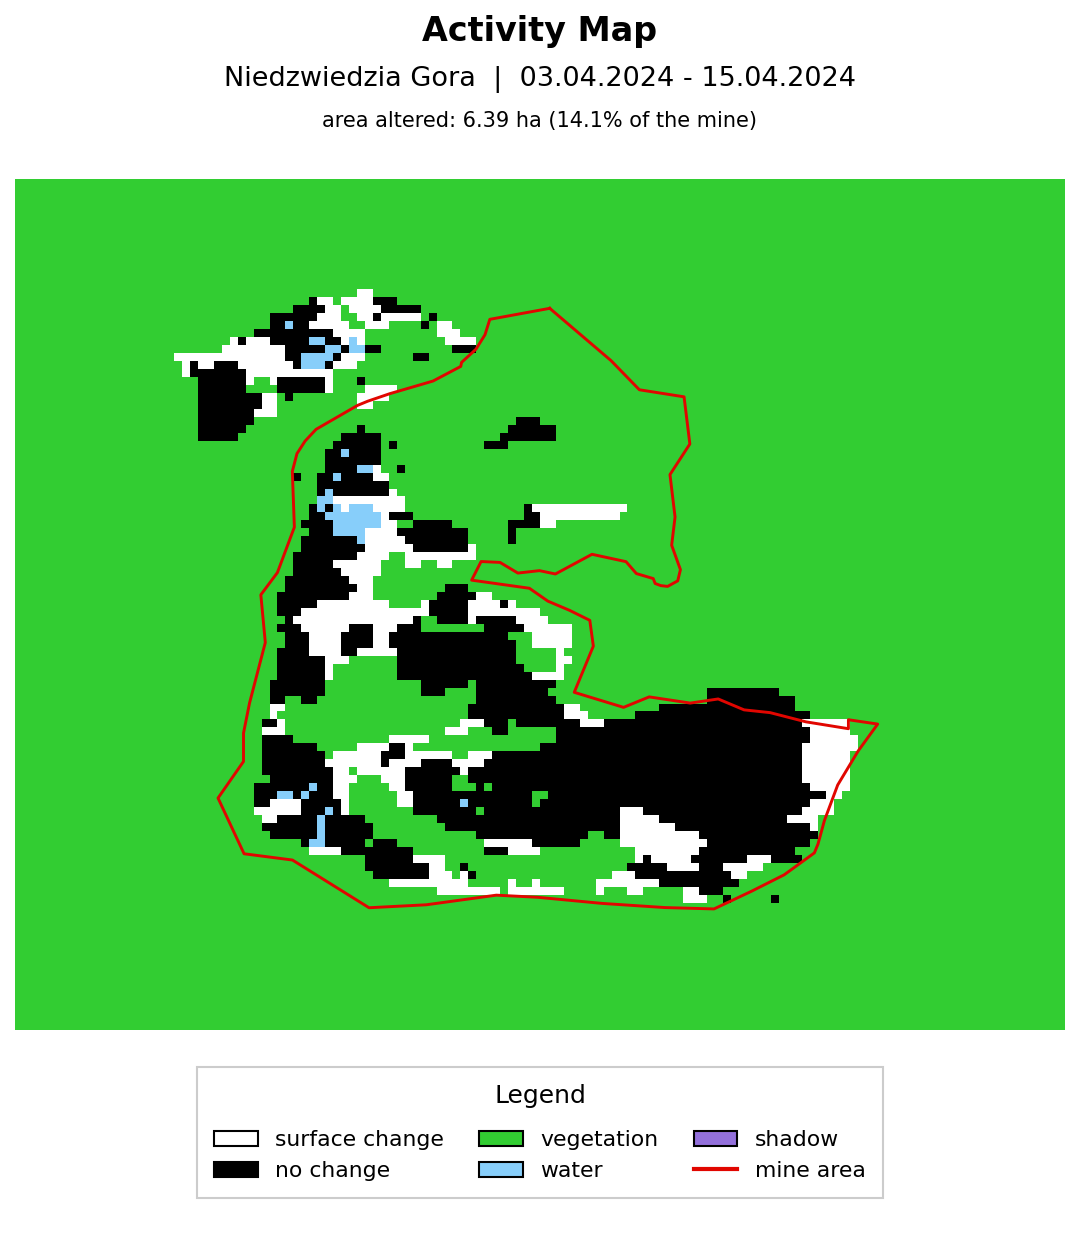

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.03-2024.04.15_activity_map.png


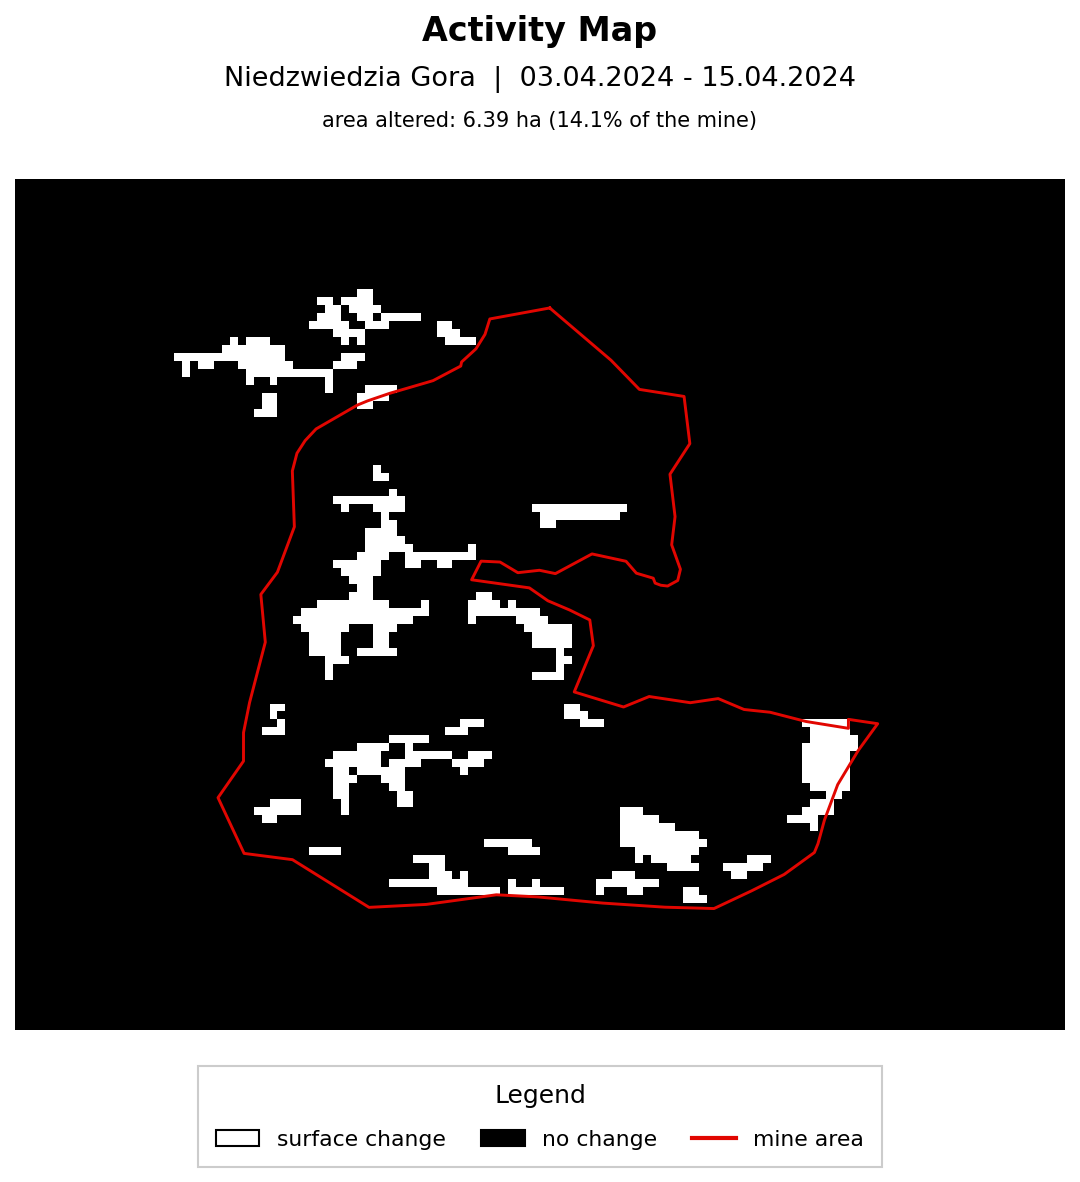

    searching for Sentinel-2 images ...
      date range: 2024-03-03 - 2024-04-02
    Sentinel-2 image scelected: 2024.03.29 20240329T094031_20240329T094030_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-04-16 - 2024-05-15
    Sentinel-2 image scelected: 2024.05.01 20240501T095031_20240501T095031_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.03-2024.04.15_activity_map_optical_images.png


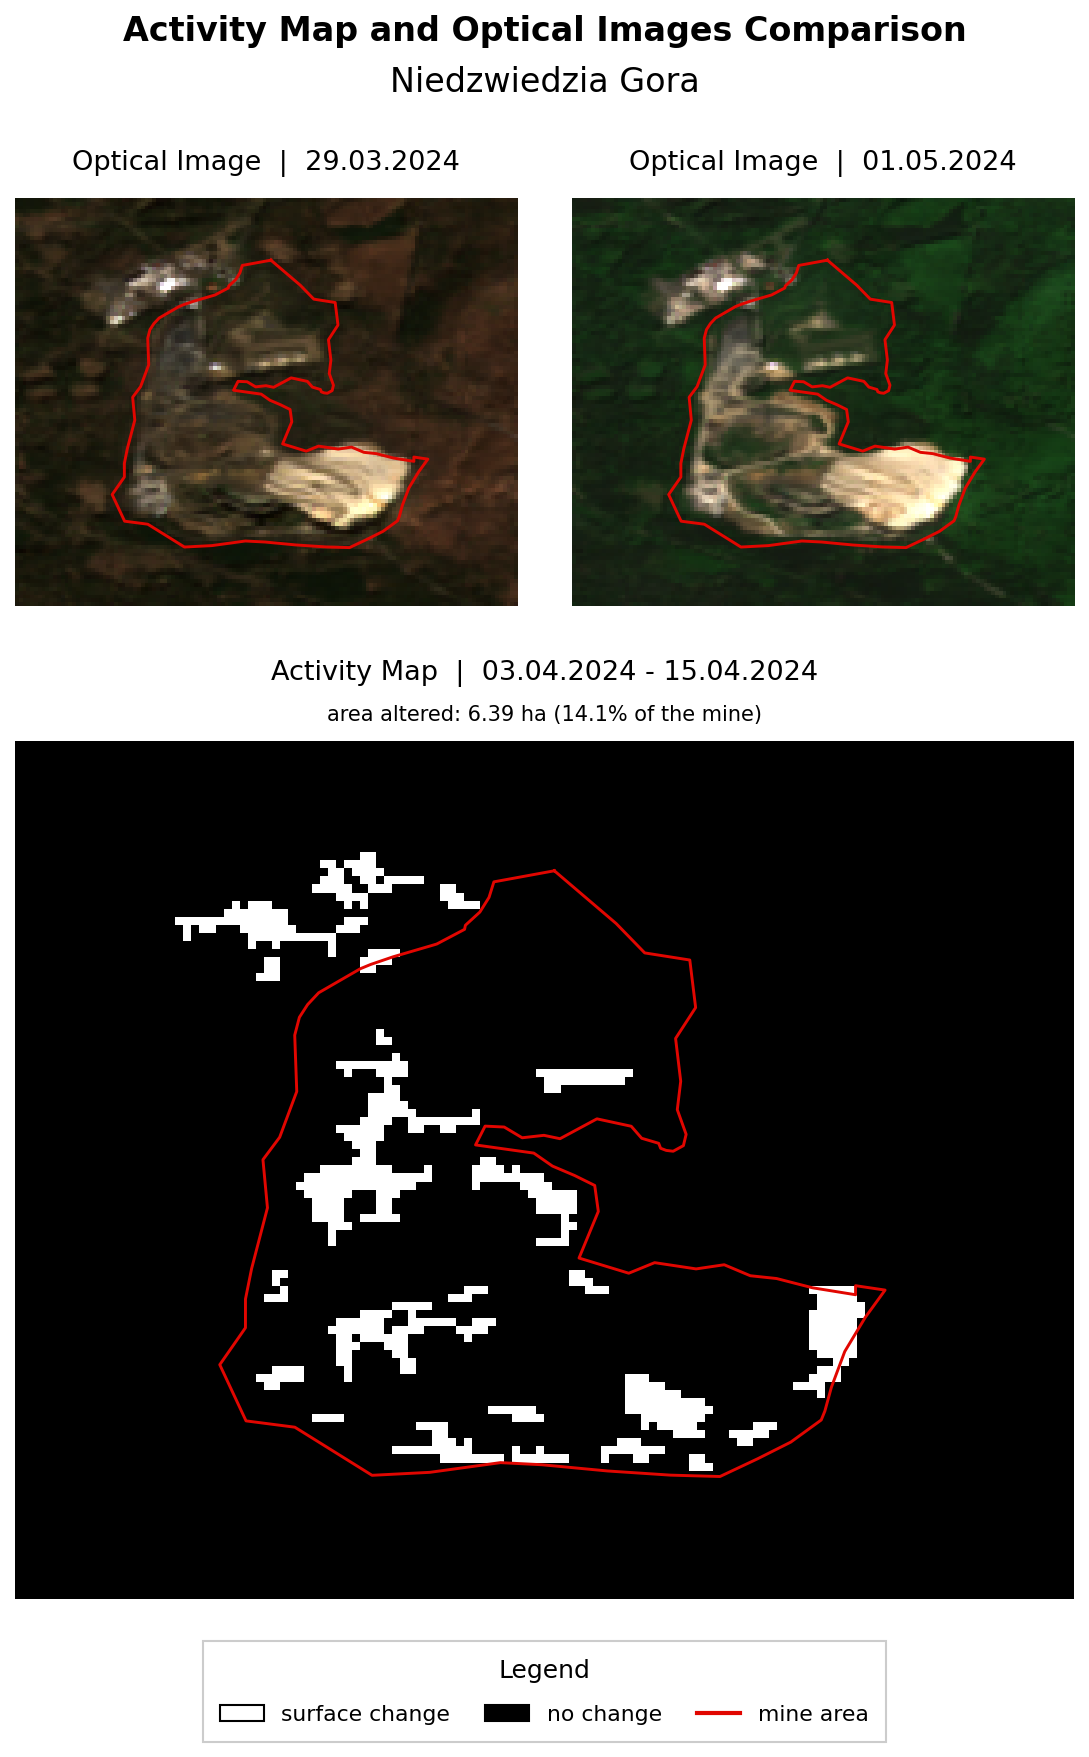

  pair 2/18: 2024.04.15 - 2024.04.27
    area changed inside the polygon: 73462 m2, 16.3% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.15-2024.04.27_activity_map_with_mask.png


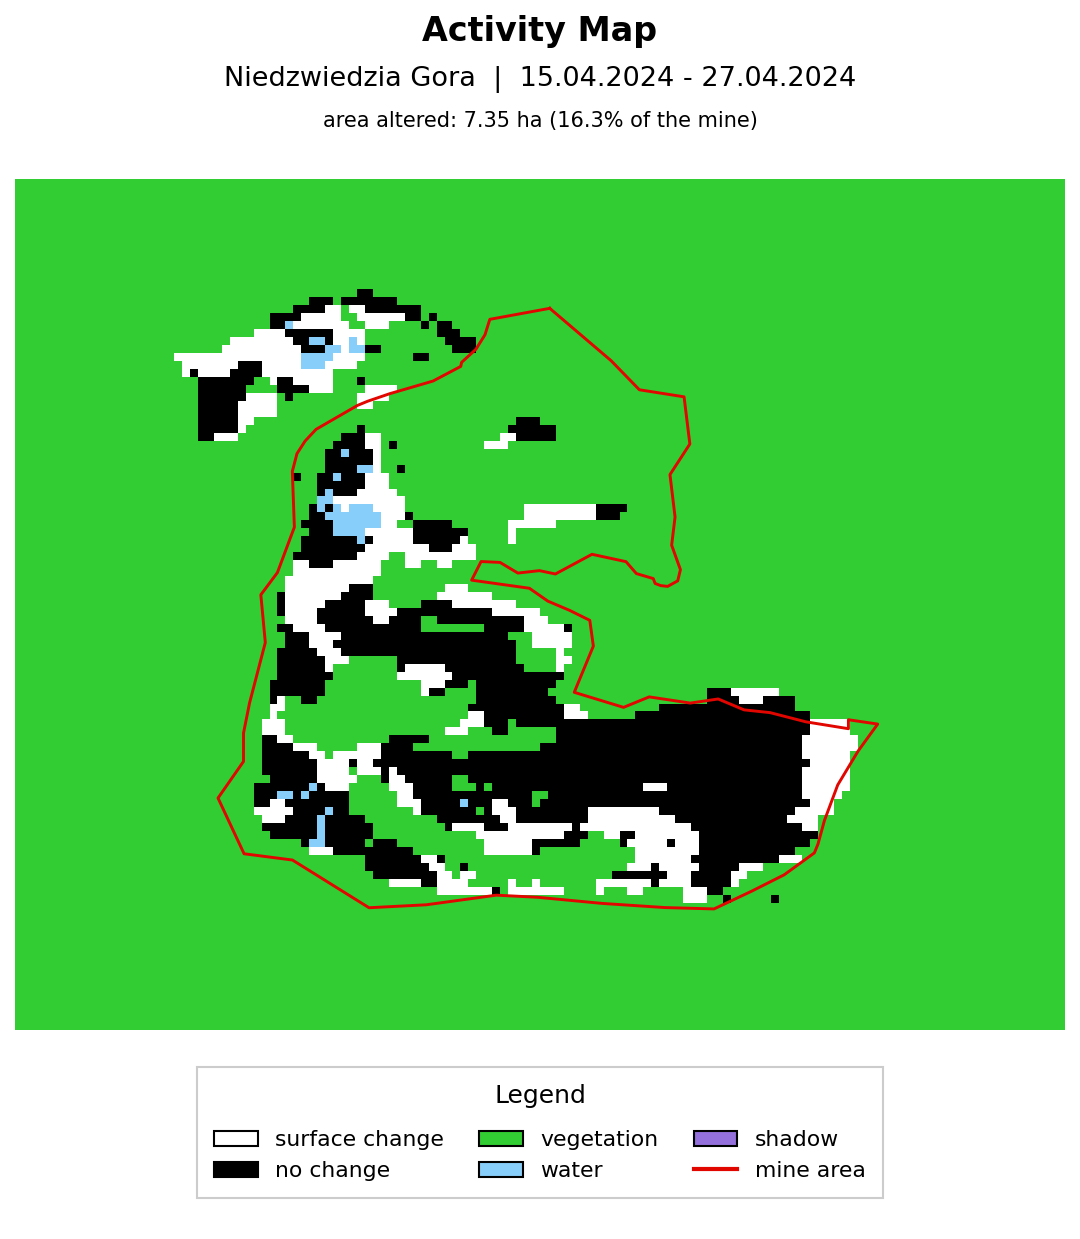

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.15-2024.04.27_activity_map.png


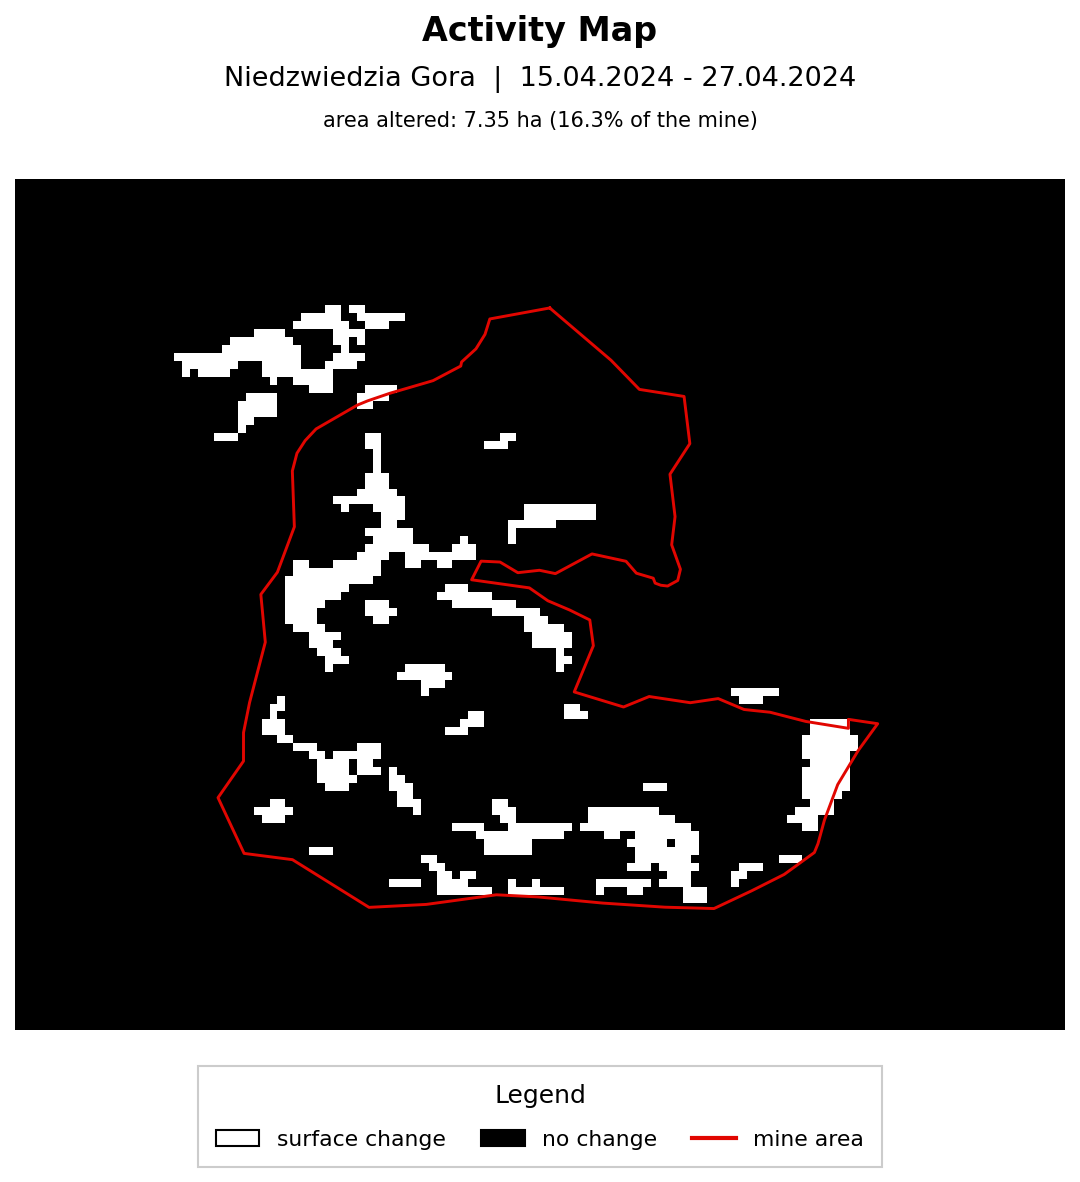

    searching for Sentinel-2 images ...
      date range: 2024-03-15 - 2024-04-14
    Sentinel-2 image scelected: 2024.04.08 20240408T094031_20240408T094030_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-04-28 - 2024-05-27
    Sentinel-2 image scelected: 2024.05.01 20240501T095031_20240501T095031_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.15-2024.04.27_activity_map_optical_images.png


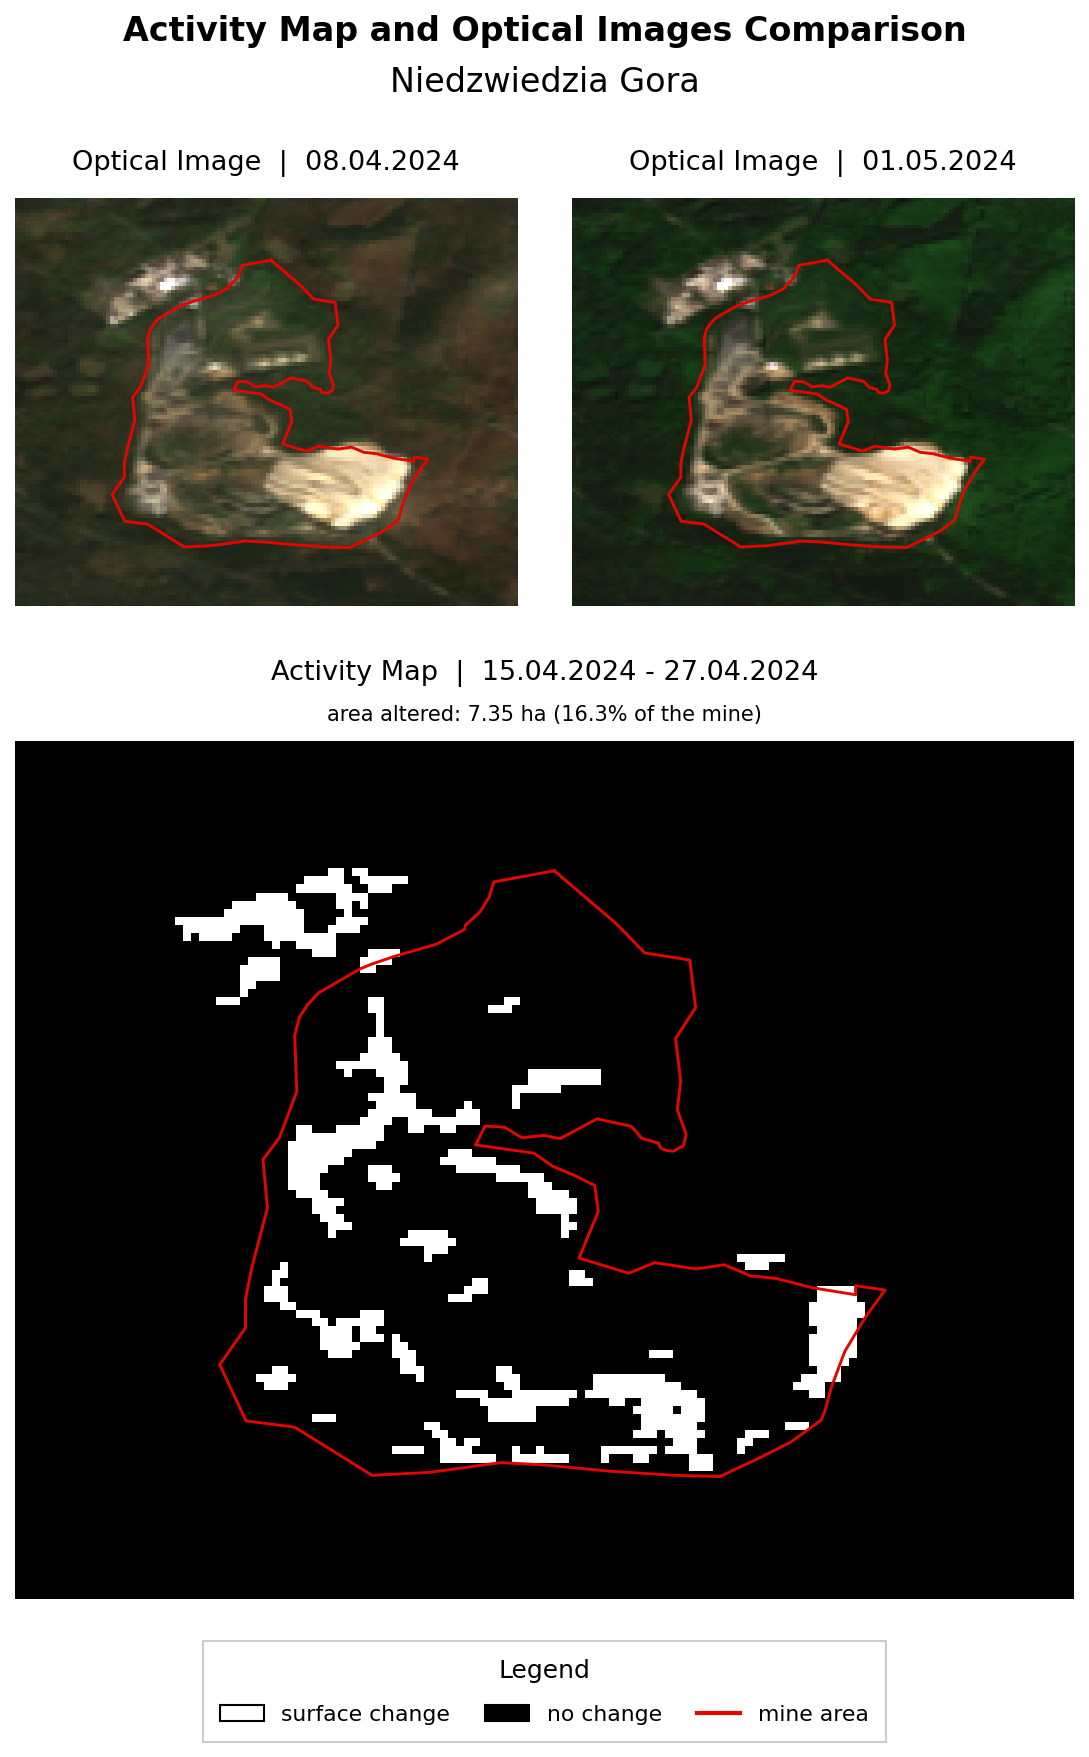

  pair 3/18: 2024.04.27 - 2024.05.09
    area changed inside the polygon: 71345 m2, 15.8% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.27-2024.05.09_activity_map_with_mask.png


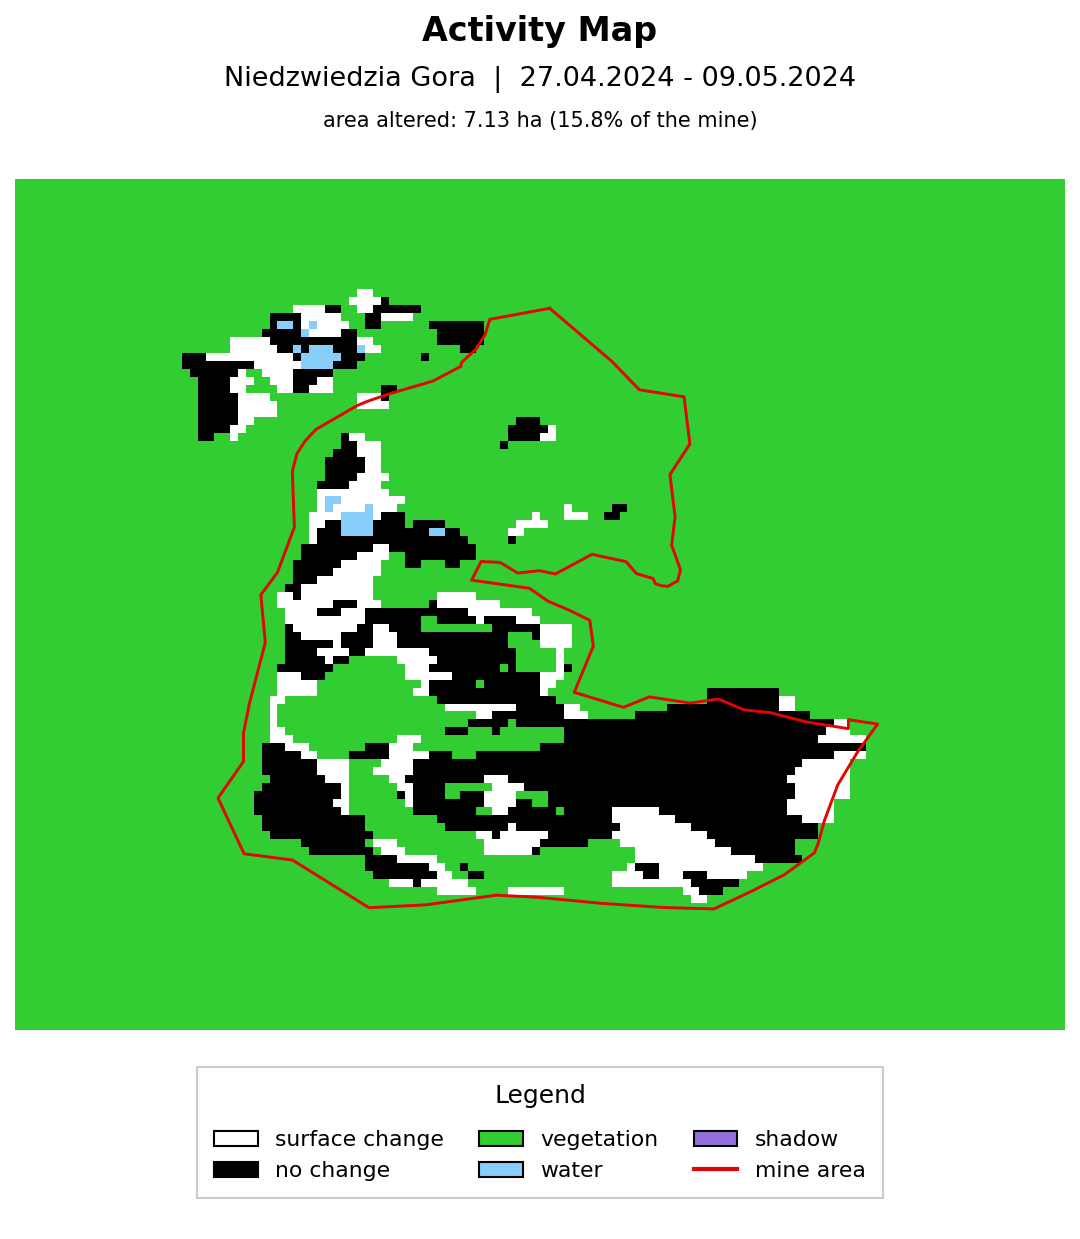

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.27-2024.05.09_activity_map.png


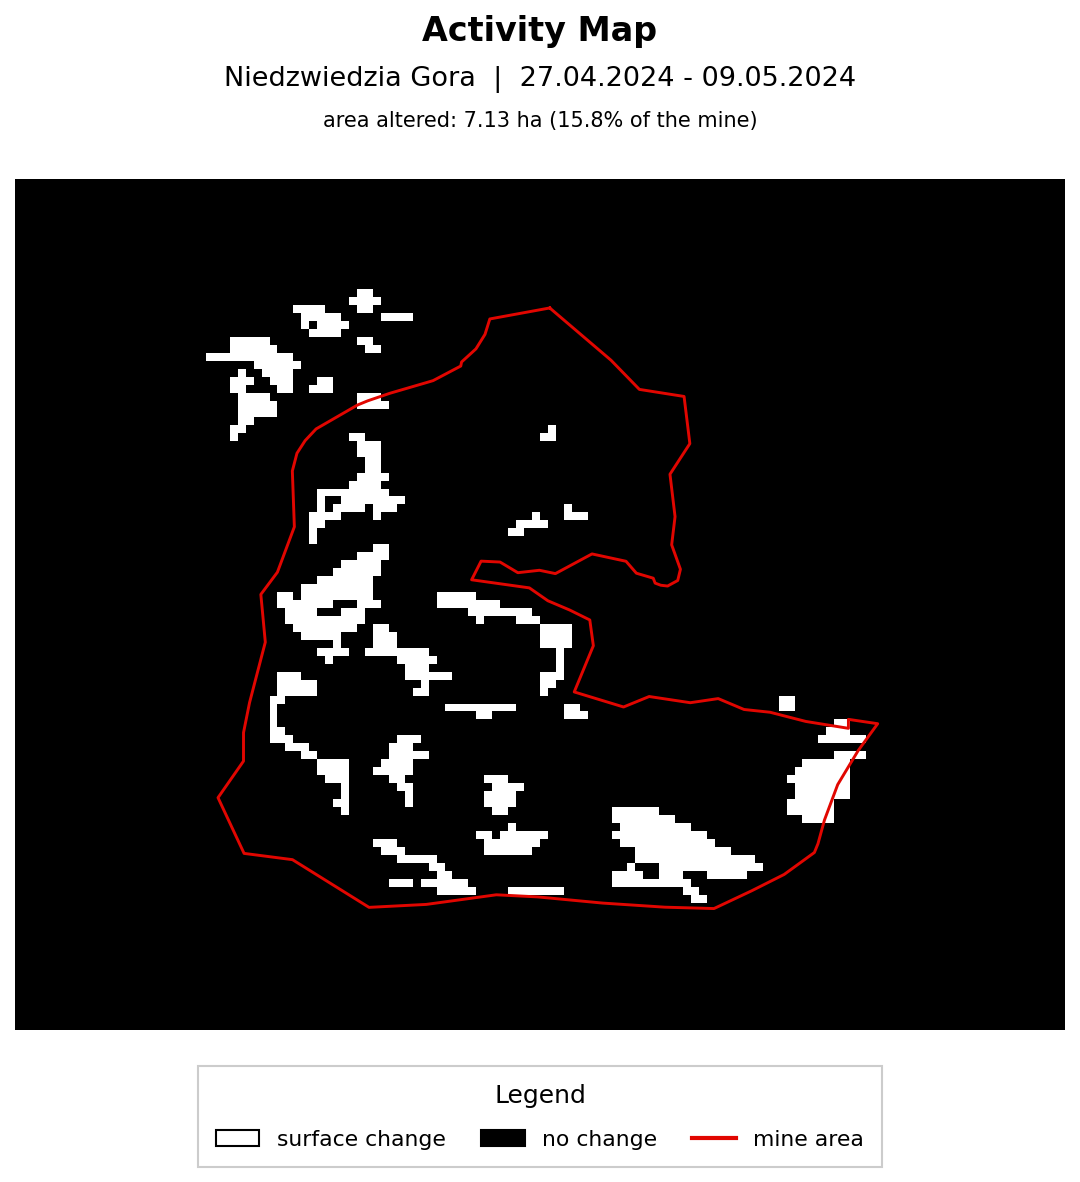

    searching for Sentinel-2 images ...
      date range: 2024-03-27 - 2024-04-26
    Sentinel-2 image scelected: 2024.04.08 20240408T094031_20240408T094030_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-05-10 - 2024-06-09
    Sentinel-2 image scelected: 2024.05.13 20240513T093549_20240513T093835_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.04.27-2024.05.09_activity_map_optical_images.png


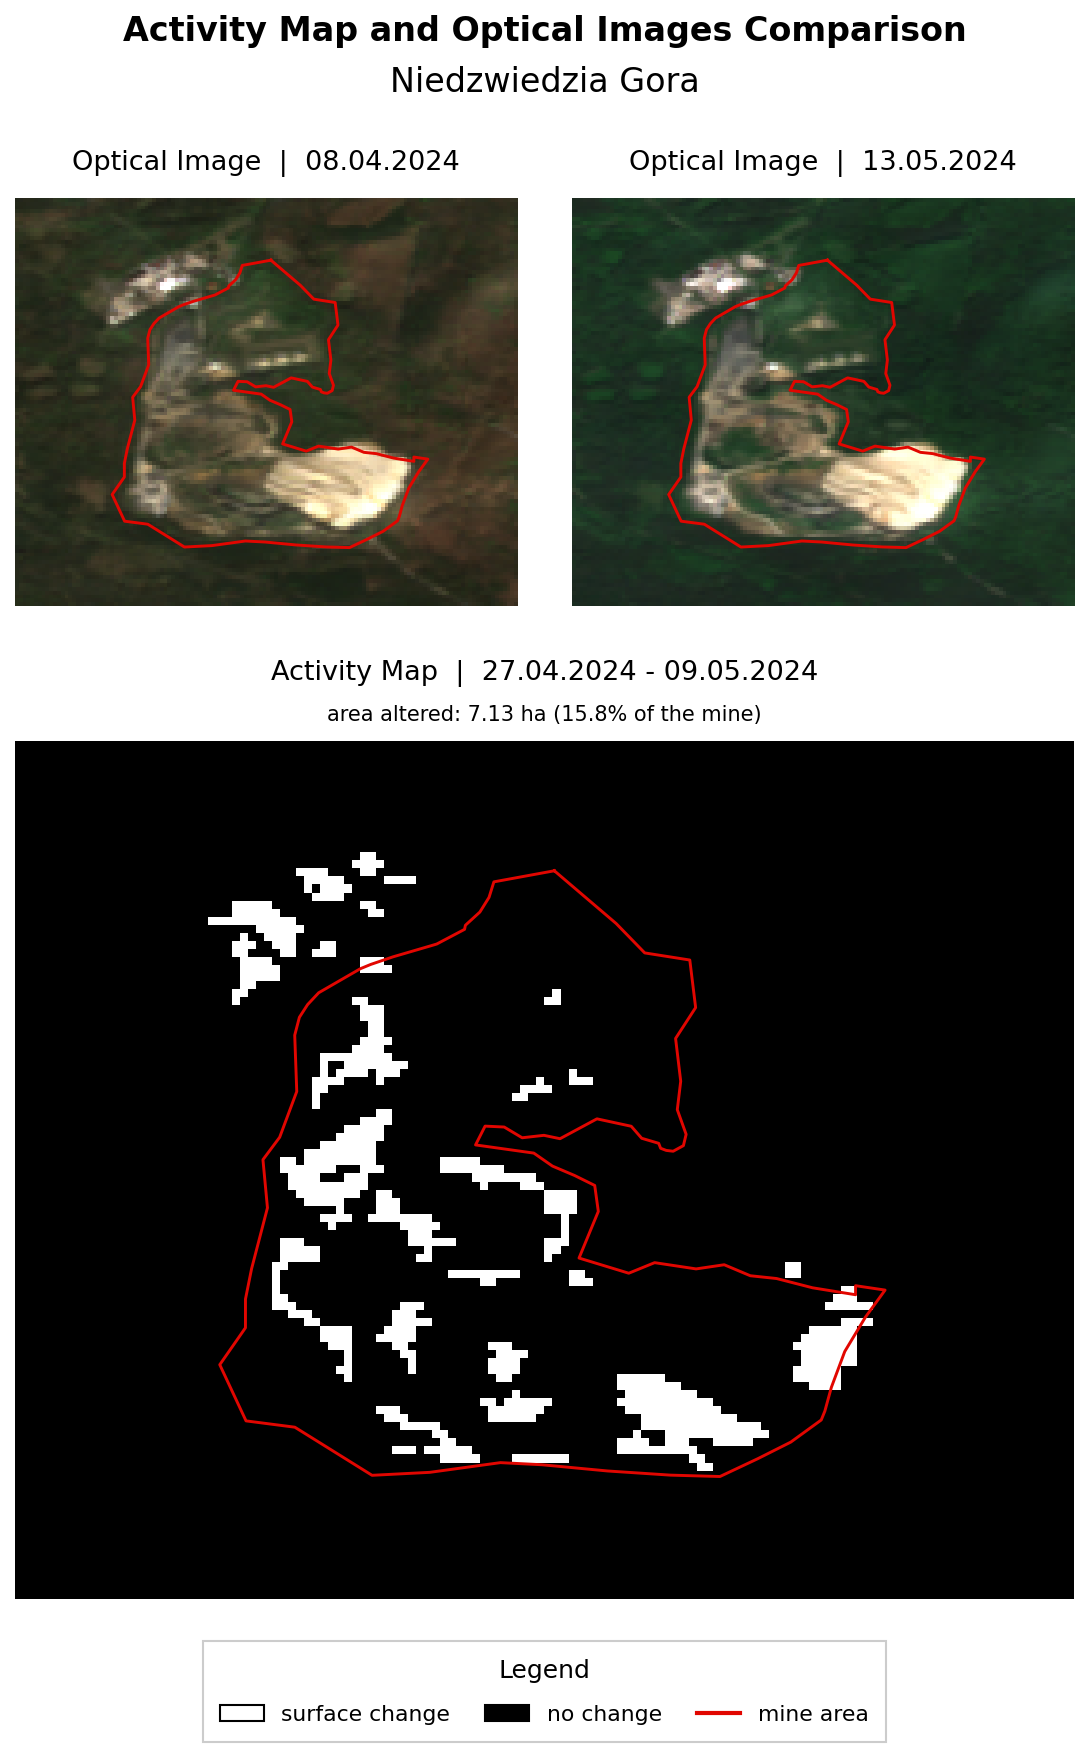

  pair 4/18: 2024.05.09 - 2024.05.21
    area changed inside the polygon: 76824 m2, 17.0% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.05.09-2024.05.21_activity_map_with_mask.png


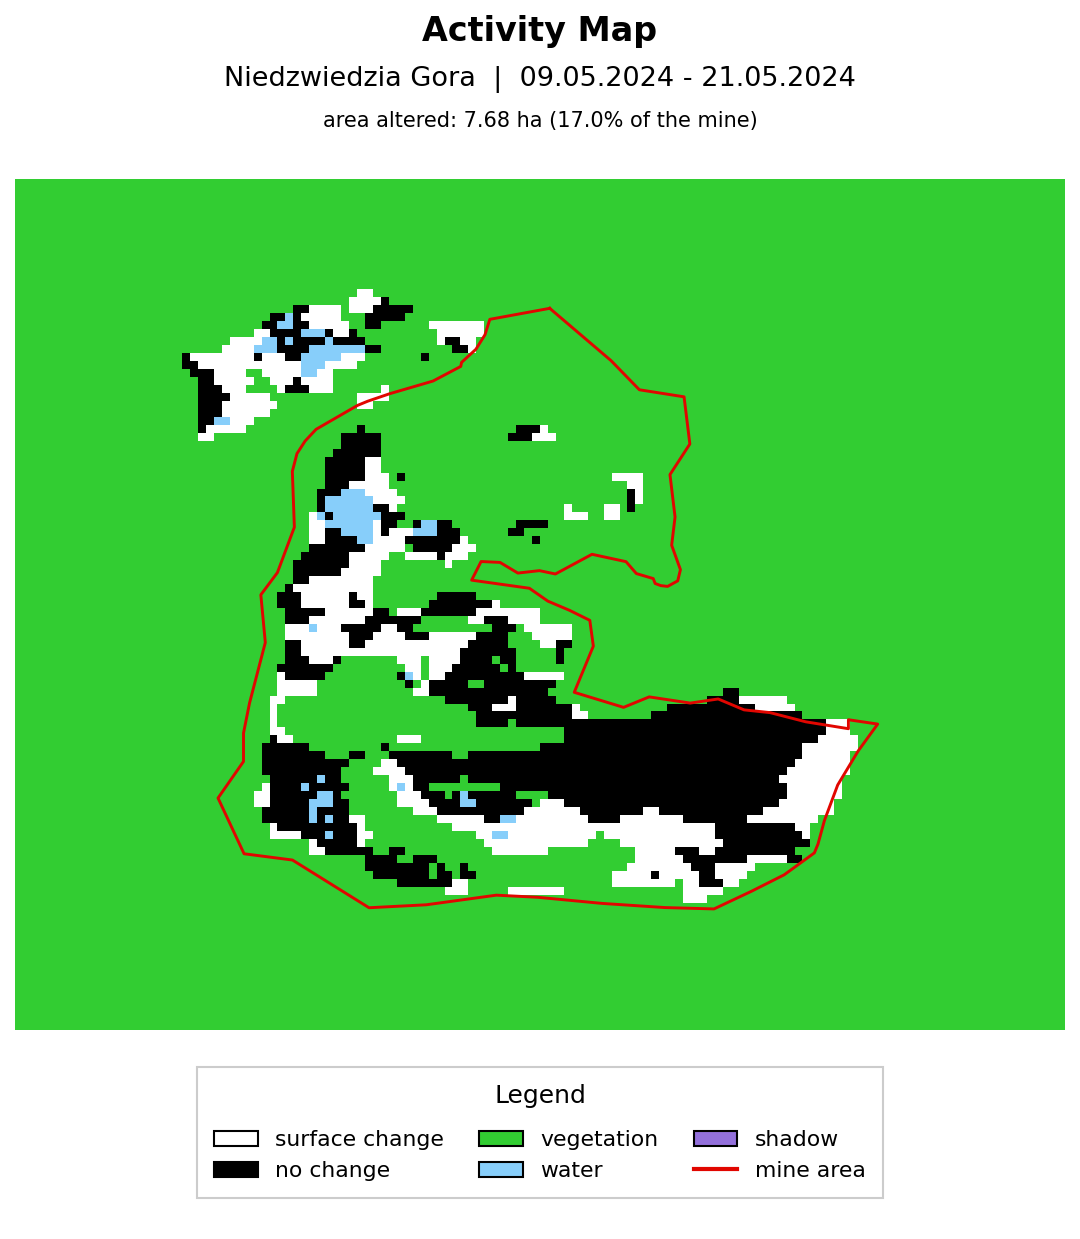

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.05.09-2024.05.21_activity_map.png


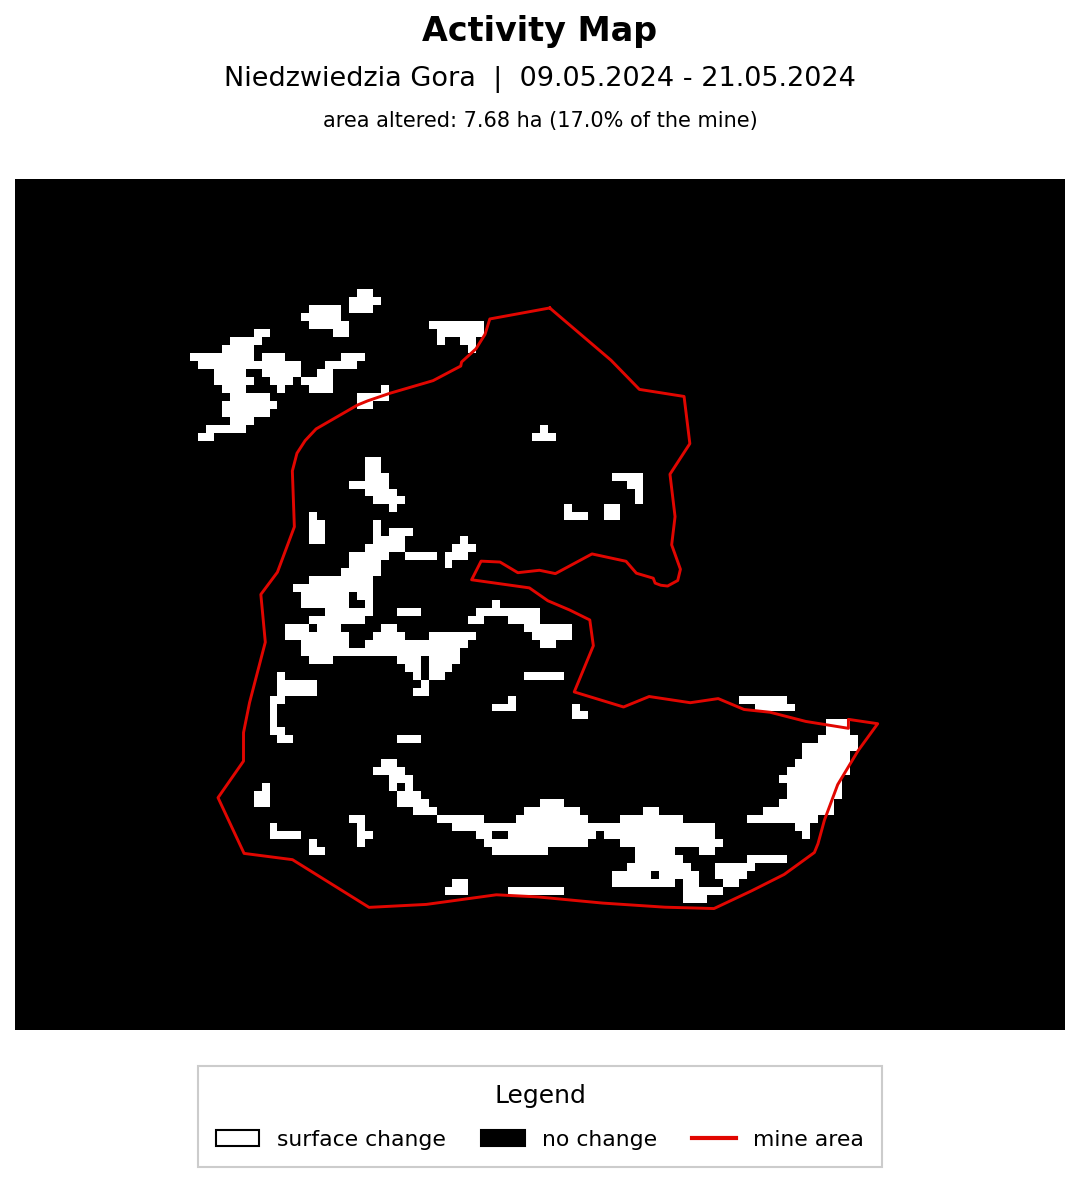

    searching for Sentinel-2 images ...
      date range: 2024-04-09 - 2024-05-08
    Sentinel-2 image scelected: 2024.05.03 20240503T093549_20240503T093836_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-05-22 - 2024-06-21
    Sentinel-2 image scelected: 2024.05.26 20240526T094549_20240526T094758_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.05.09-2024.05.21_activity_map_optical_images.png


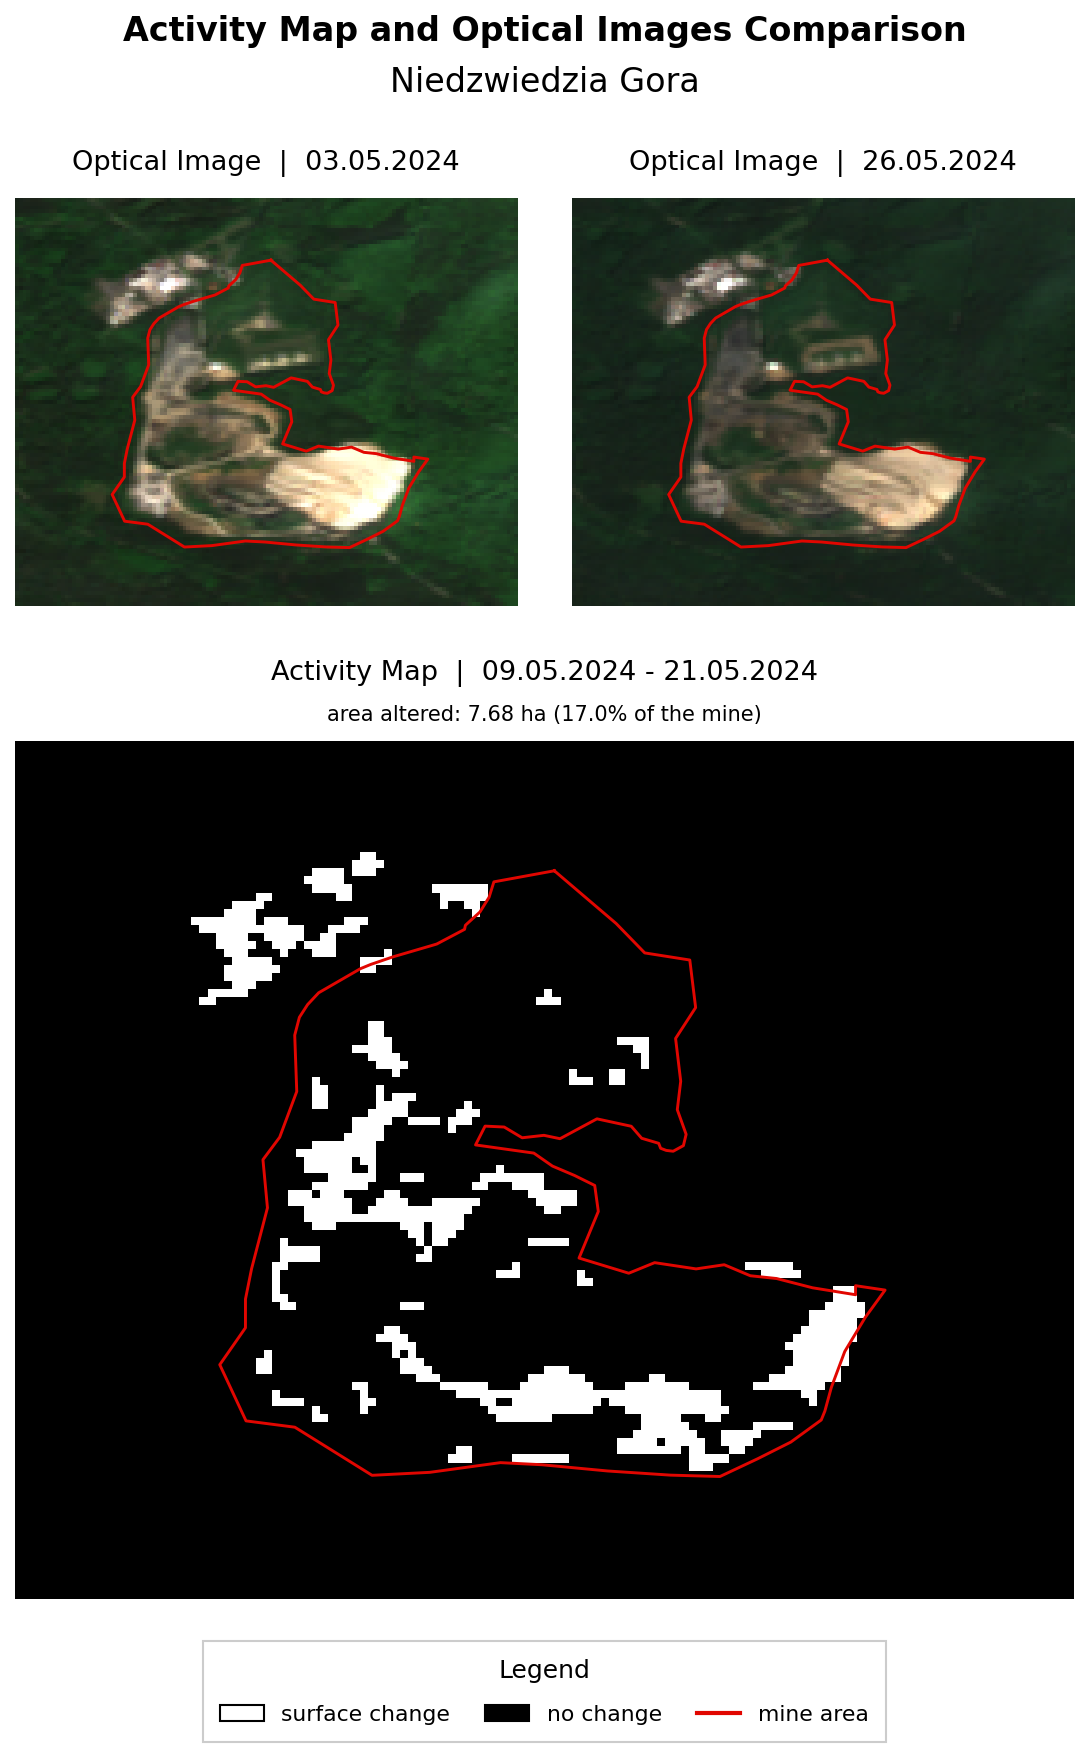

  pair 5/18: 2024.05.21 - 2024.06.02
    area changed inside the polygon: 141446 m2, 31.3% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.05.21-2024.06.02_activity_map_with_mask.png


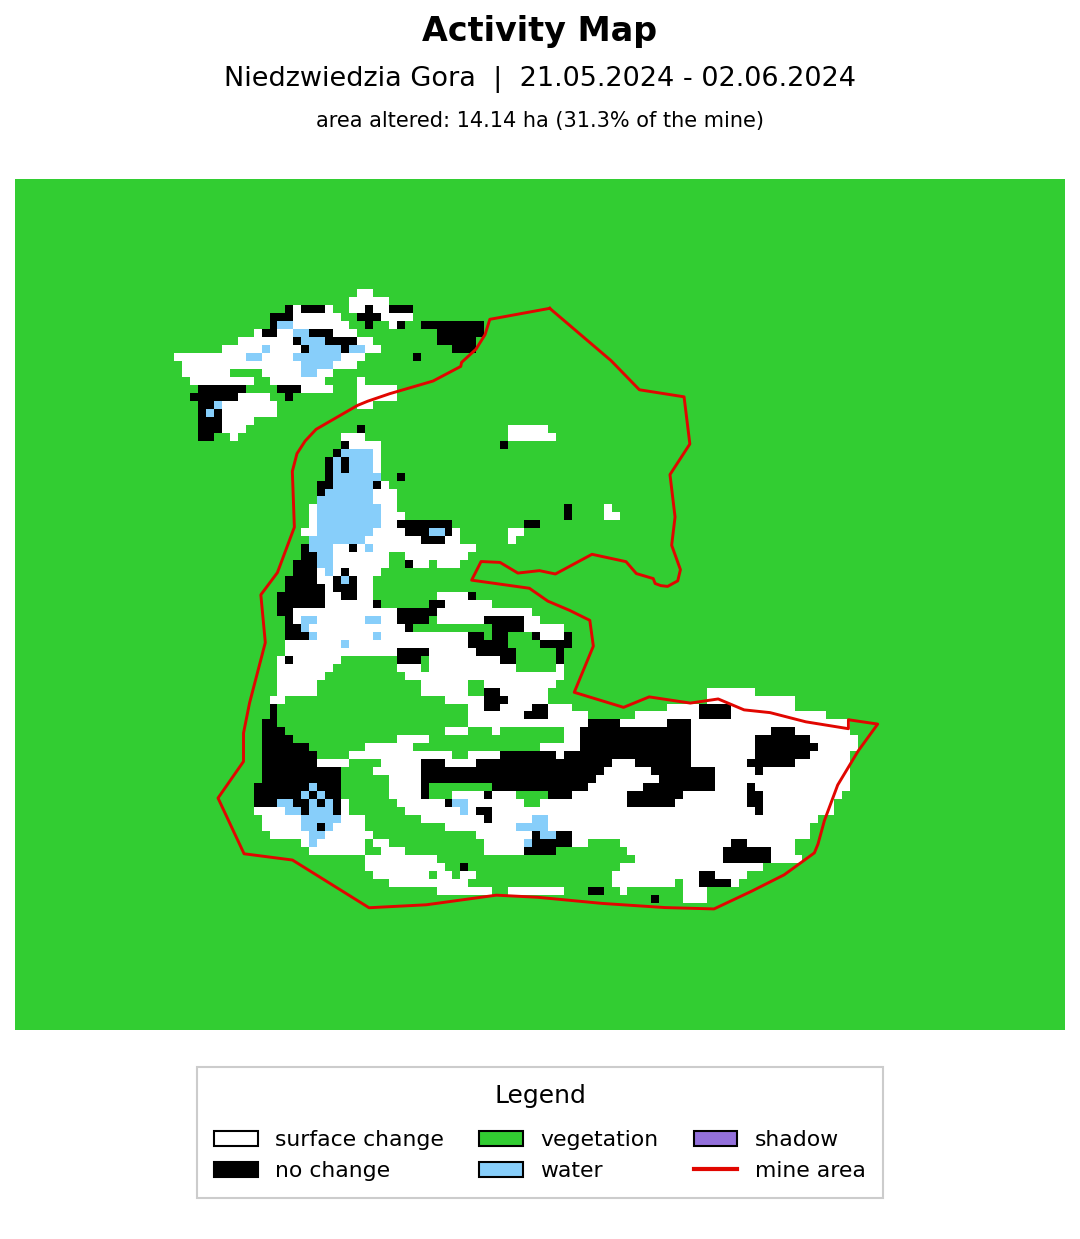

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.05.21-2024.06.02_activity_map.png


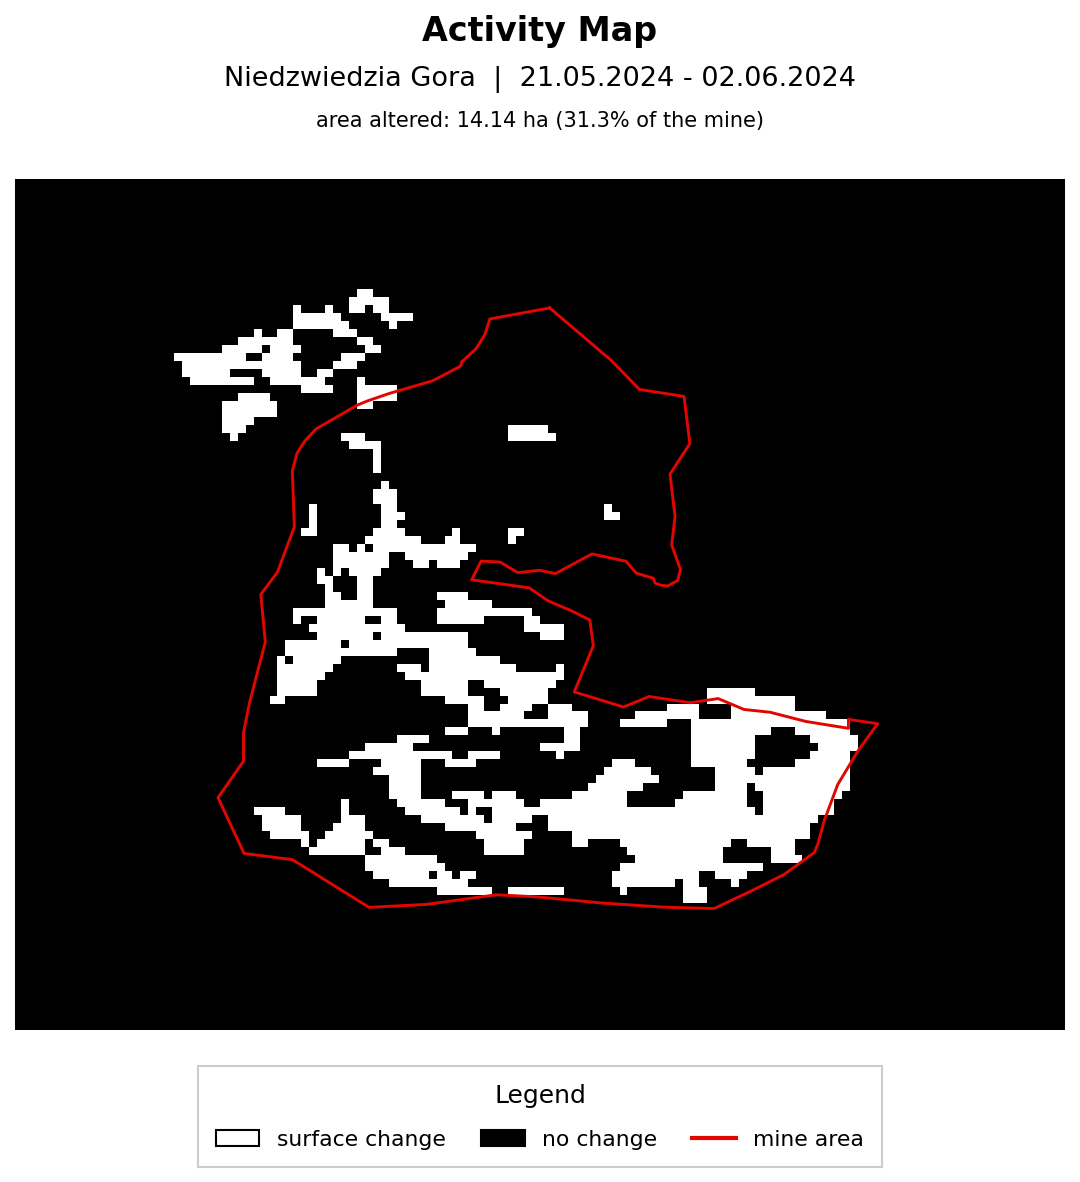

    searching for Sentinel-2 images ...
      date range: 2024-04-21 - 2024-05-20
    Sentinel-2 image scelected: 2024.05.13 20240513T093549_20240513T093835_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-06-03 - 2024-07-02
    Sentinel-2 image scelected: 2024.06.15 20240615T094549_20240615T094801_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.05.21-2024.06.02_activity_map_optical_images.png


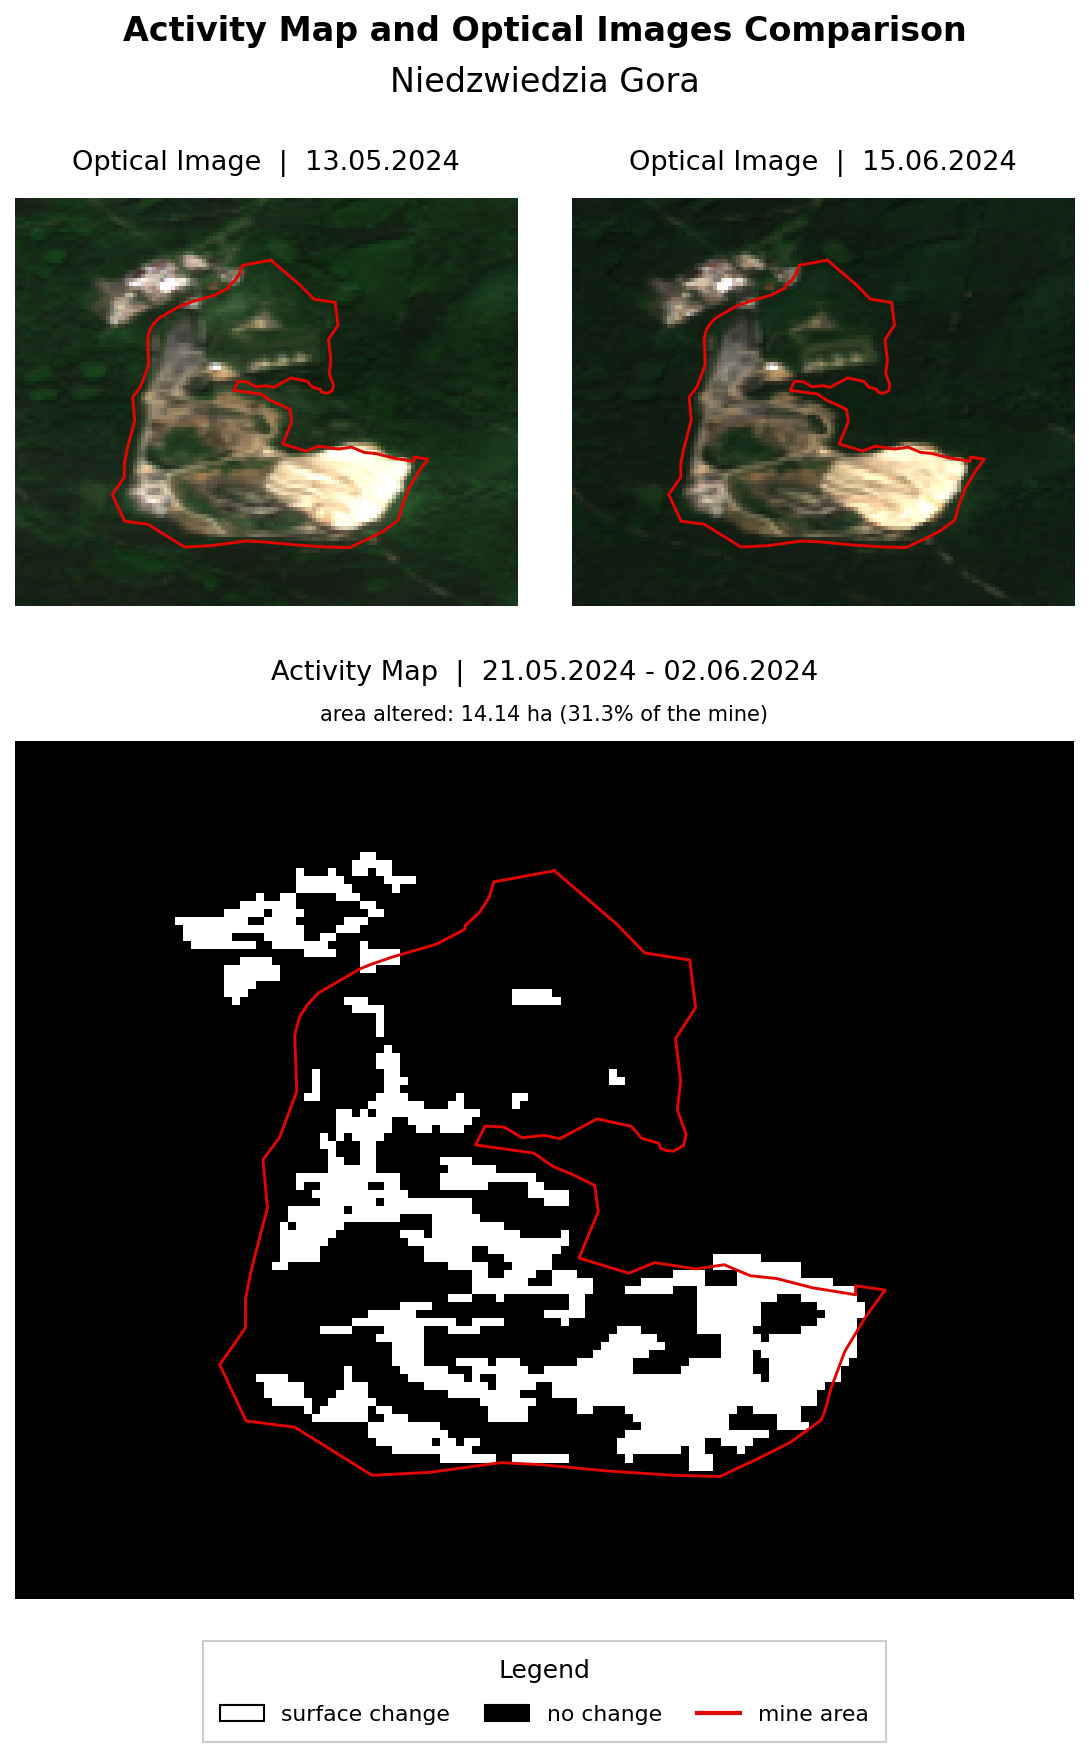

  pair 6/18: 2024.06.02 - 2024.06.14
    area changed inside the polygon: 83921 m2, 18.6% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.06.02-2024.06.14_activity_map_with_mask.png


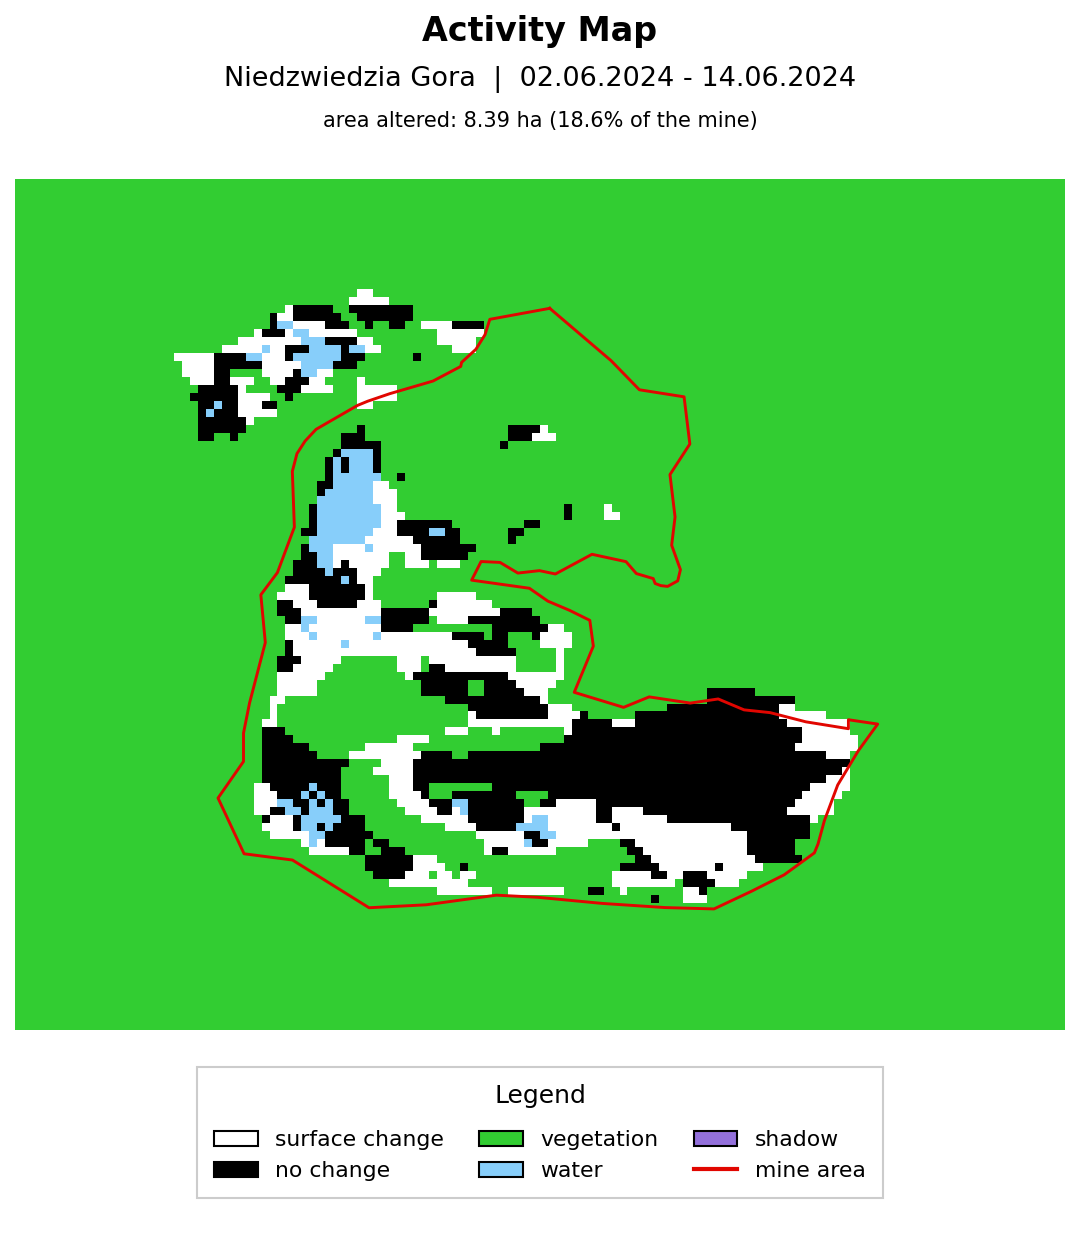

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.06.02-2024.06.14_activity_map.png


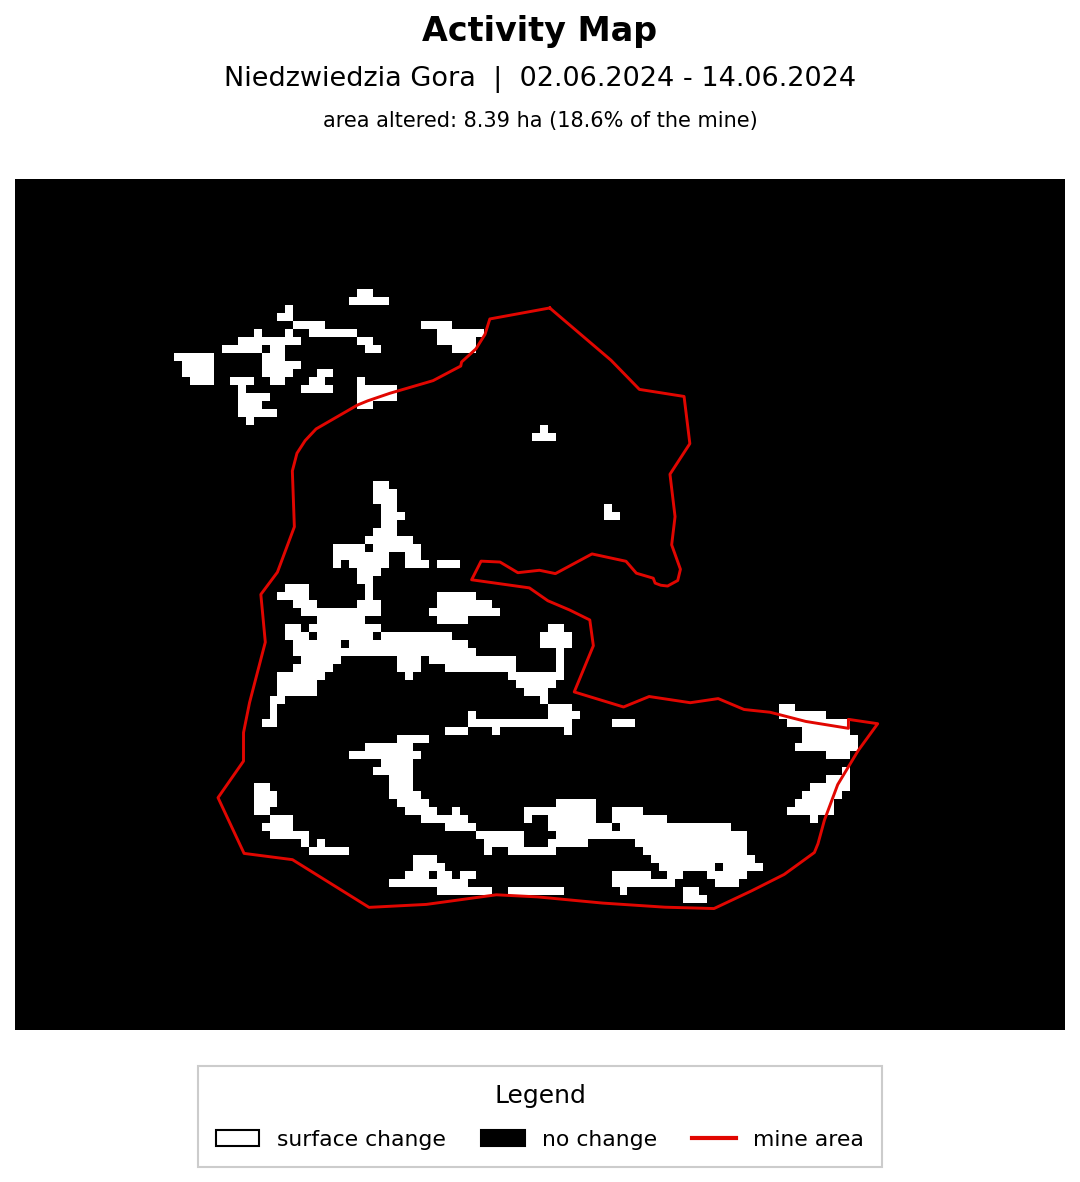

    searching for Sentinel-2 images ...
      date range: 2024-05-02 - 2024-06-01
    Sentinel-2 image scelected: 2024.05.28 20240528T094031_20240528T094033_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-06-15 - 2024-07-14
    Sentinel-2 image scelected: 2024.06.15 20240615T094549_20240615T094801_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.06.02-2024.06.14_activity_map_optical_images.png


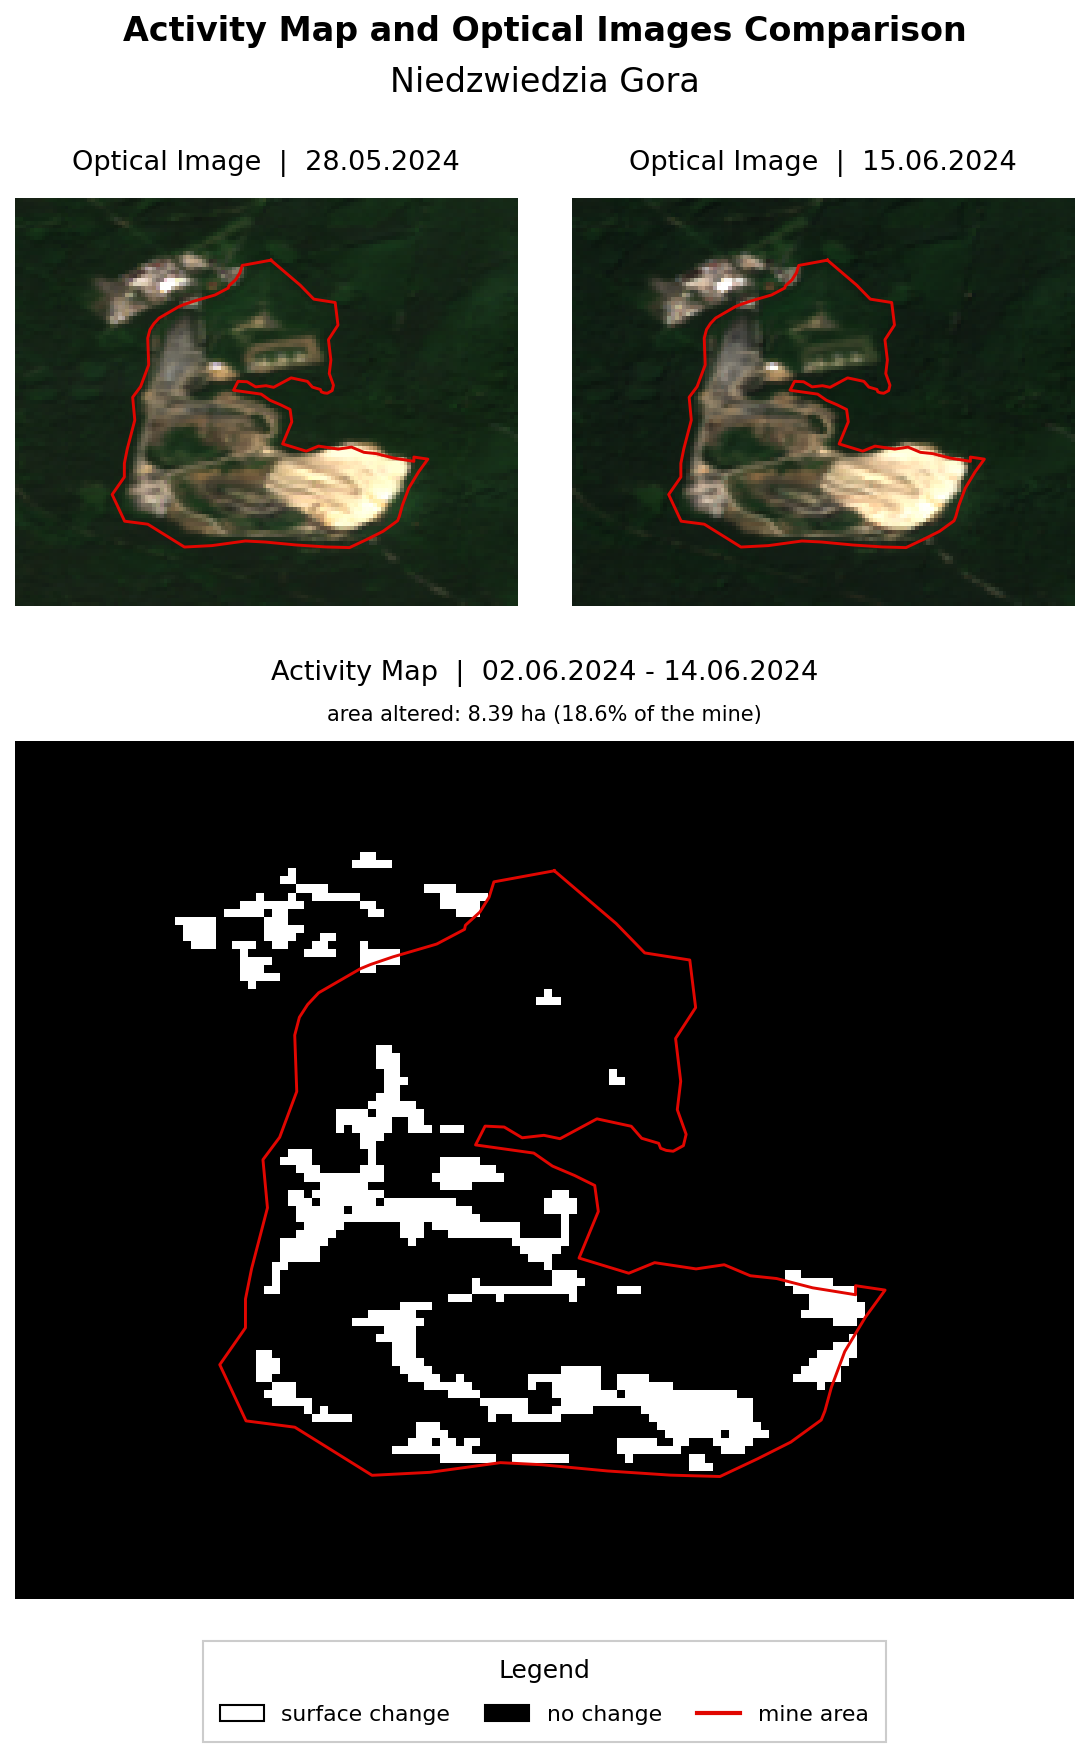

  pair 7/18: 2024.06.14 - 2024.06.26
    area changed inside the polygon: 91143 m2, 20.2% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.06.14-2024.06.26_activity_map_with_mask.png


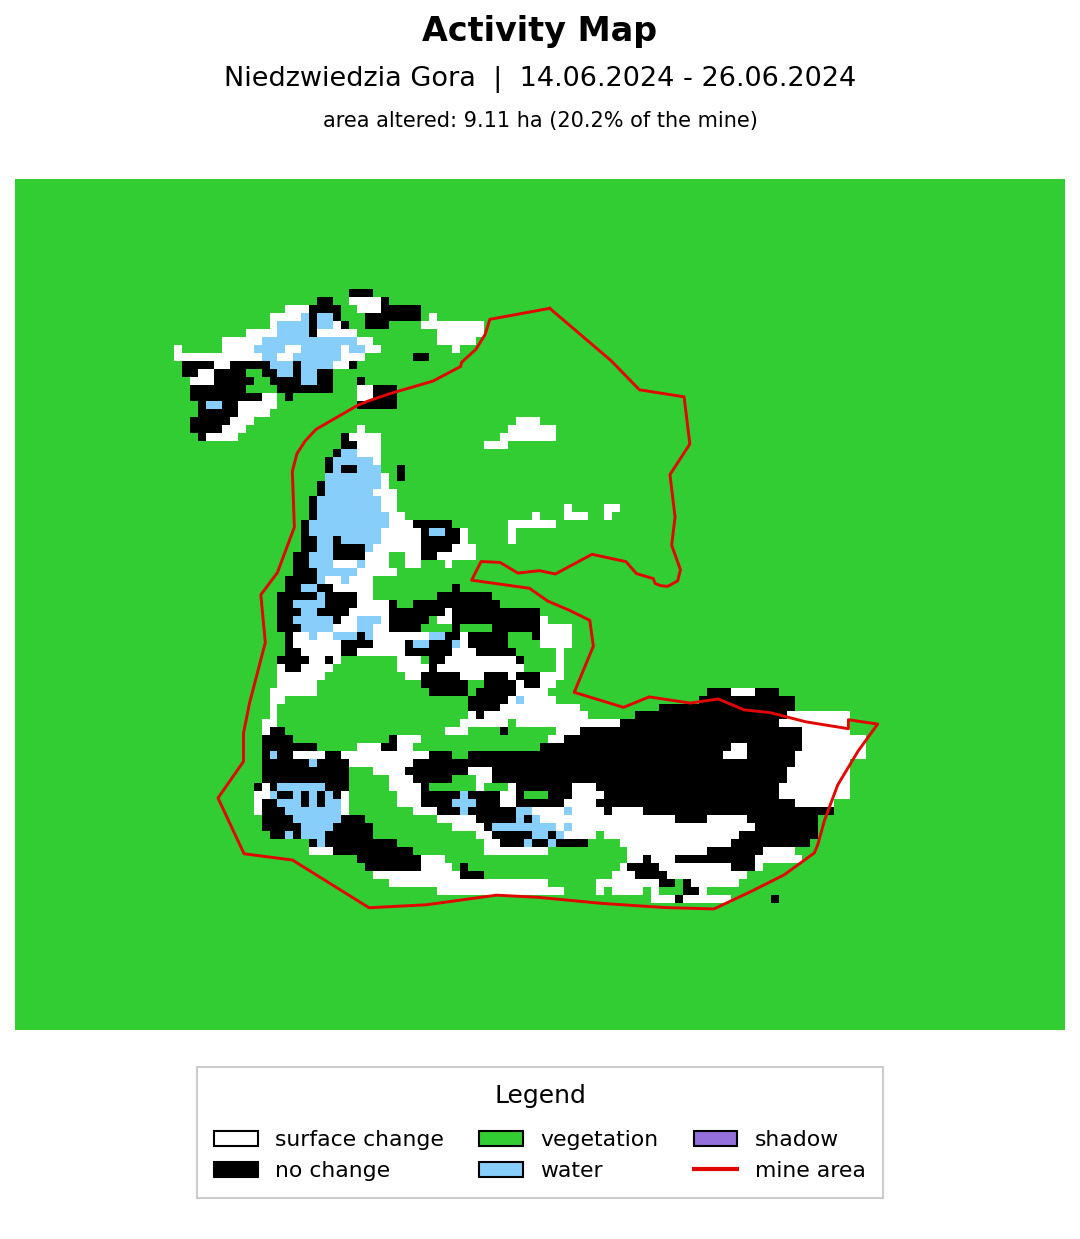

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.06.14-2024.06.26_activity_map.png


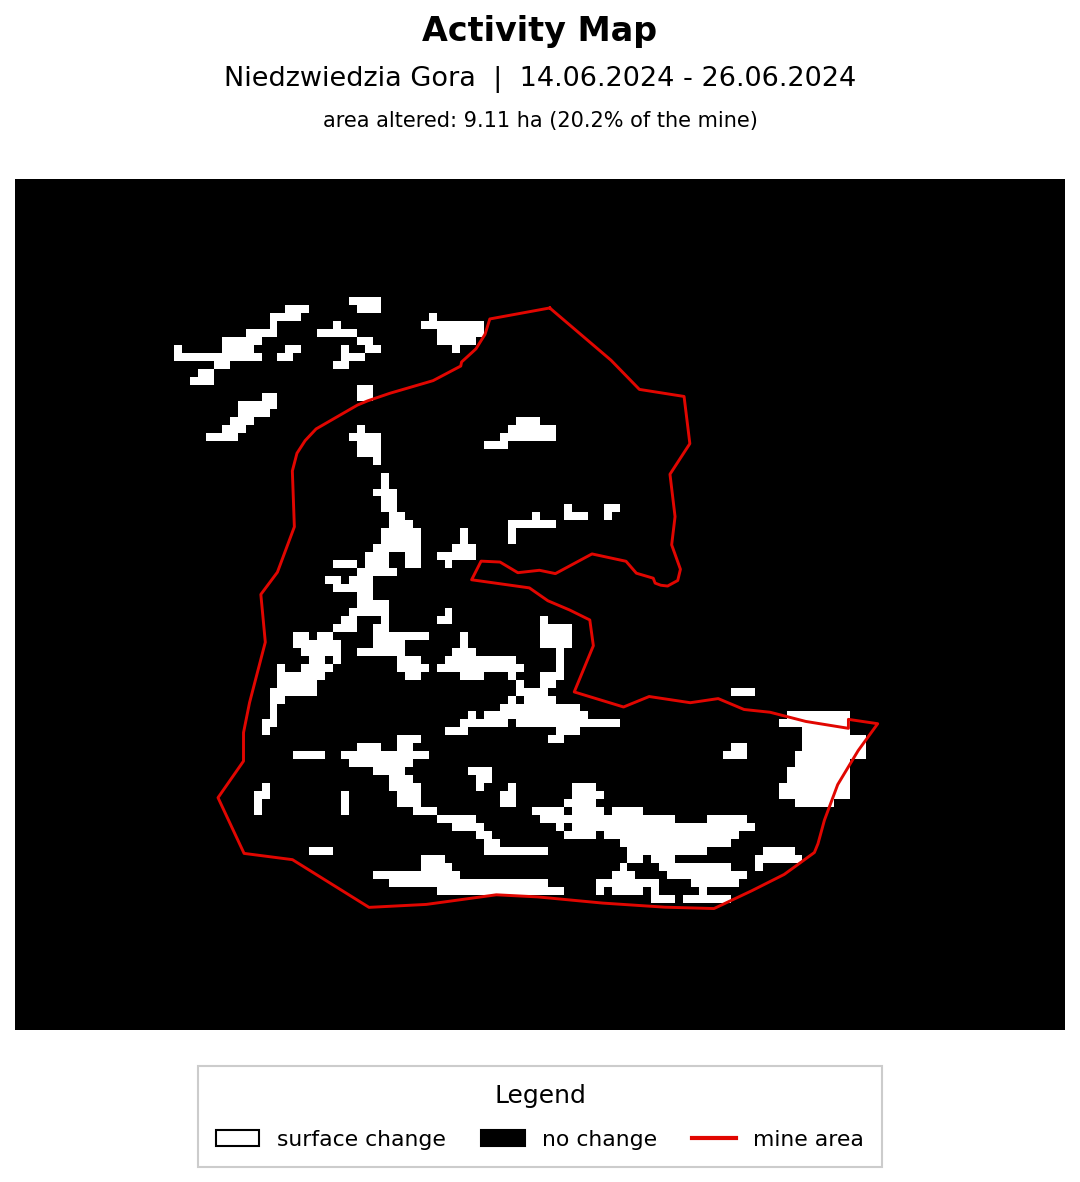

    searching for Sentinel-2 images ...
      date range: 2024-05-14 - 2024-06-13
    Sentinel-2 image scelected: 2024.05.28 20240528T094031_20240528T094033_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-06-27 - 2024-07-26
    Sentinel-2 image scelected: 2024.07.10 20240710T095031_20240710T095042_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.06.14-2024.06.26_activity_map_optical_images.png


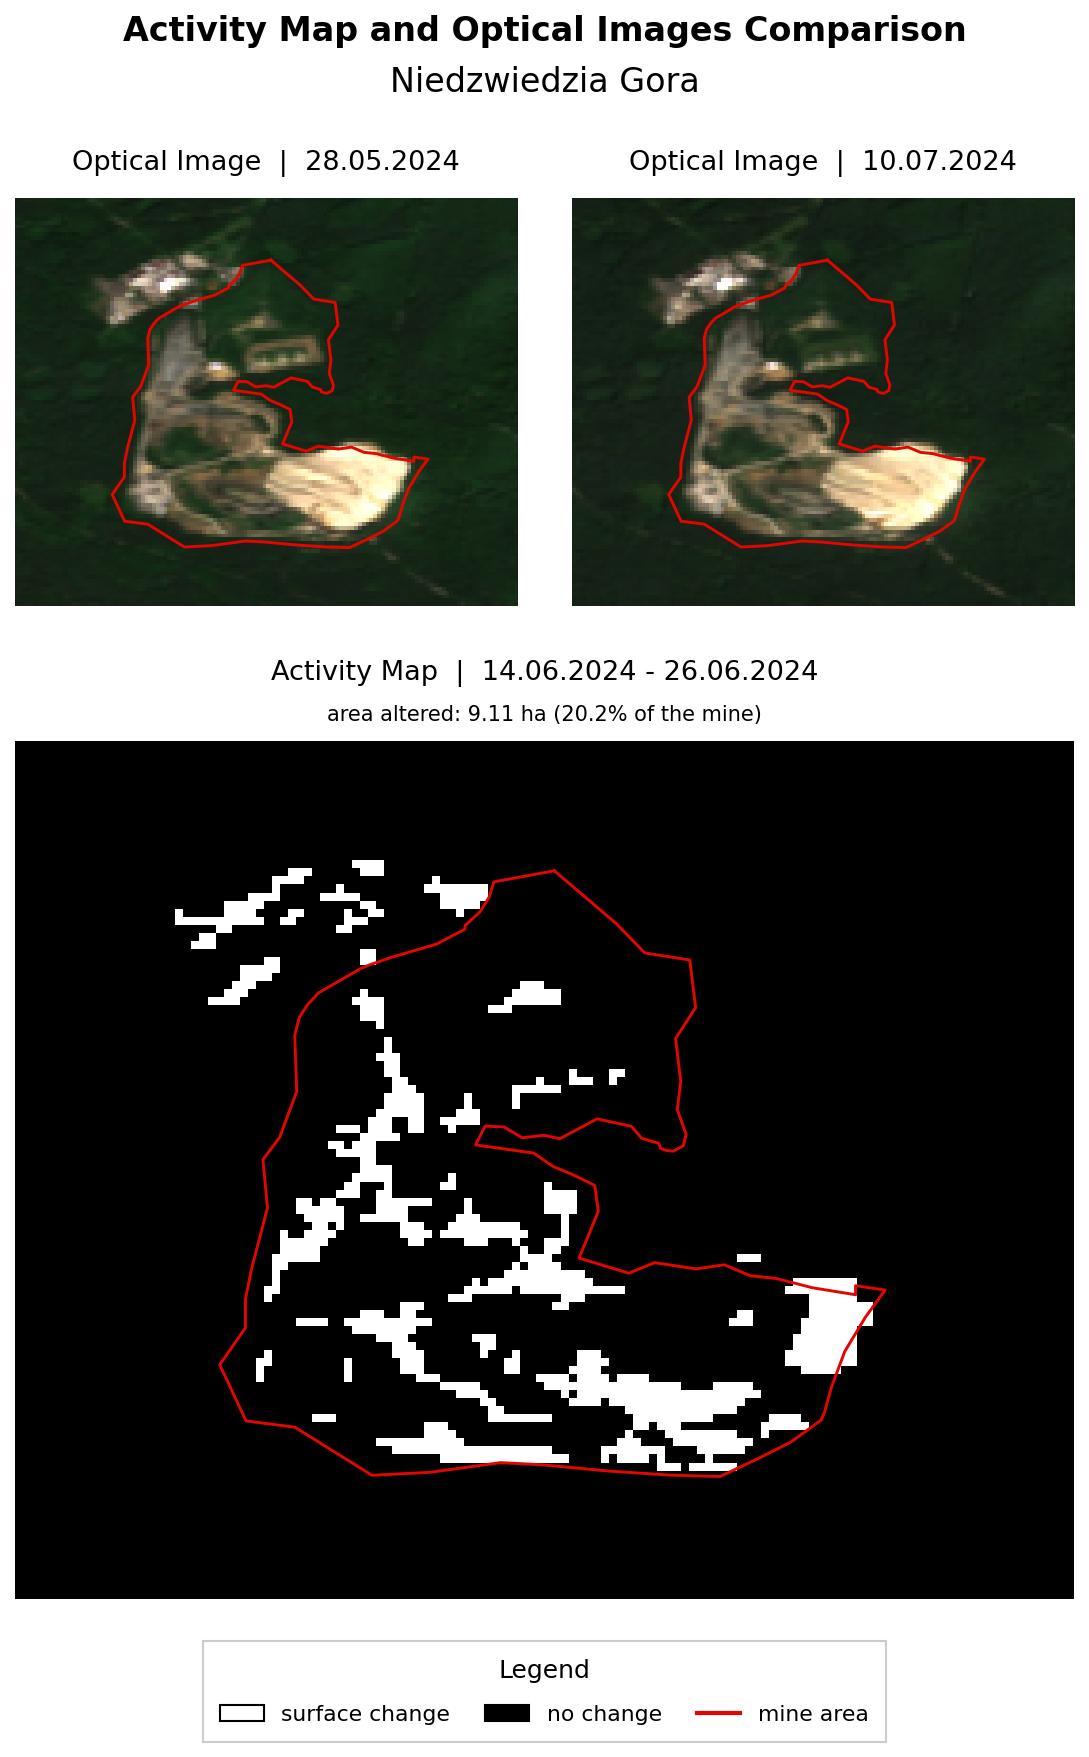

  pair 8/18: 2024.07.20 - 2024.08.01
    area changed inside the polygon: 81431 m2, 18.0% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.07.20-2024.08.01_activity_map_with_mask.png


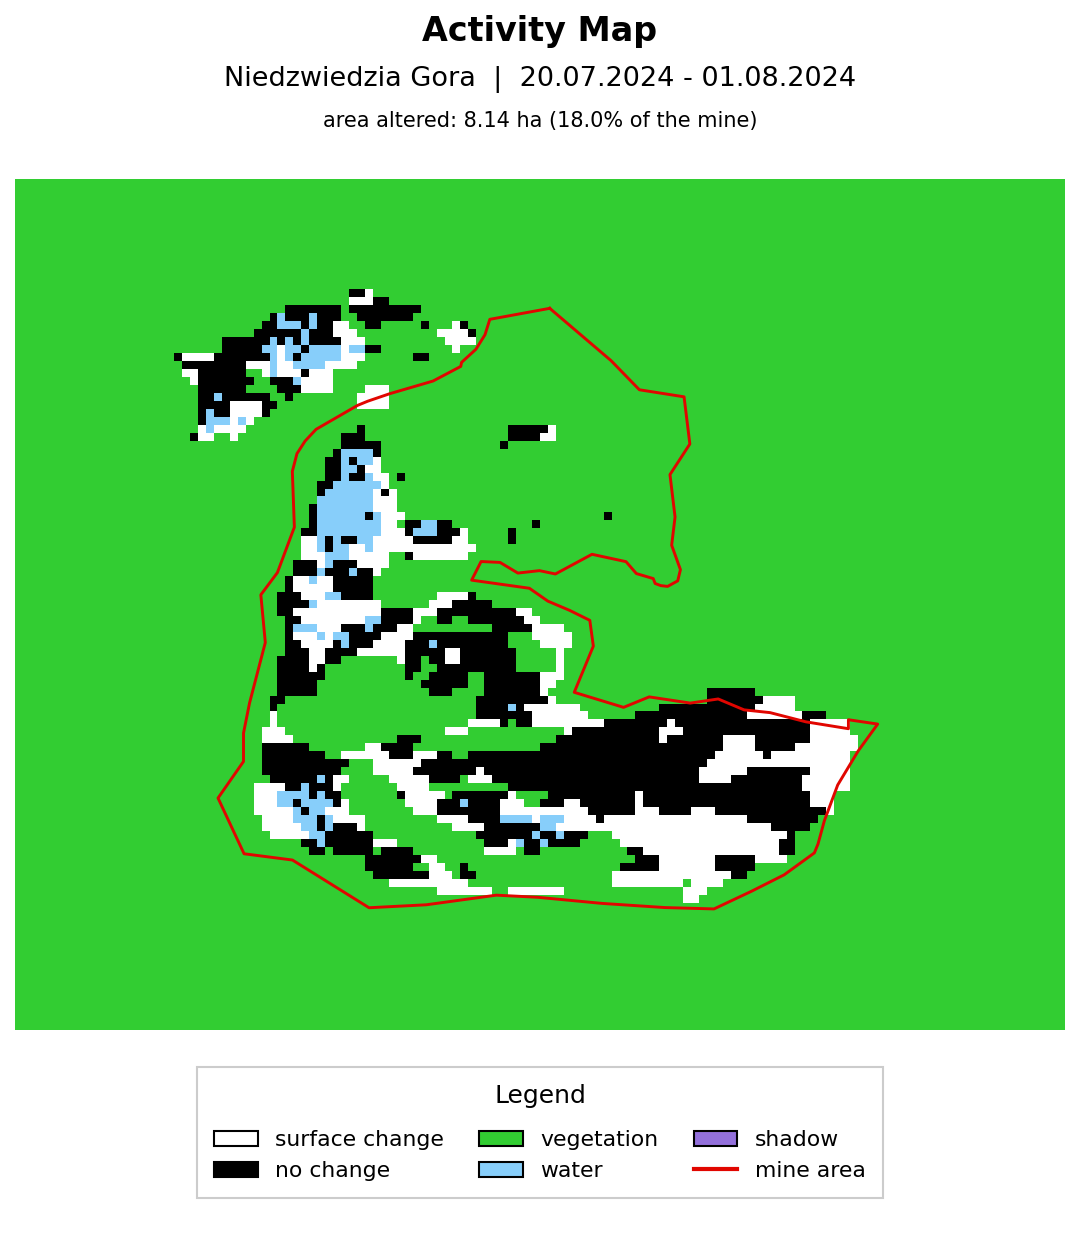

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.07.20-2024.08.01_activity_map.png


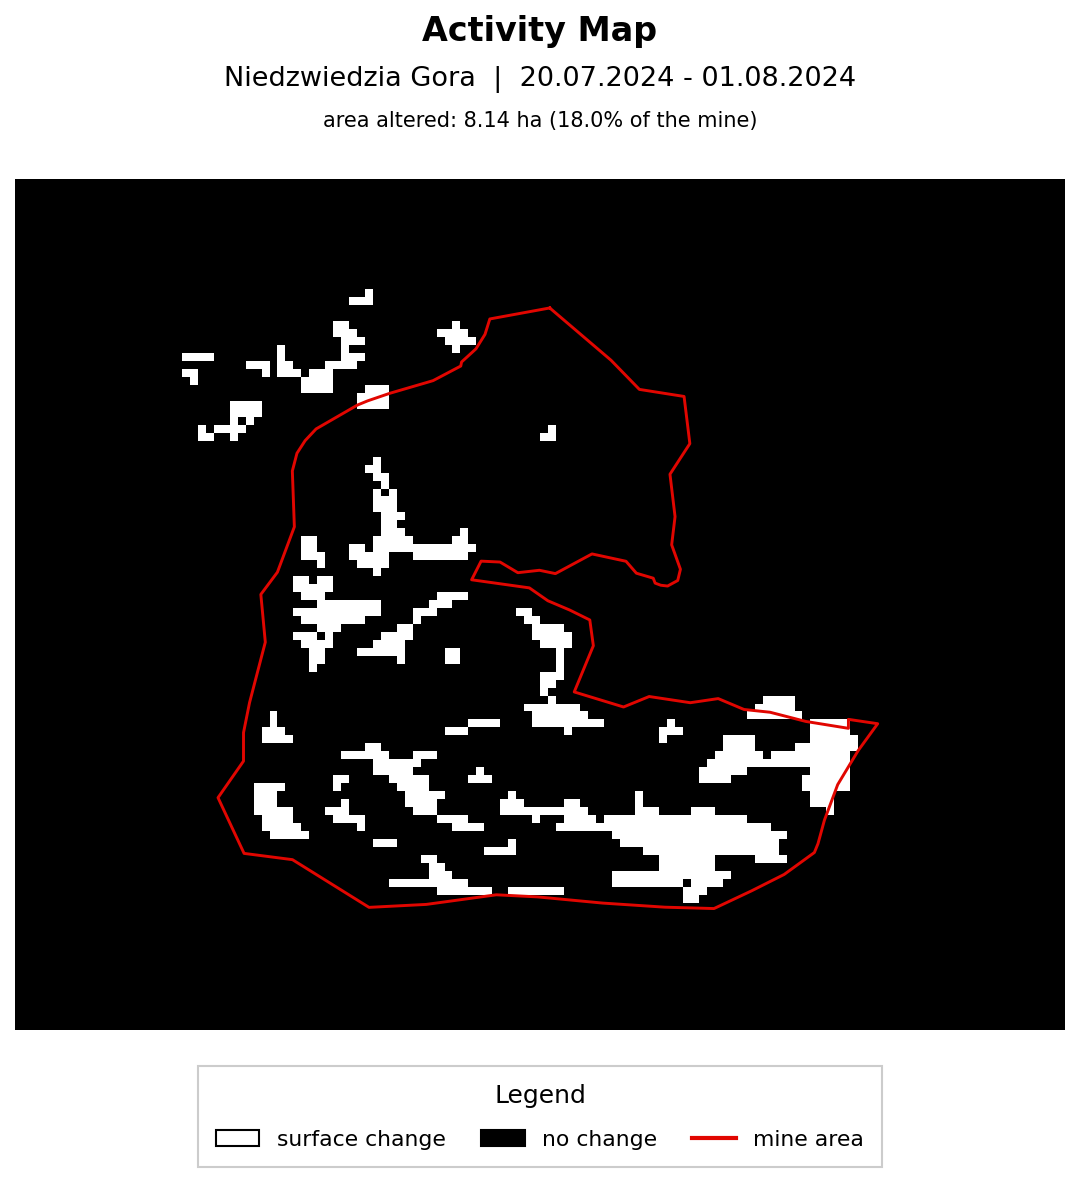

    searching for Sentinel-2 images ...
      date range: 2024-06-20 - 2024-07-19
    Sentinel-2 image scelected: 2024.07.10 20240710T095031_20240710T095042_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-08-02 - 2024-09-01
    Sentinel-2 image scelected: 2024.08.14 20240814T094549_20240814T095005_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.07.20-2024.08.01_activity_map_optical_images.png


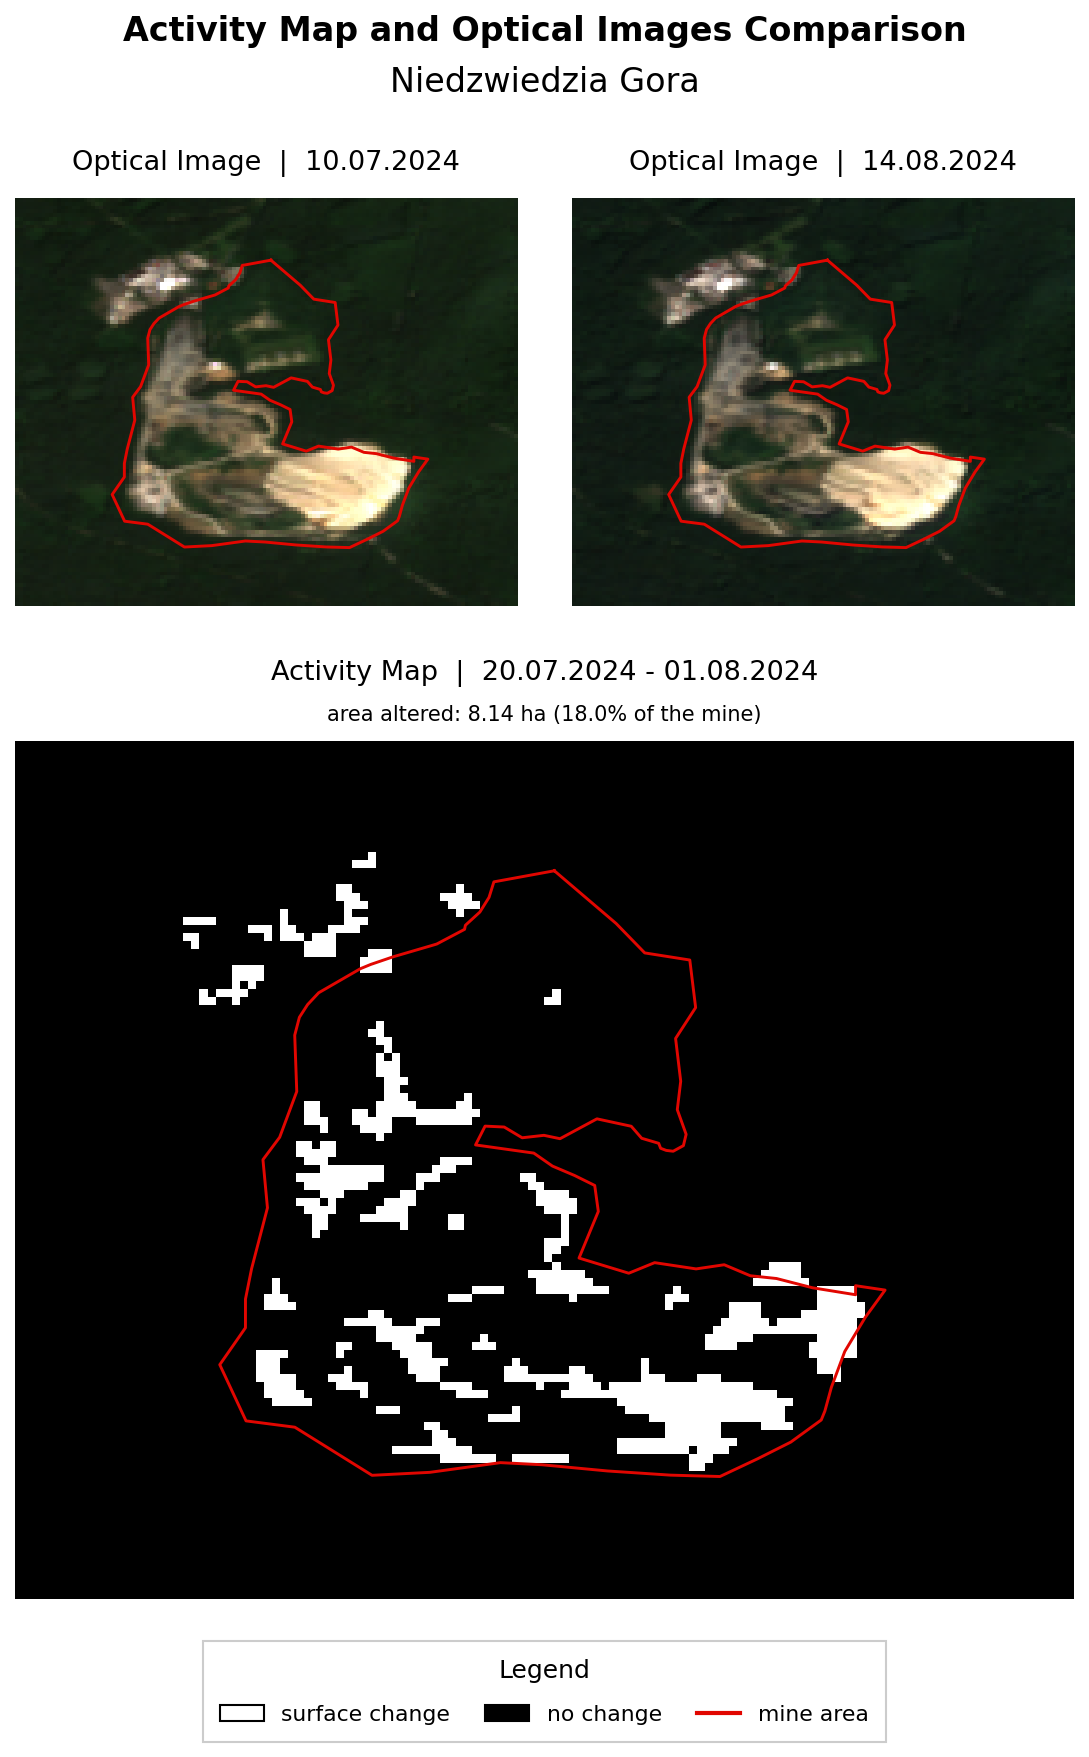

  pair 9/18: 2024.08.01 - 2024.08.13
    area changed inside the polygon: 69727 m2, 15.4% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.01-2024.08.13_activity_map_with_mask.png


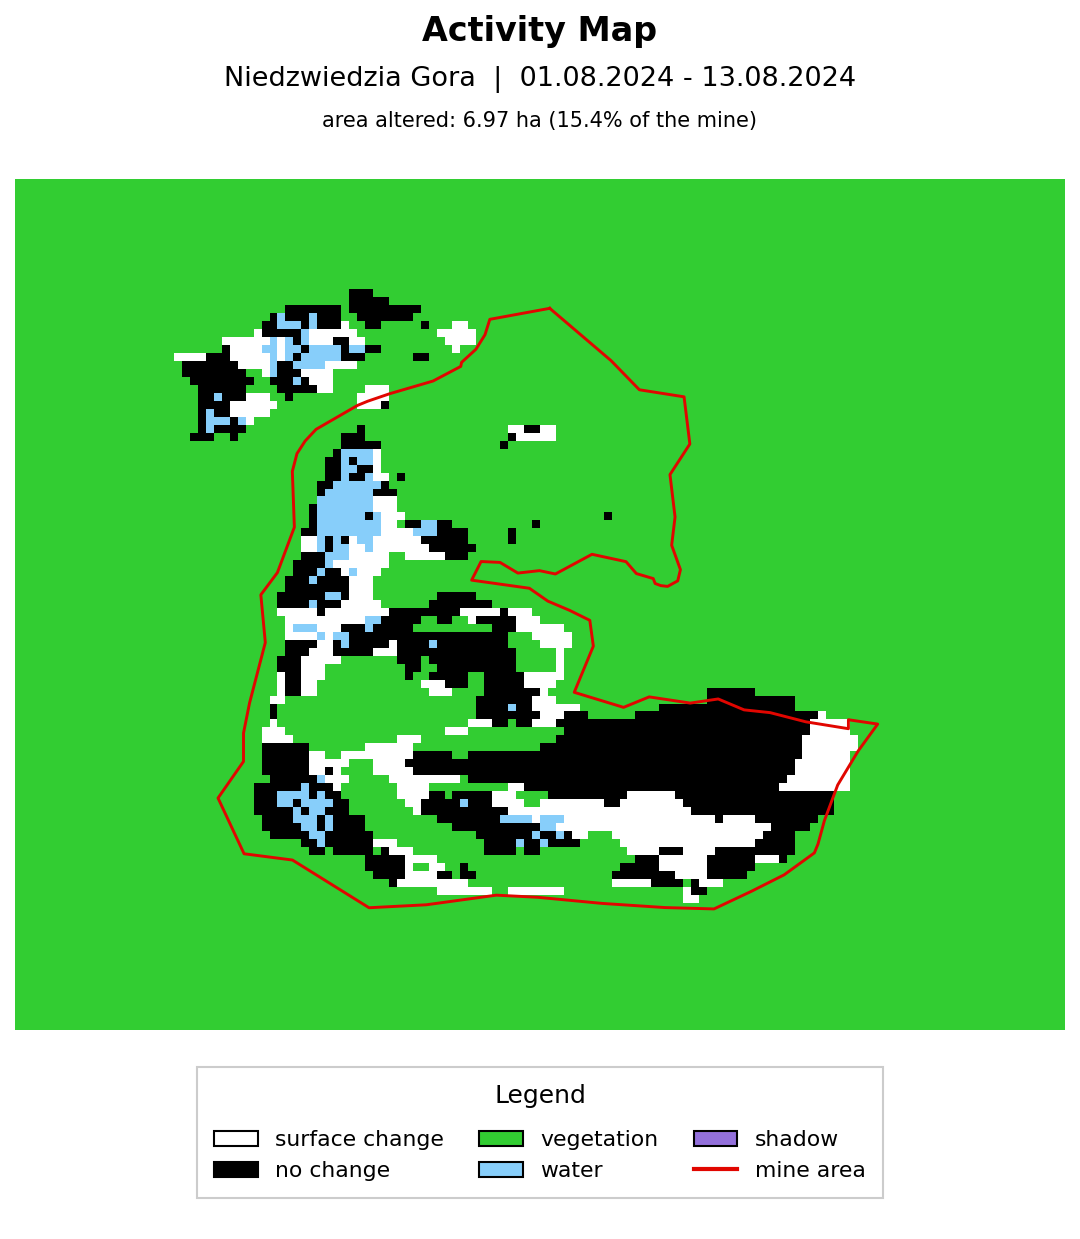

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.01-2024.08.13_activity_map.png


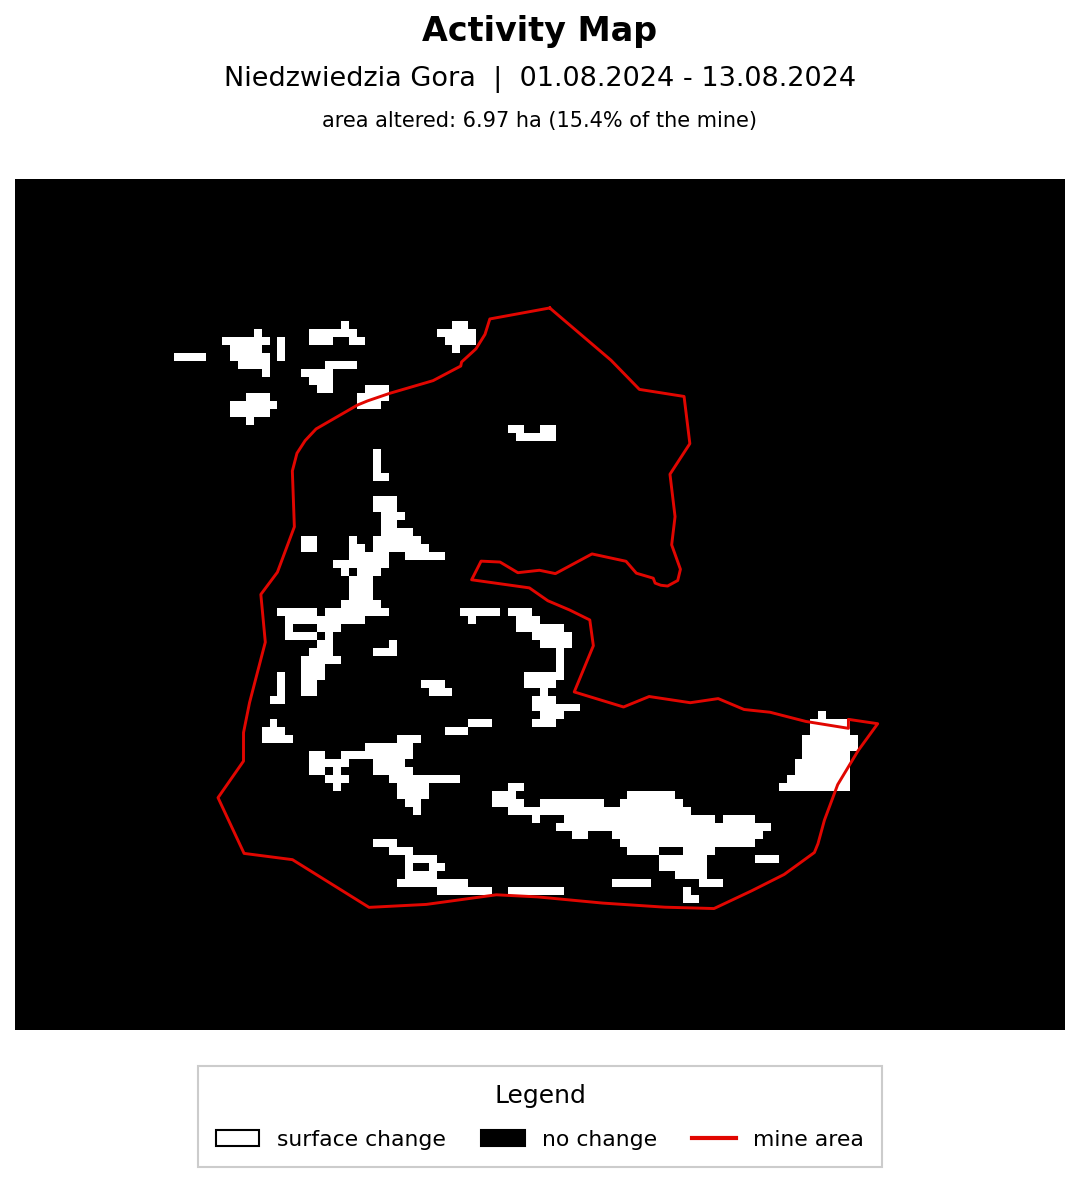

    searching for Sentinel-2 images ...
      date range: 2024-07-01 - 2024-07-31
    Sentinel-2 image scelected: 2024.07.30 20240730T095031_20240730T095149_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-08-14 - 2024-09-13
    Sentinel-2 image scelected: 2024.08.14 20240814T094549_20240814T095005_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.01-2024.08.13_activity_map_optical_images.png


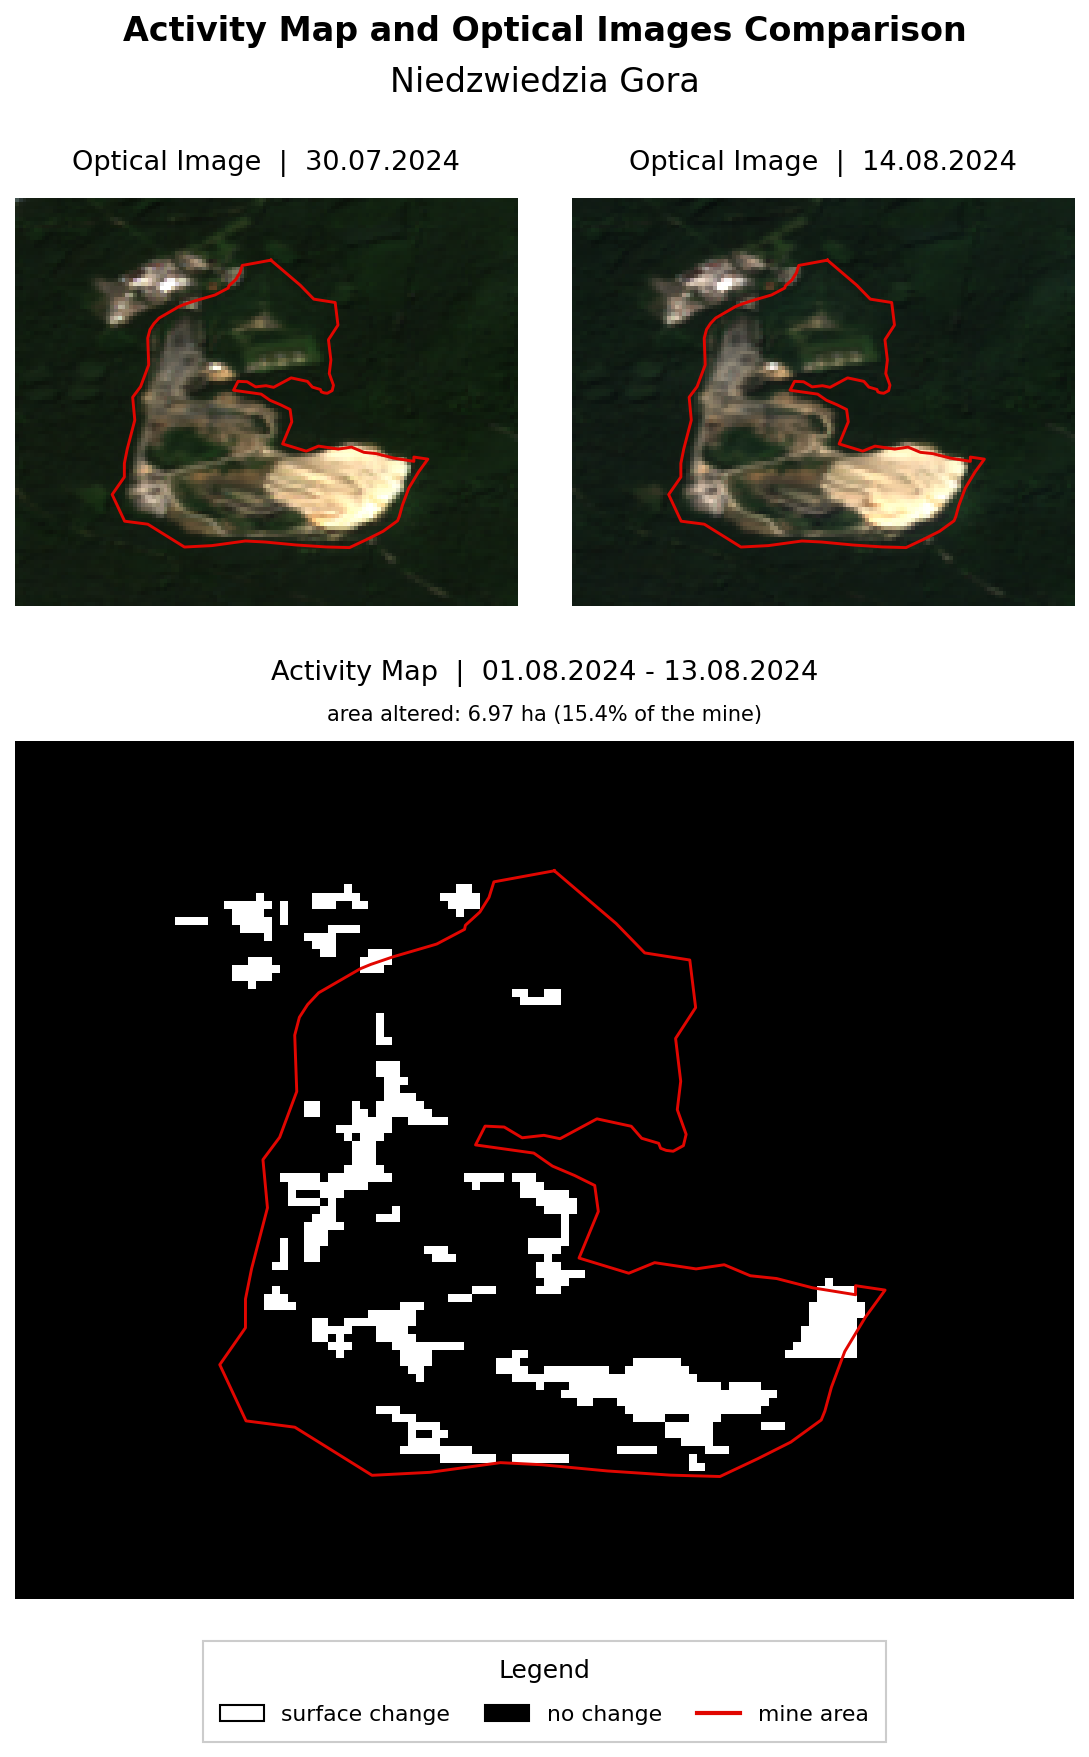

  pair 10/18: 2024.08.13 - 2024.08.25
    area changed inside the polygon: 85913 m2, 19.0% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.13-2024.08.25_activity_map_with_mask.png


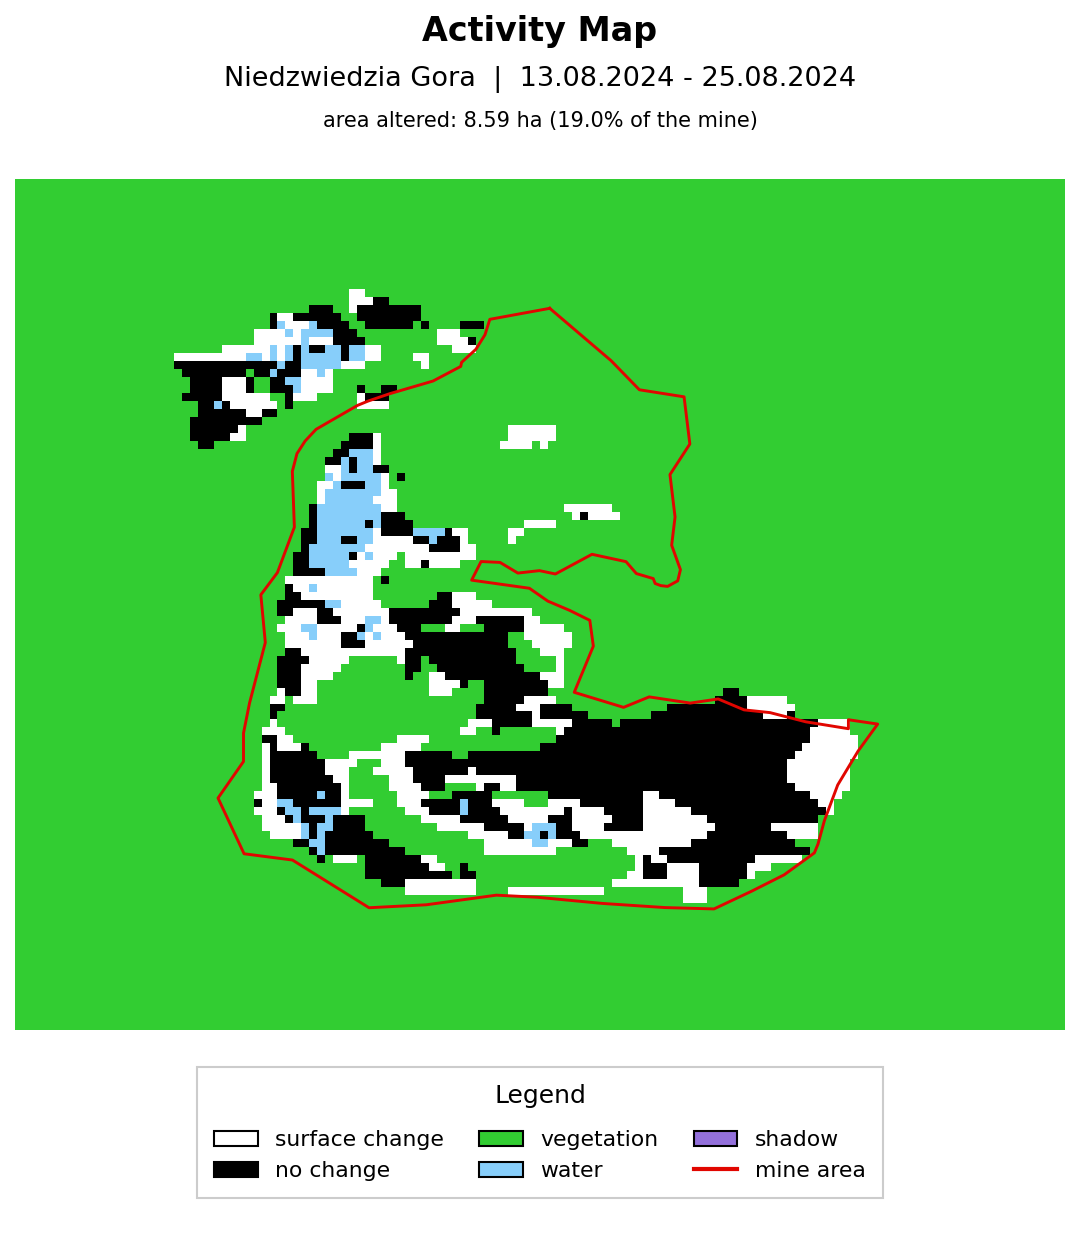

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.13-2024.08.25_activity_map.png


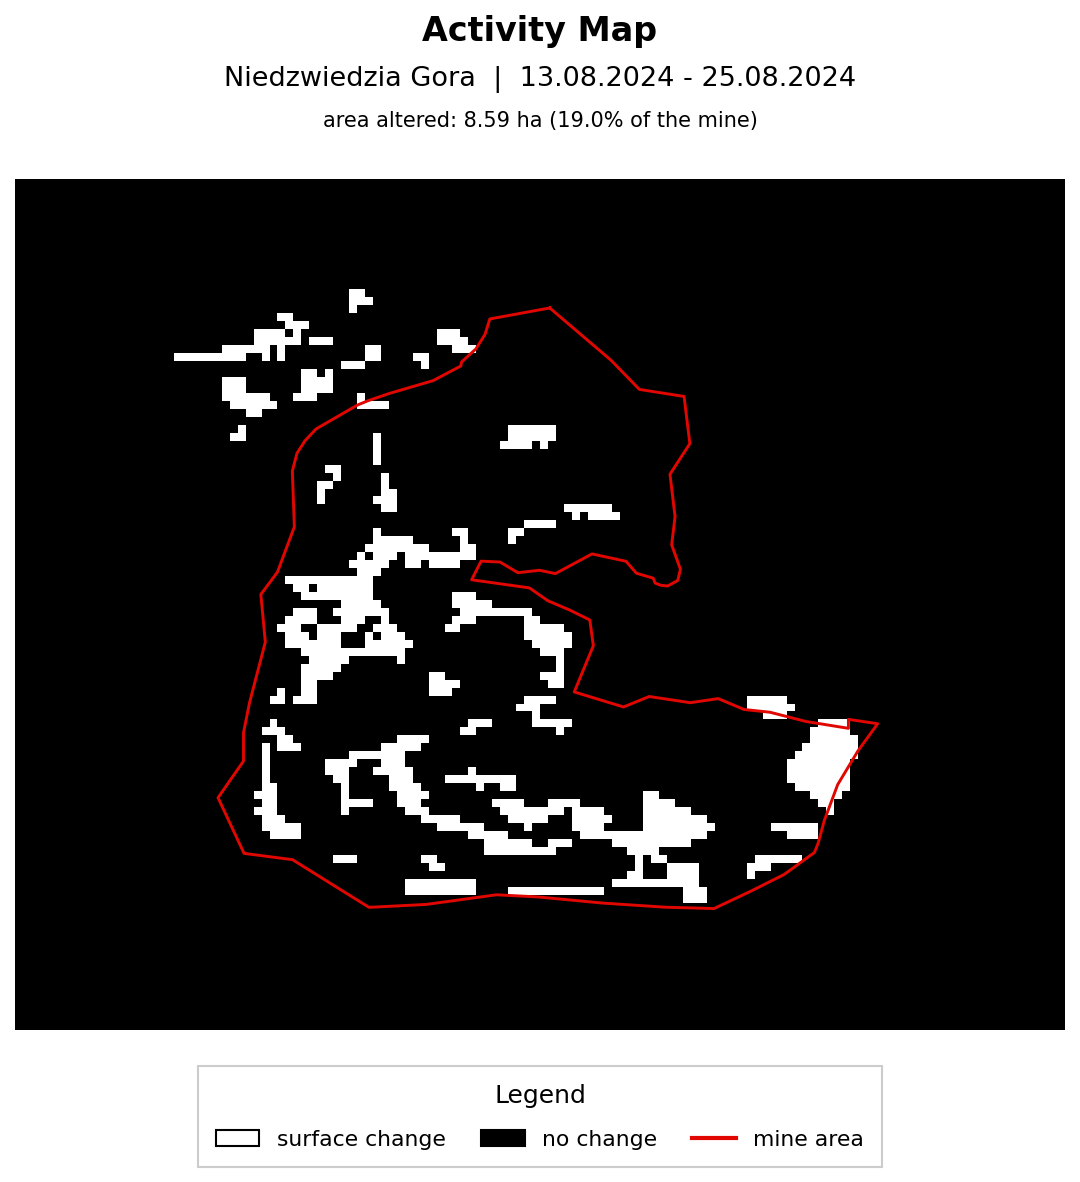

    searching for Sentinel-2 images ...
      date range: 2024-07-13 - 2024-08-12
    Sentinel-2 image scelected: 2024.07.30 20240730T095031_20240730T095149_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-08-26 - 2024-09-25
    Sentinel-2 image scelected: 2024.08.29 20240829T095031_20240829T095026_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.13-2024.08.25_activity_map_optical_images.png


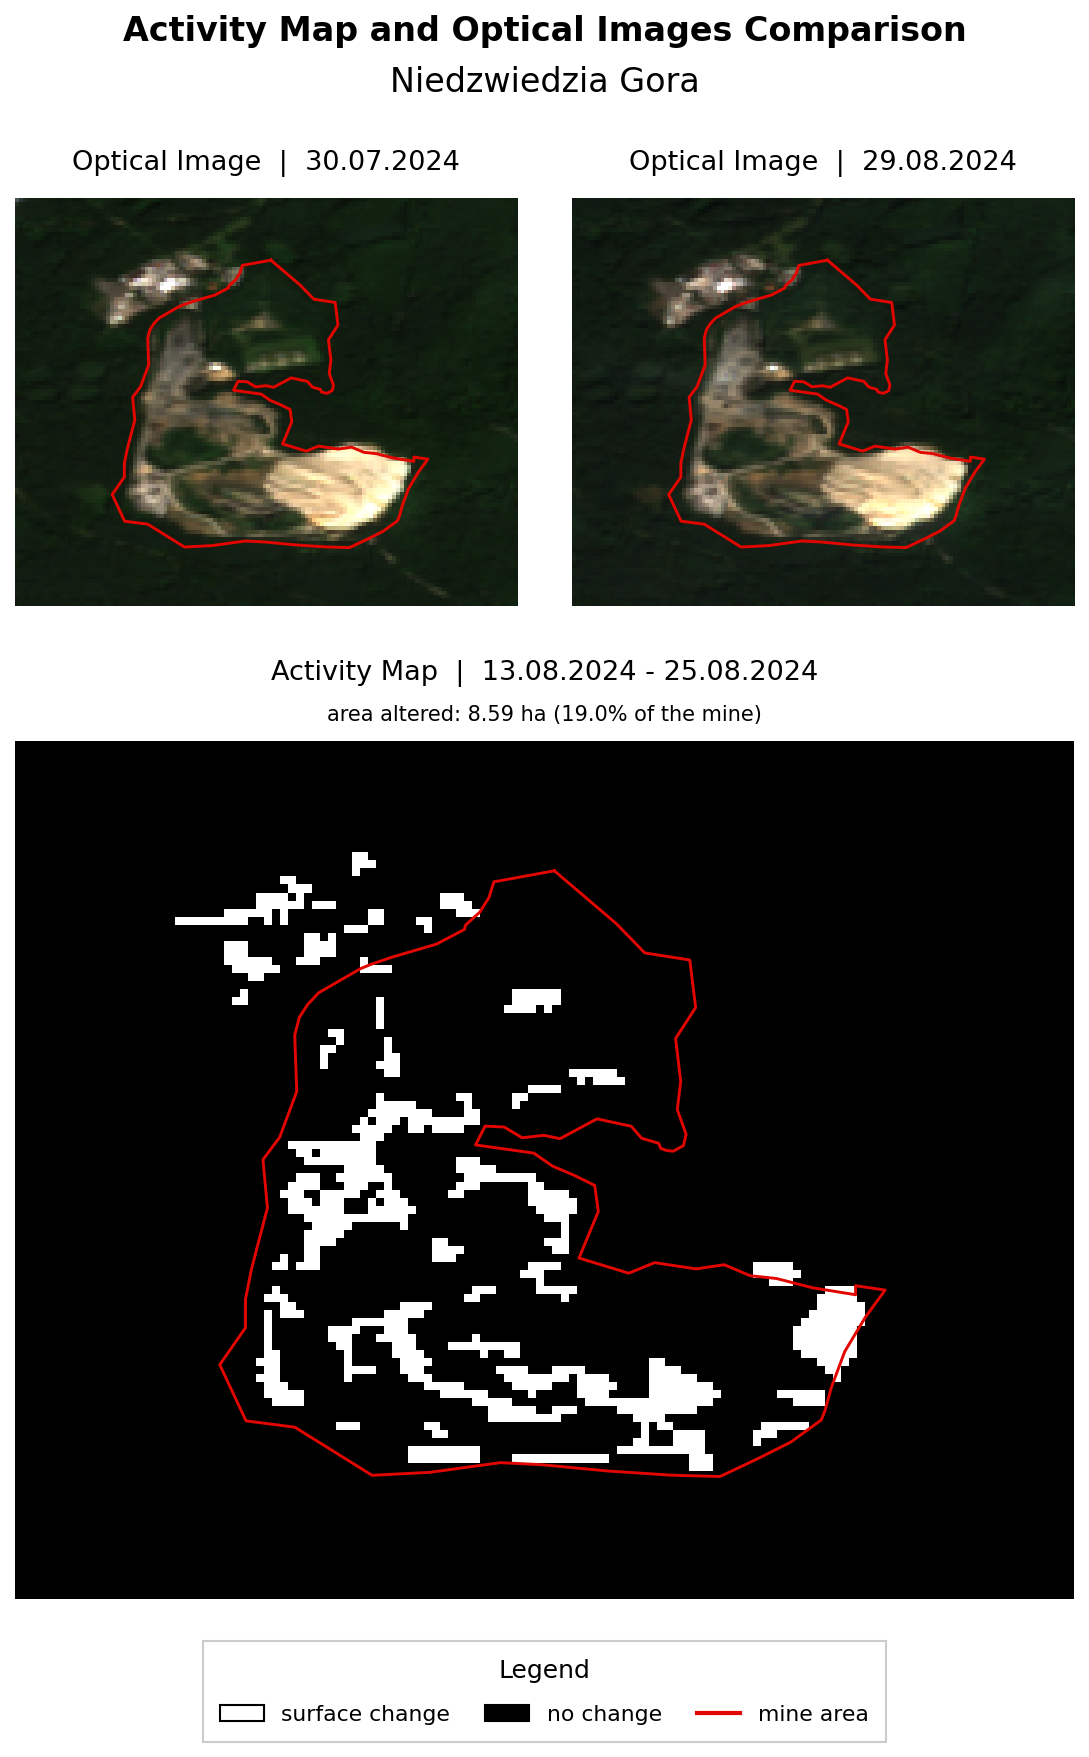

  pair 11/18: 2024.08.25 - 2024.09.06
    area changed inside the polygon: 117539 m2, 26.0% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.25-2024.09.06_activity_map_with_mask.png


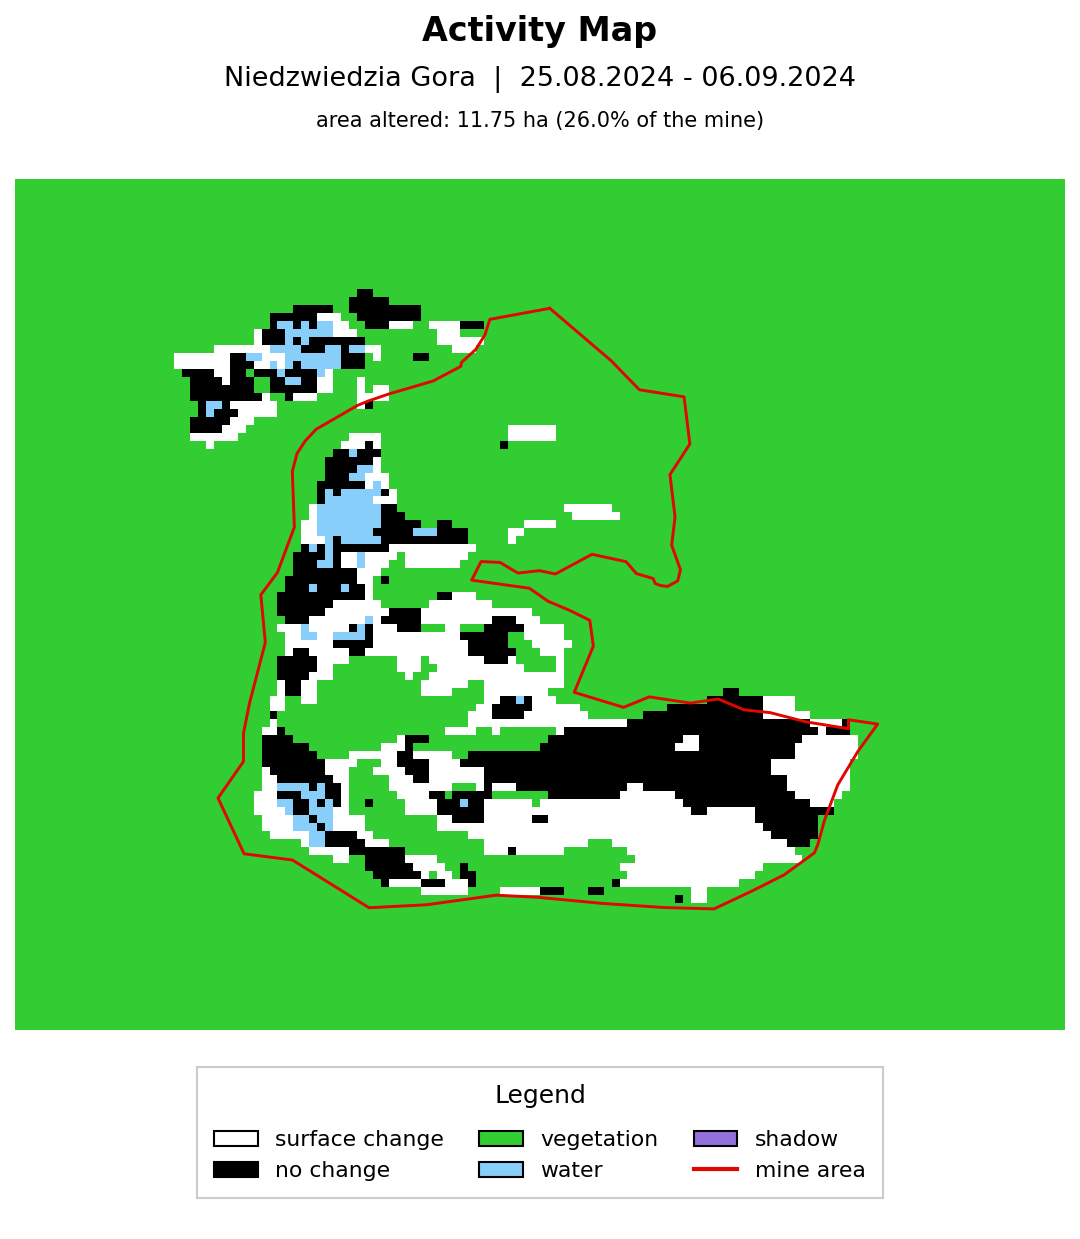

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.25-2024.09.06_activity_map.png


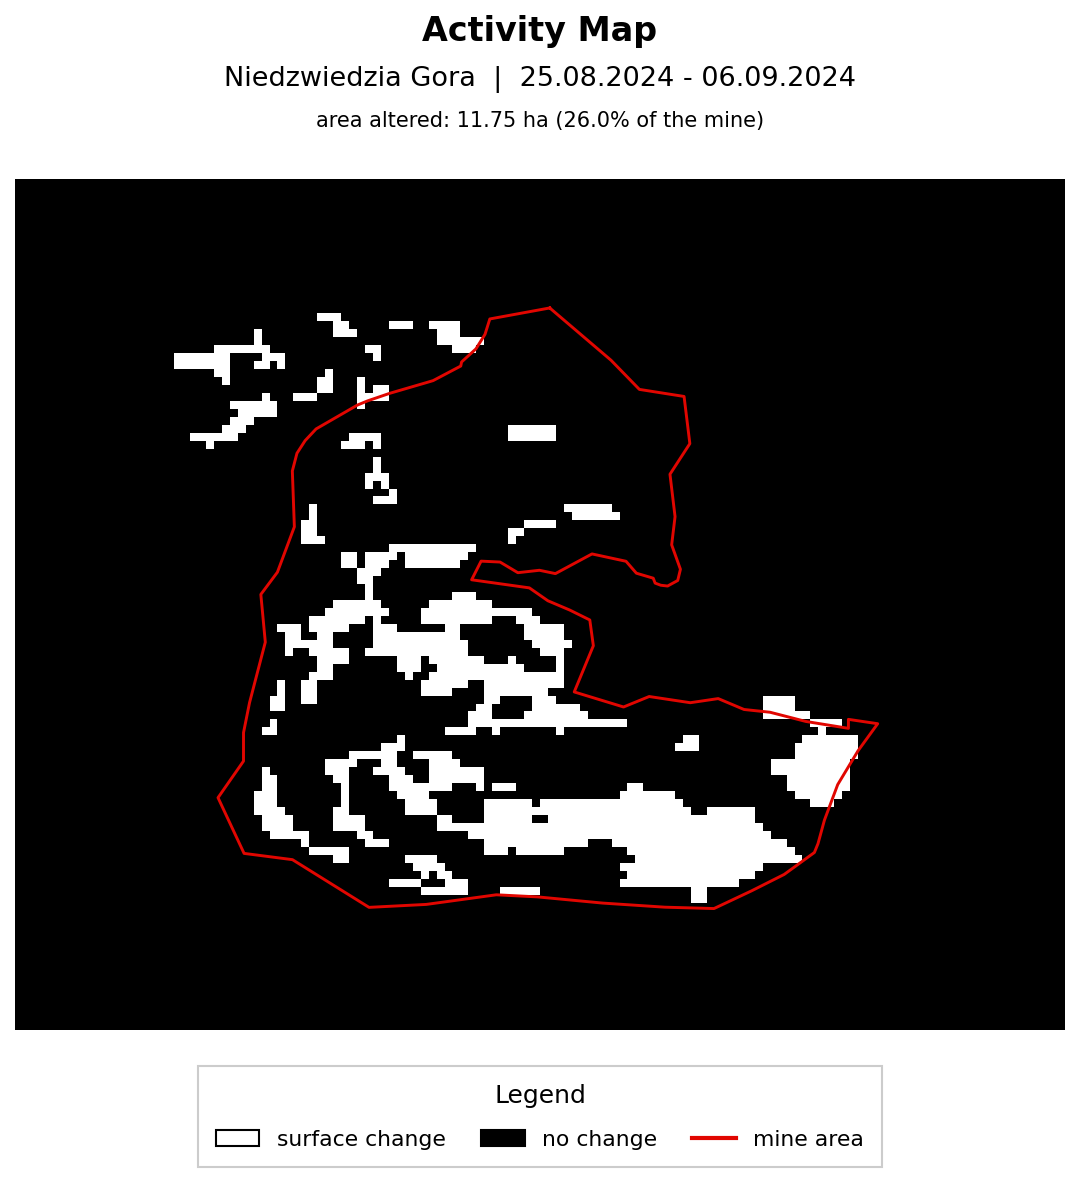

    searching for Sentinel-2 images ...
      date range: 2024-07-25 - 2024-08-24
    Sentinel-2 image scelected: 2024.08.14 20240814T094549_20240814T095005_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-09-07 - 2024-10-06
    Sentinel-2 image scelected: 2024.09.08 20240908T095031_20240908T095523_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.08.25-2024.09.06_activity_map_optical_images.png


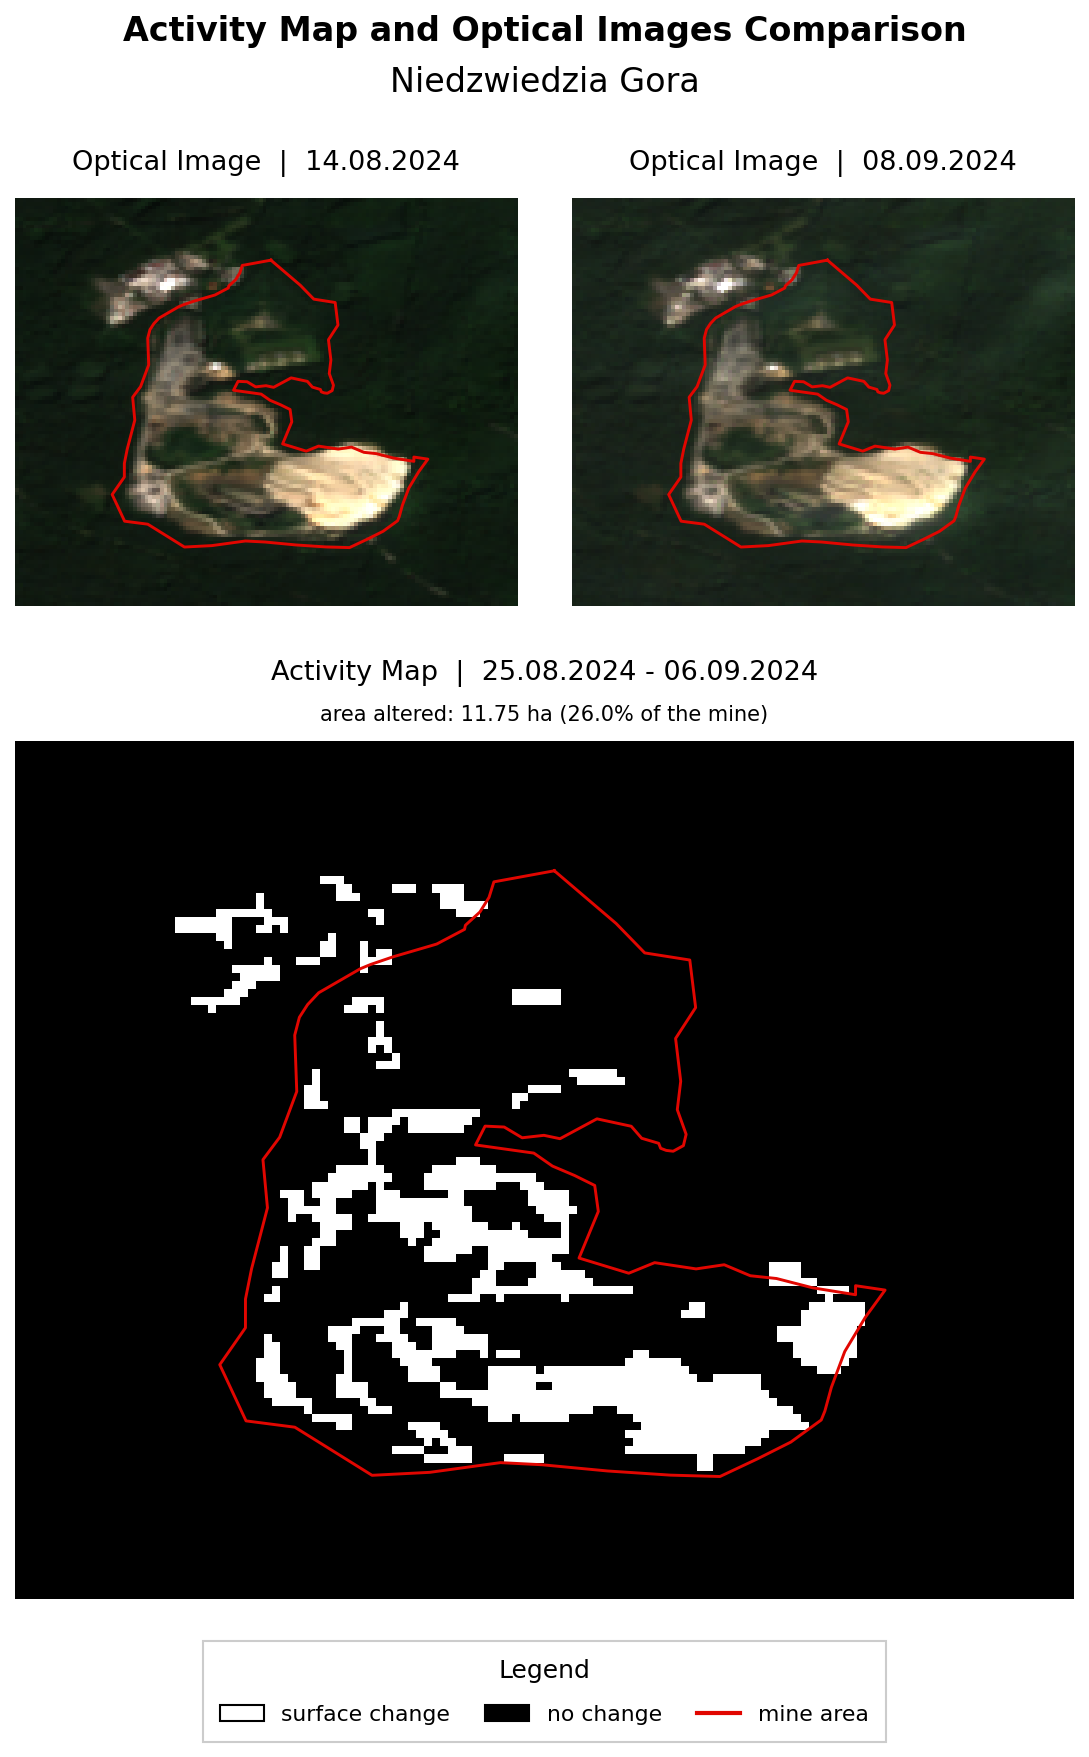

  pair 12/18: 2024.09.06 - 2024.09.18
    area changed inside the polygon: 82800 m2, 18.3% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.06-2024.09.18_activity_map_with_mask.png


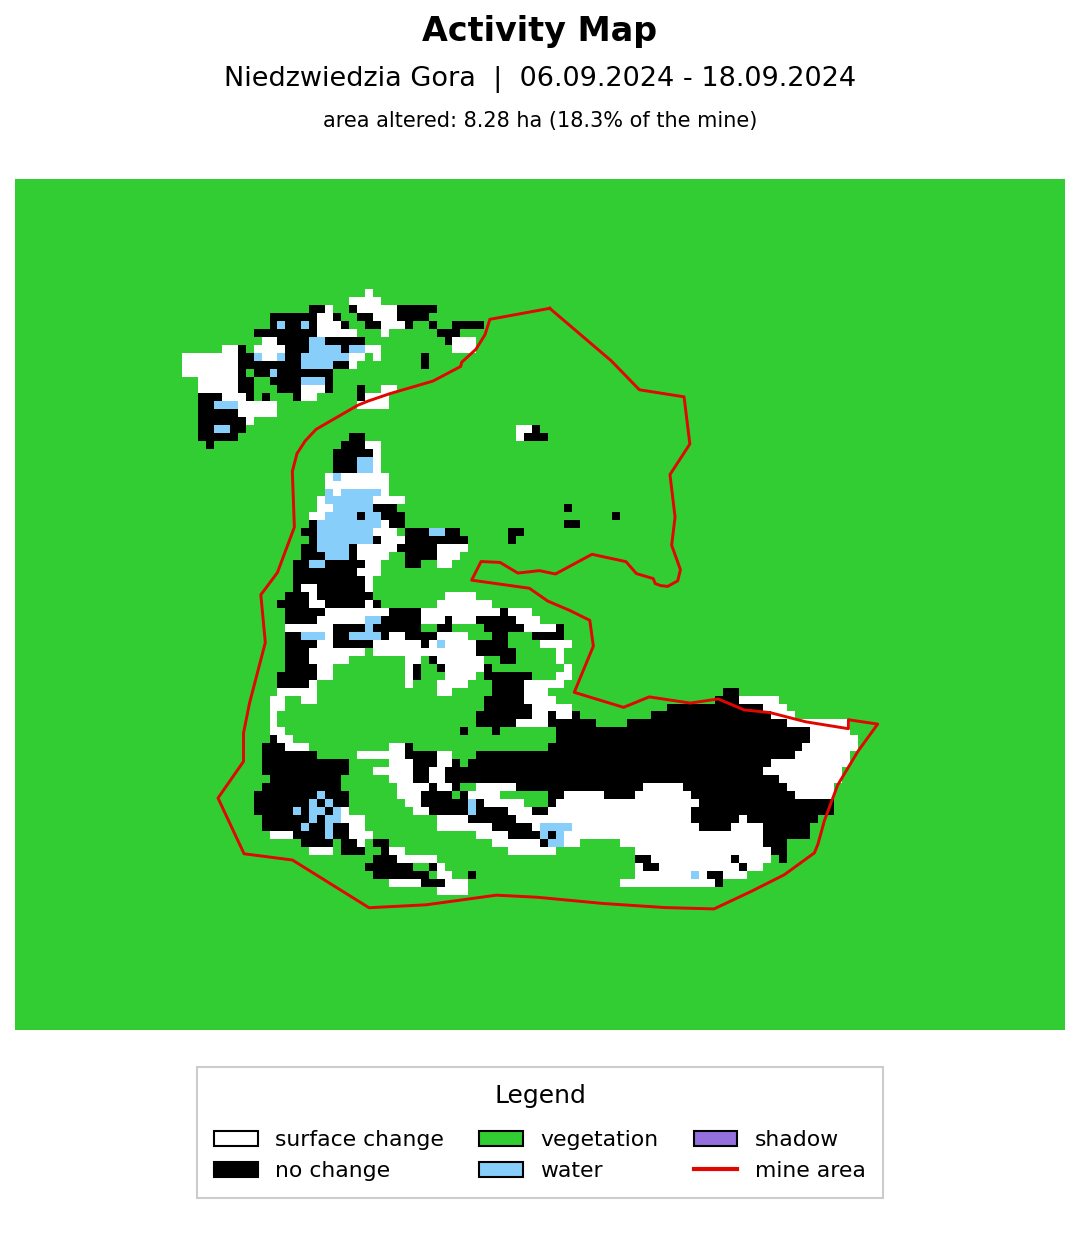

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.06-2024.09.18_activity_map.png


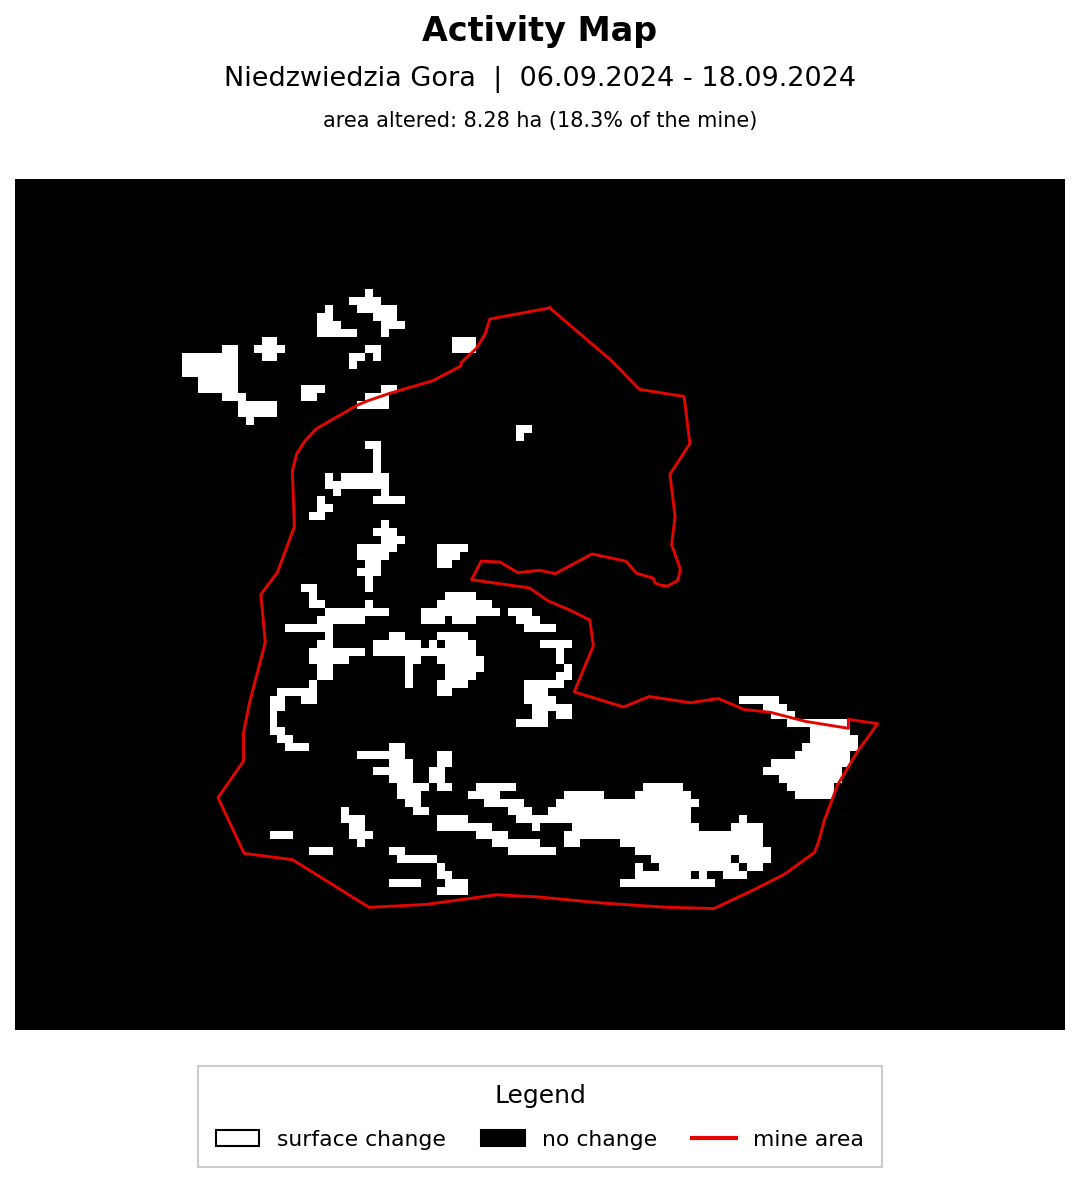

    searching for Sentinel-2 images ...
      date range: 2024-08-06 - 2024-09-05
    Sentinel-2 image scelected: 2024.09.05 20240905T094031_20240905T094031_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-09-19 - 2024-10-18
    Sentinel-2 image scelected: 2024.09.20 20240920T094029_20240920T094449_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.06-2024.09.18_activity_map_optical_images.png


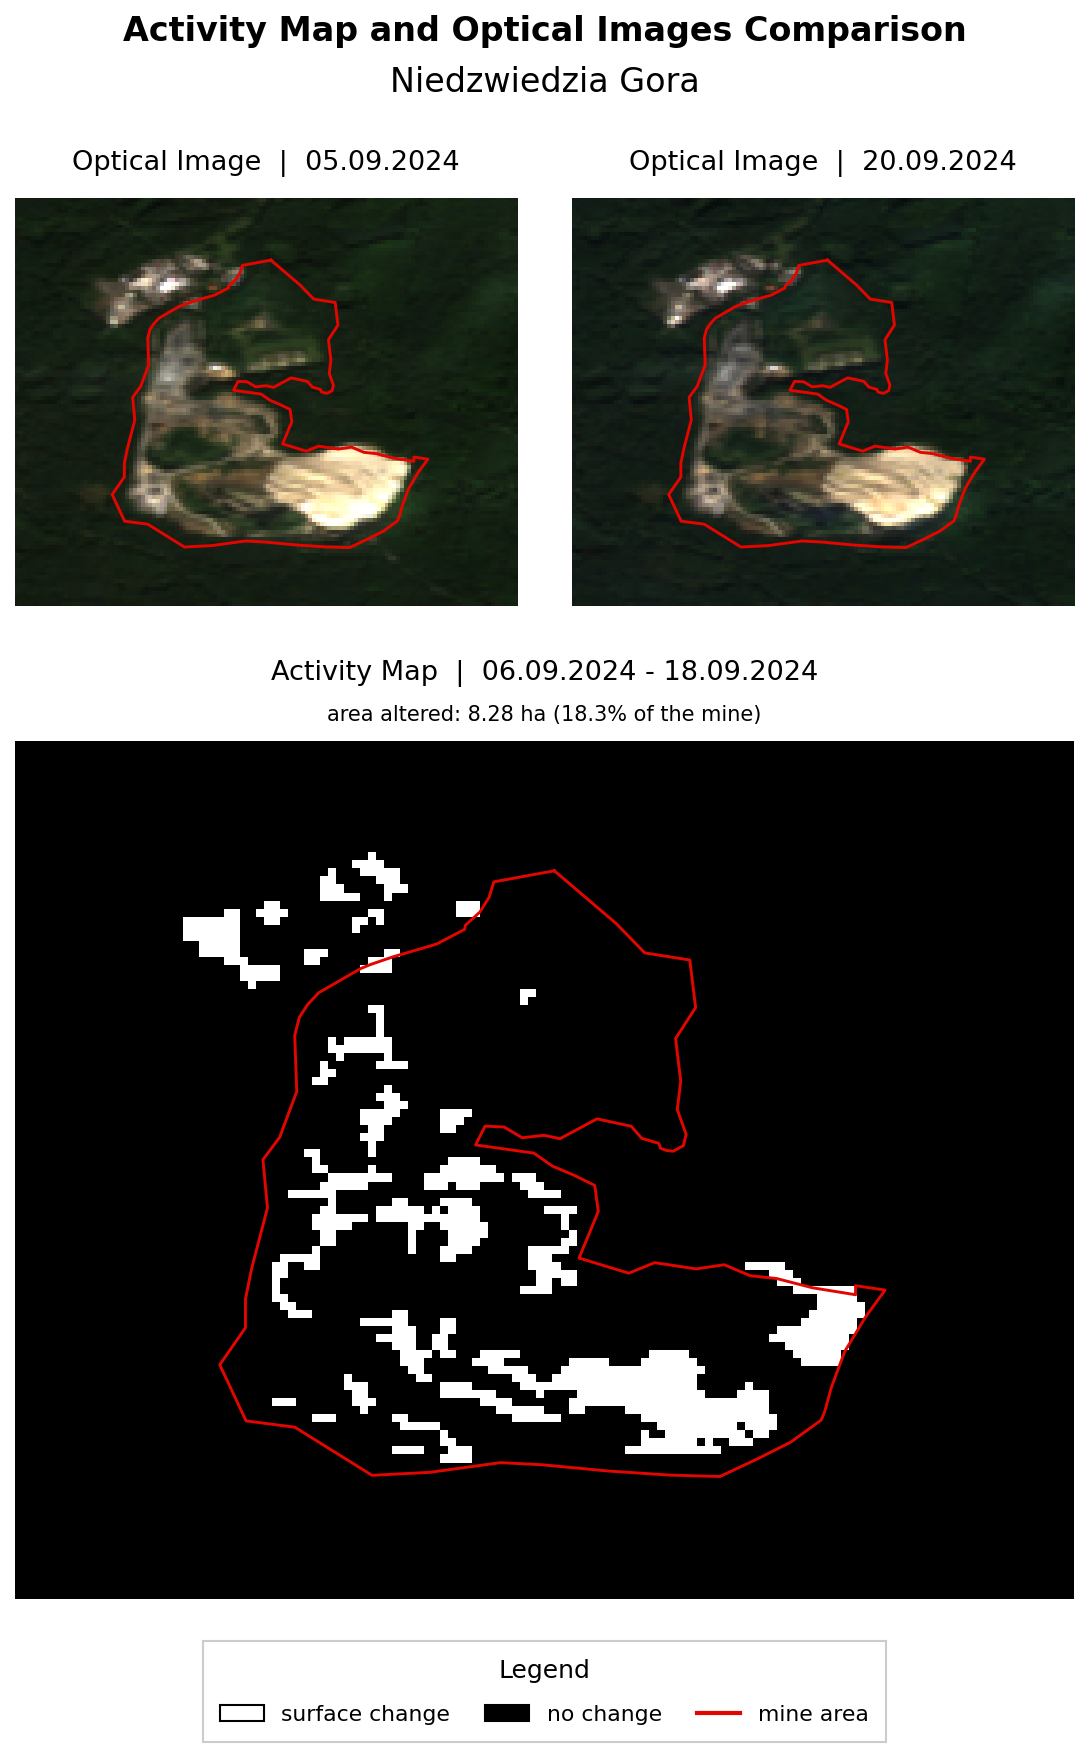

  pair 13/18: 2024.09.18 - 2024.09.30
    area changed inside the polygon: 45945 m2, 10.2% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.18-2024.09.30_activity_map_with_mask.png


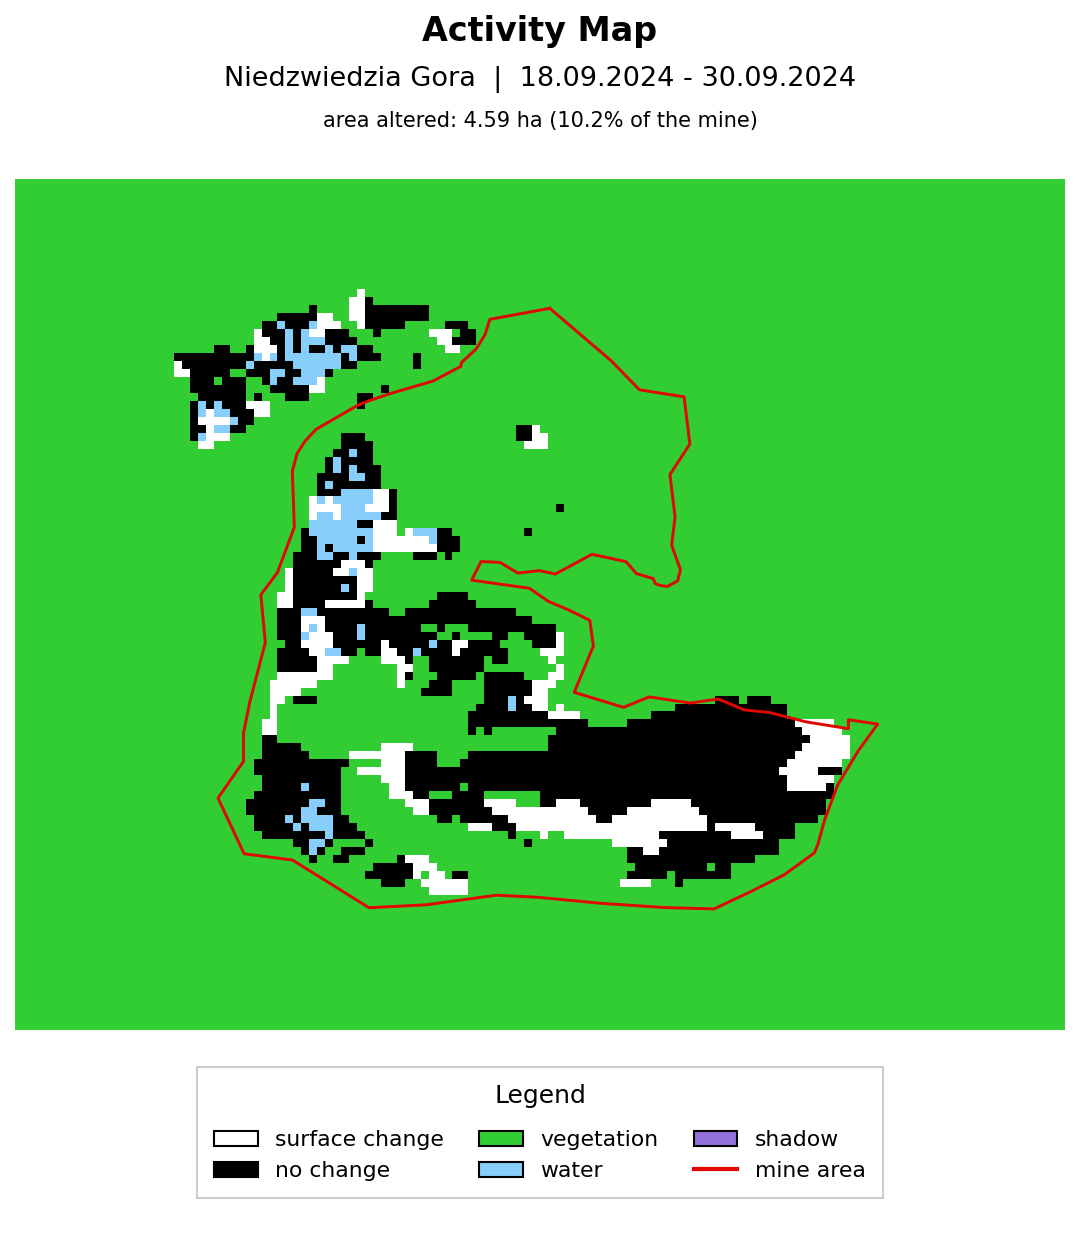

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.18-2024.09.30_activity_map.png


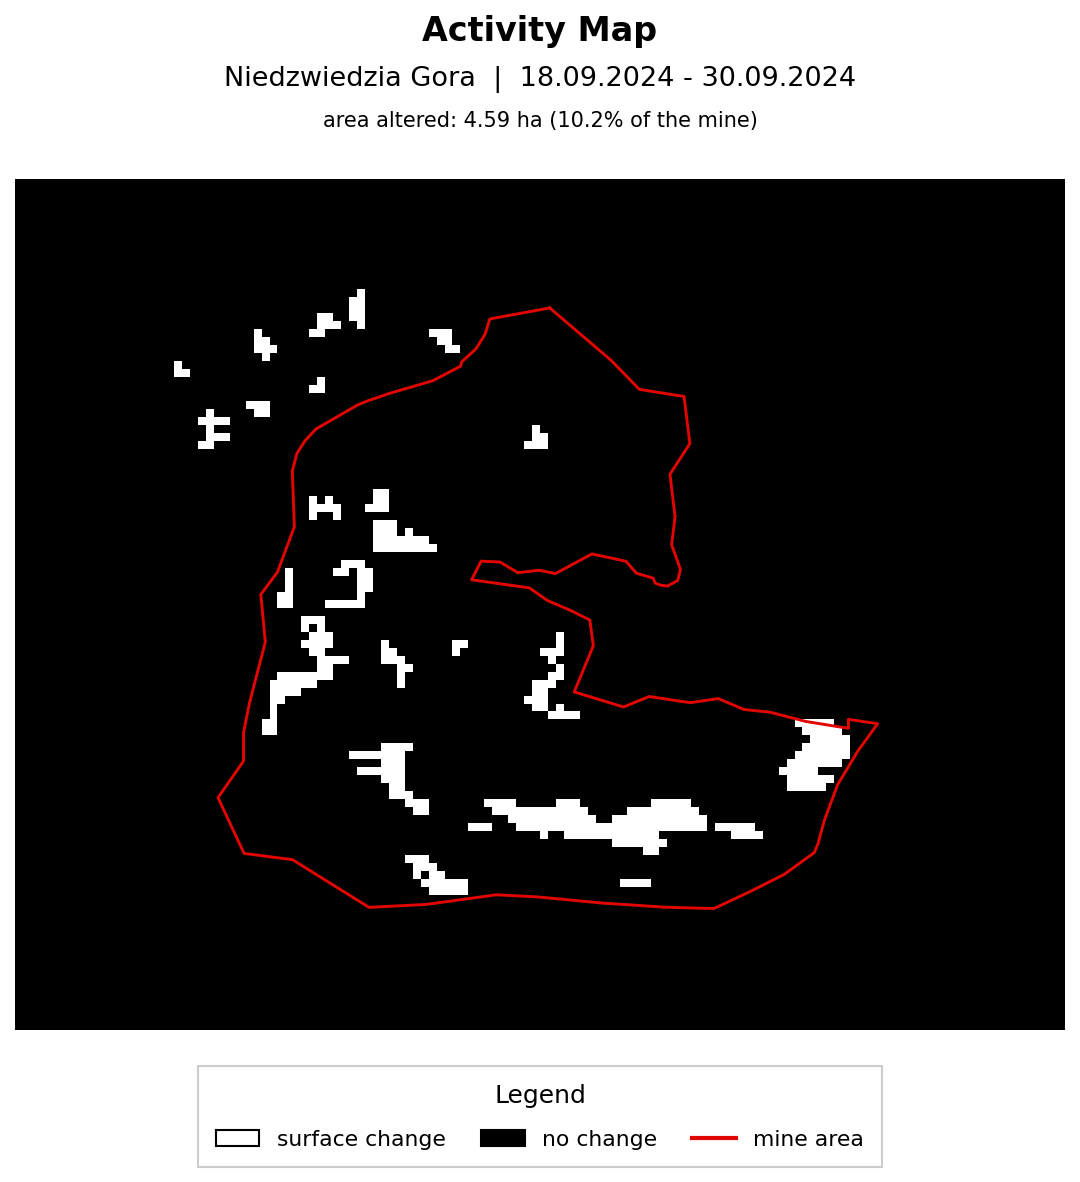

    searching for Sentinel-2 images ...
      date range: 2024-08-18 - 2024-09-17
    Sentinel-2 image scelected: 2024.09.08 20240908T095031_20240908T095523_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-10-01 - 2024-10-30
    Sentinel-2 image scelected: 2024.10.08 20241008T095031_20241008T095200_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.18-2024.09.30_activity_map_optical_images.png


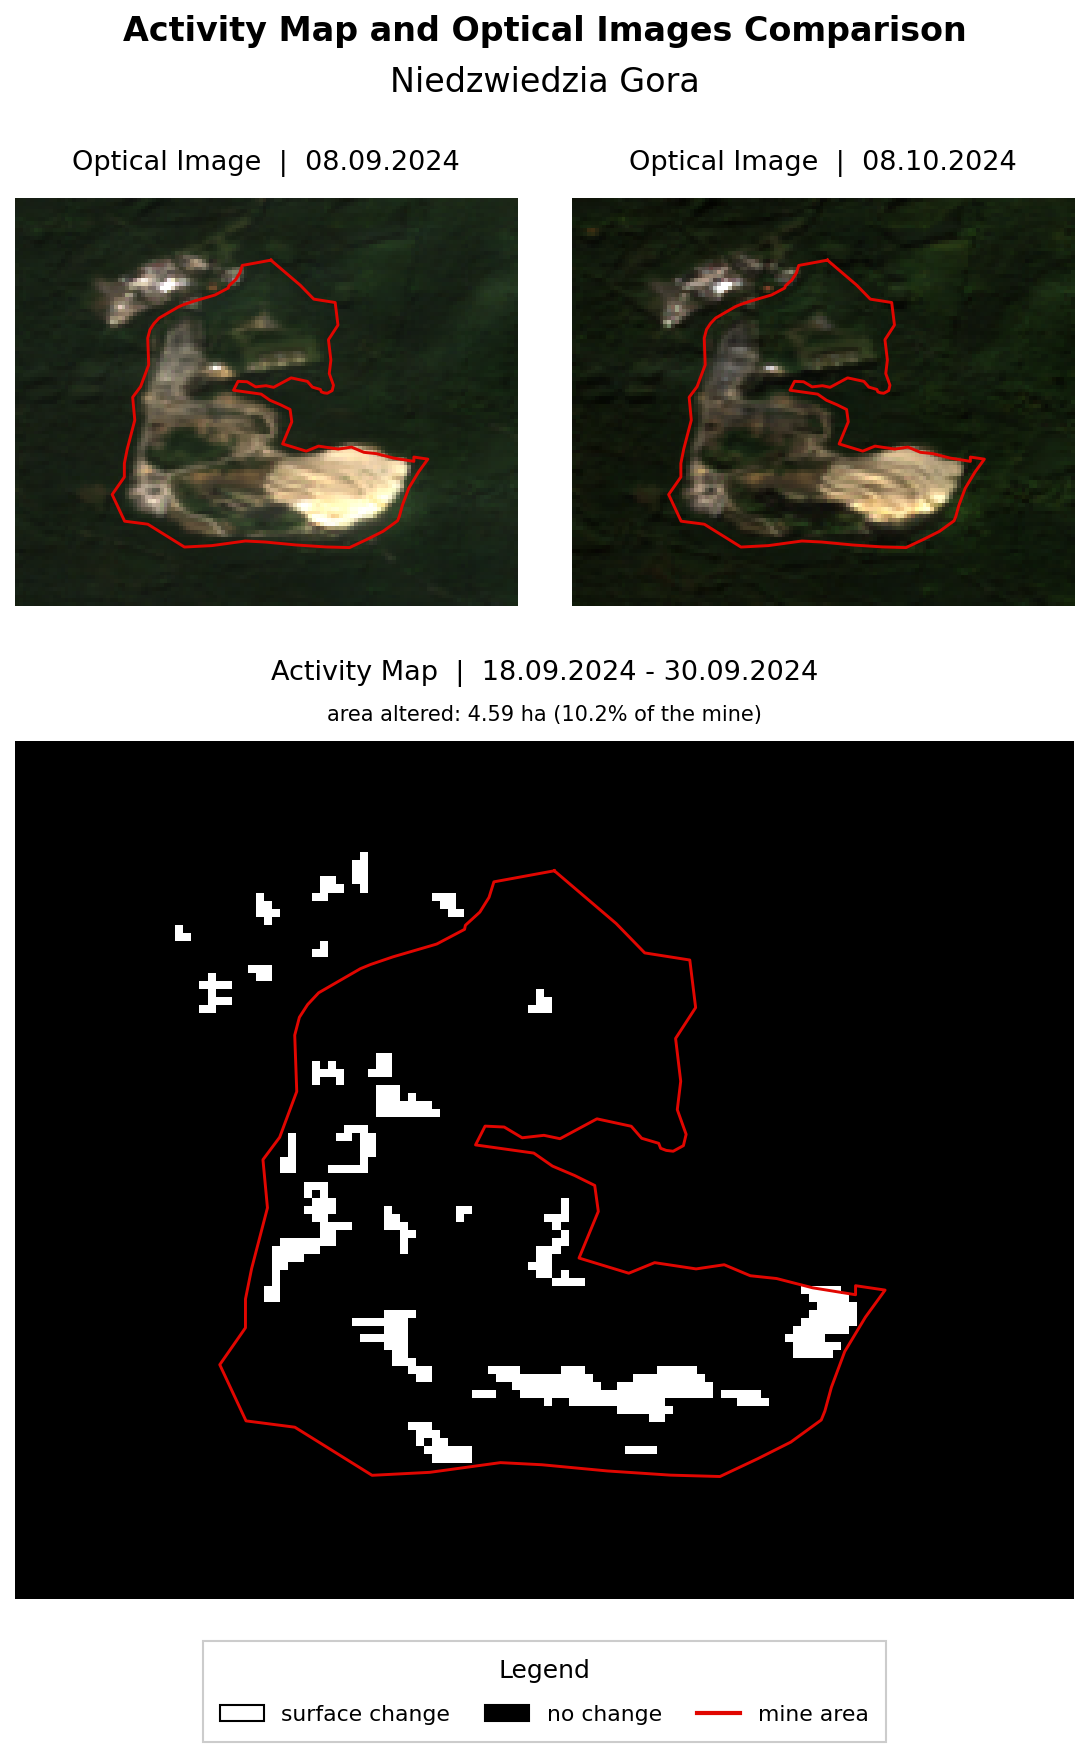

  pair 14/18: 2024.09.30 - 2024.10.12
    area changed inside the polygon: 46567 m2, 10.3% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.30-2024.10.12_activity_map_with_mask.png


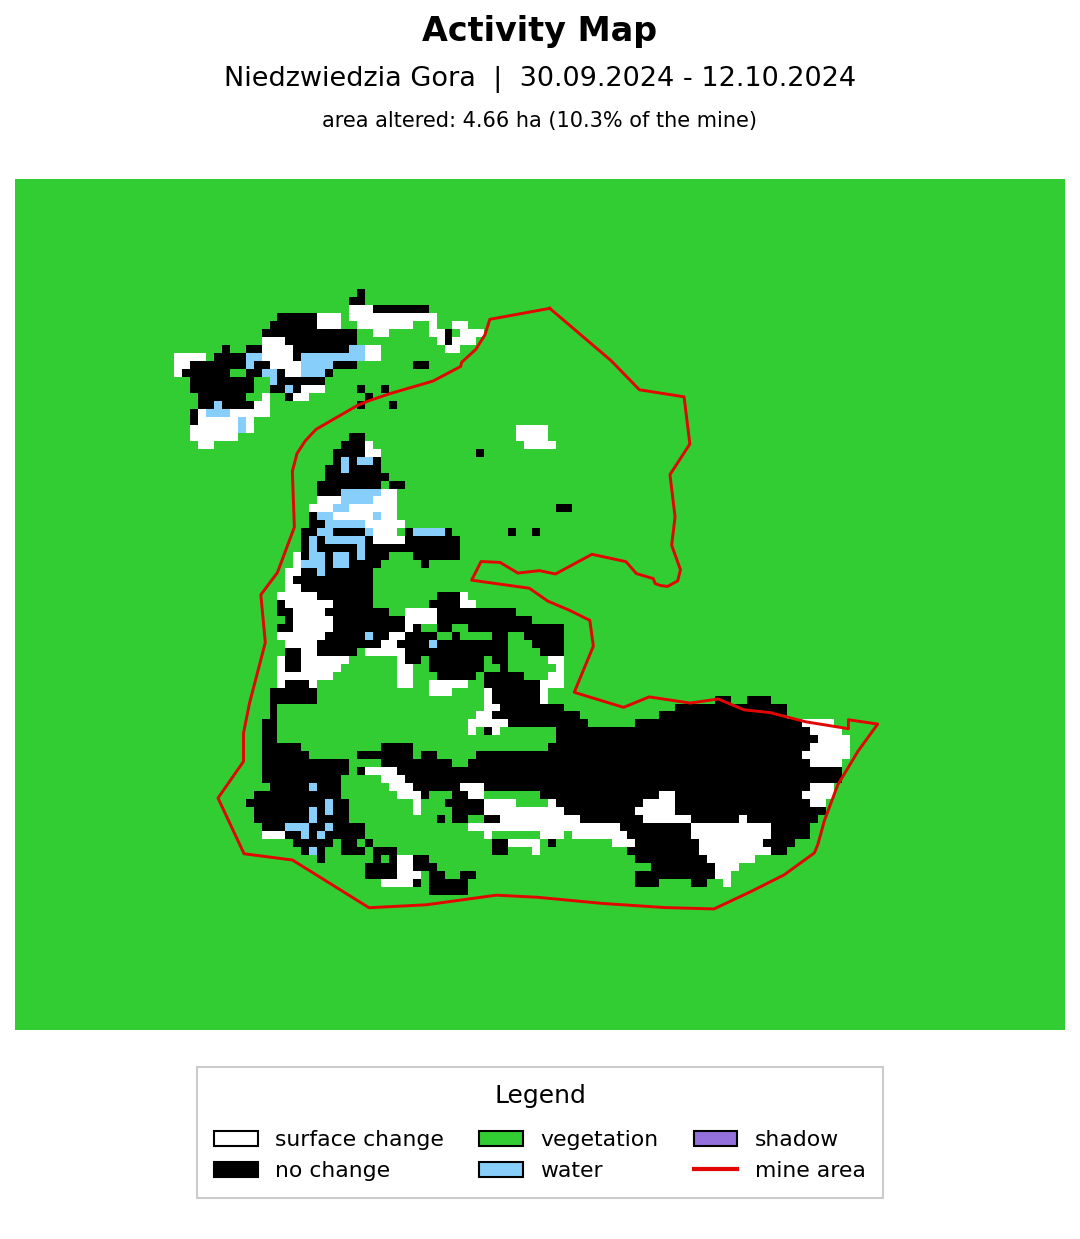

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.30-2024.10.12_activity_map.png


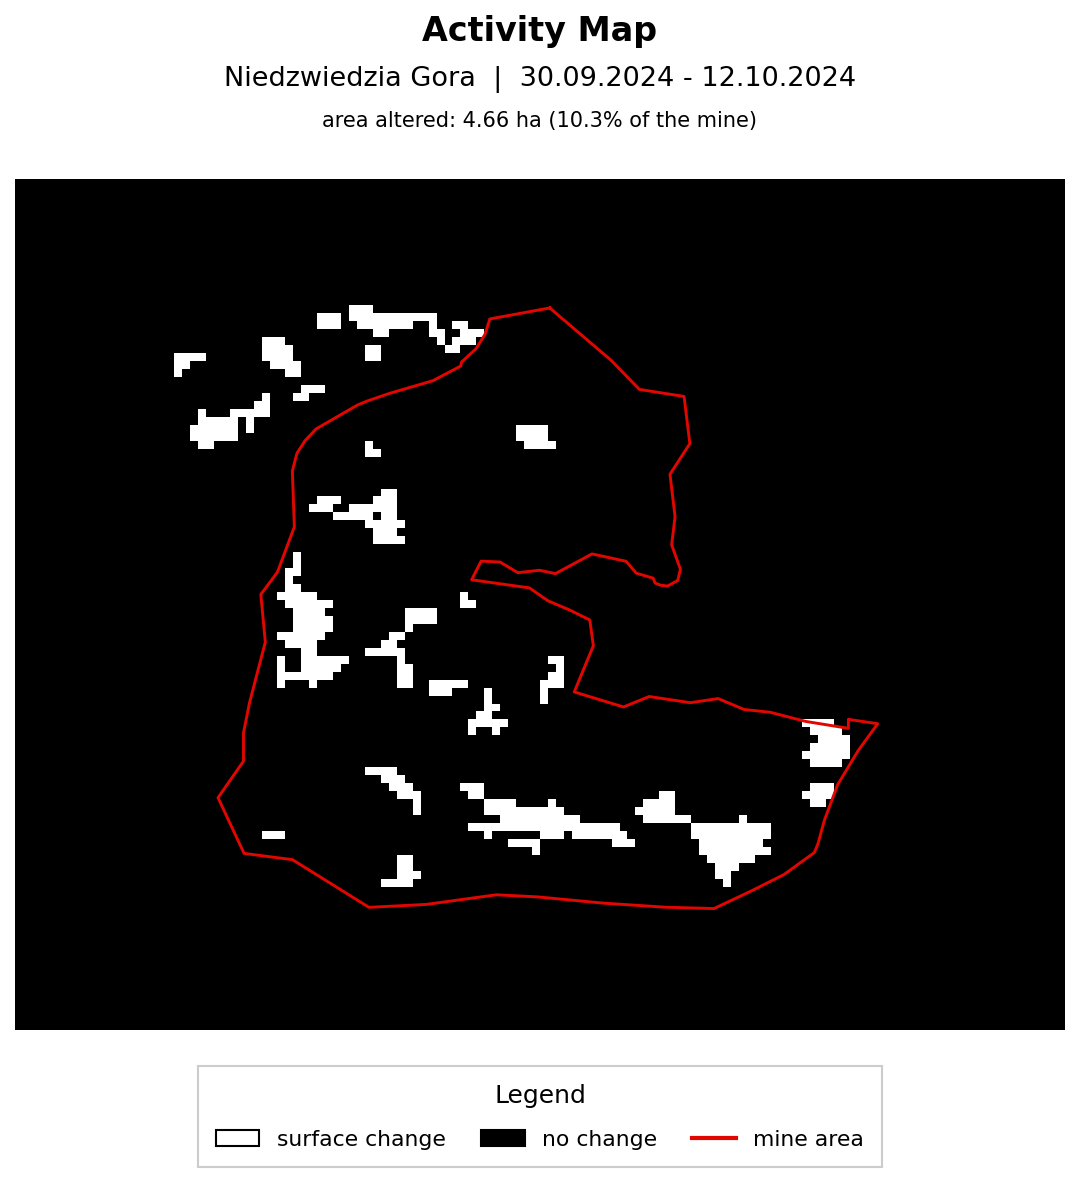

    searching for Sentinel-2 images ...
      date range: 2024-08-30 - 2024-09-29
    Sentinel-2 image scelected: 2024.09.20 20240920T094029_20240920T094449_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-10-13 - 2024-11-12
    Sentinel-2 image scelected: 2024.10.18 20241018T095031_20241018T095240_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.09.30-2024.10.12_activity_map_optical_images.png


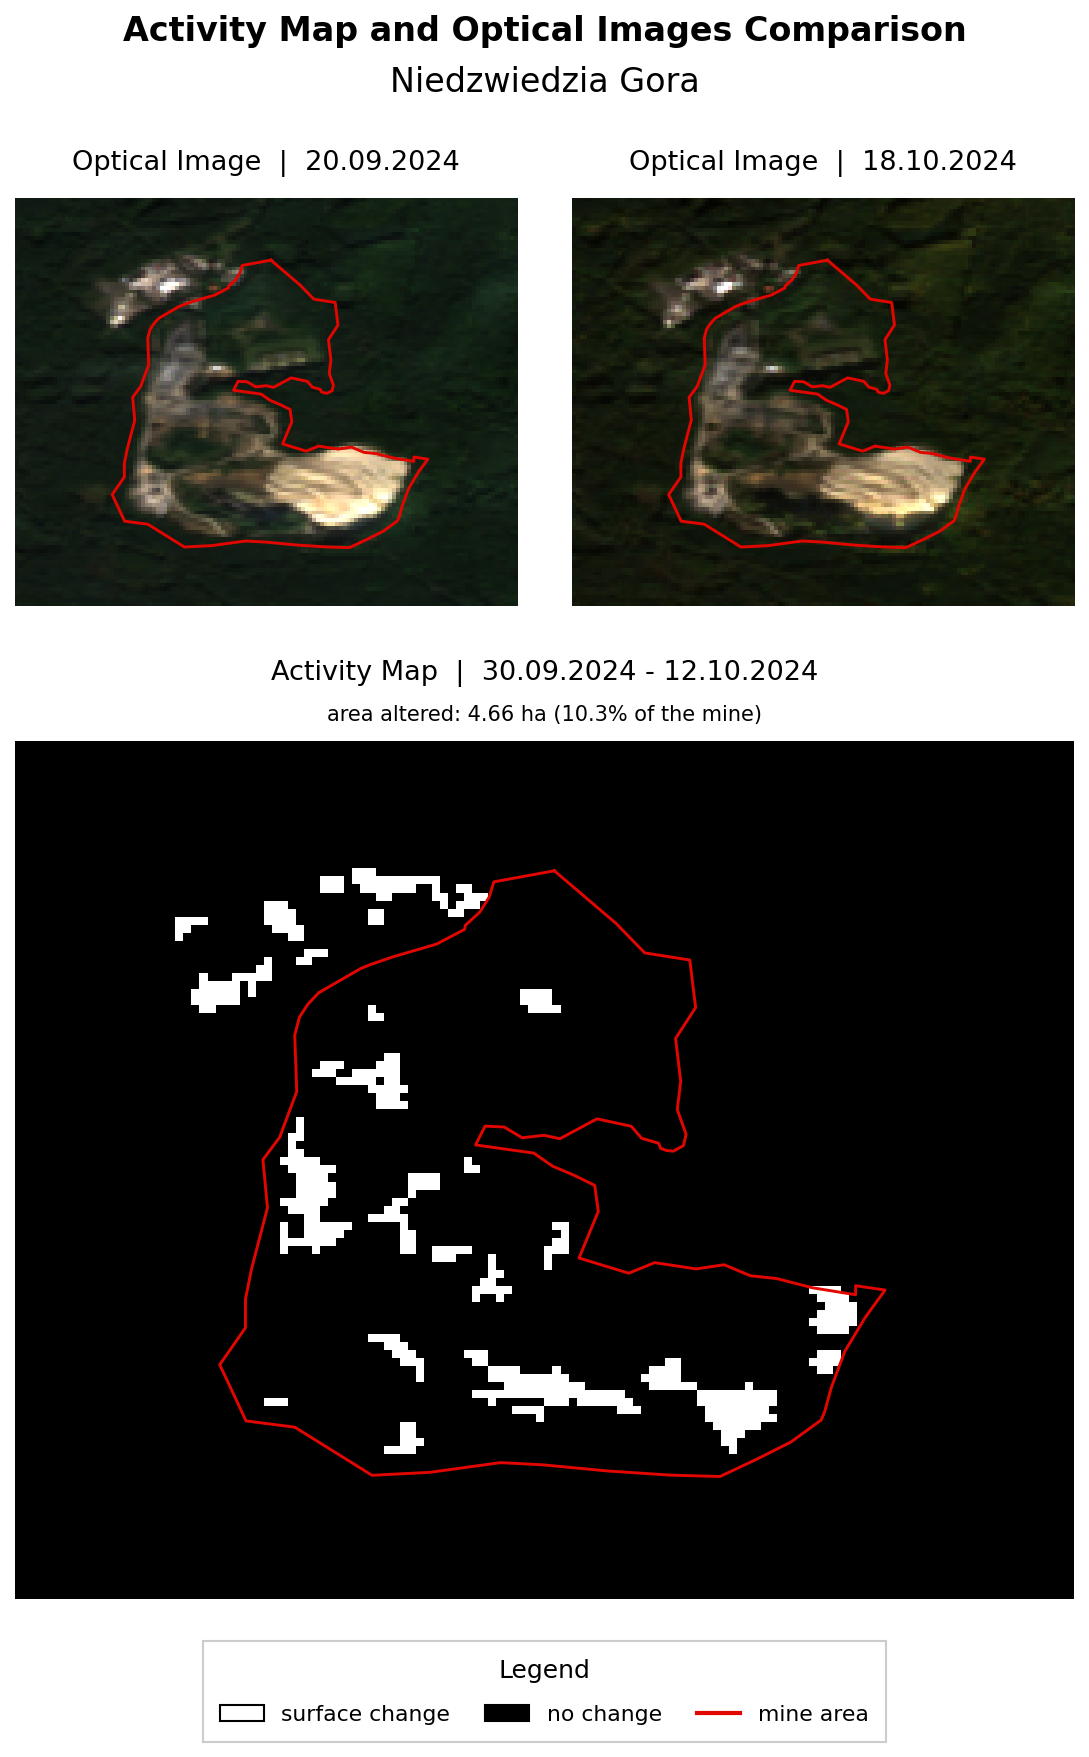

  pair 15/18: 2024.10.12 - 2024.10.24
    area changed inside the polygon: 72715 m2, 16.1% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.10.12-2024.10.24_activity_map_with_mask.png


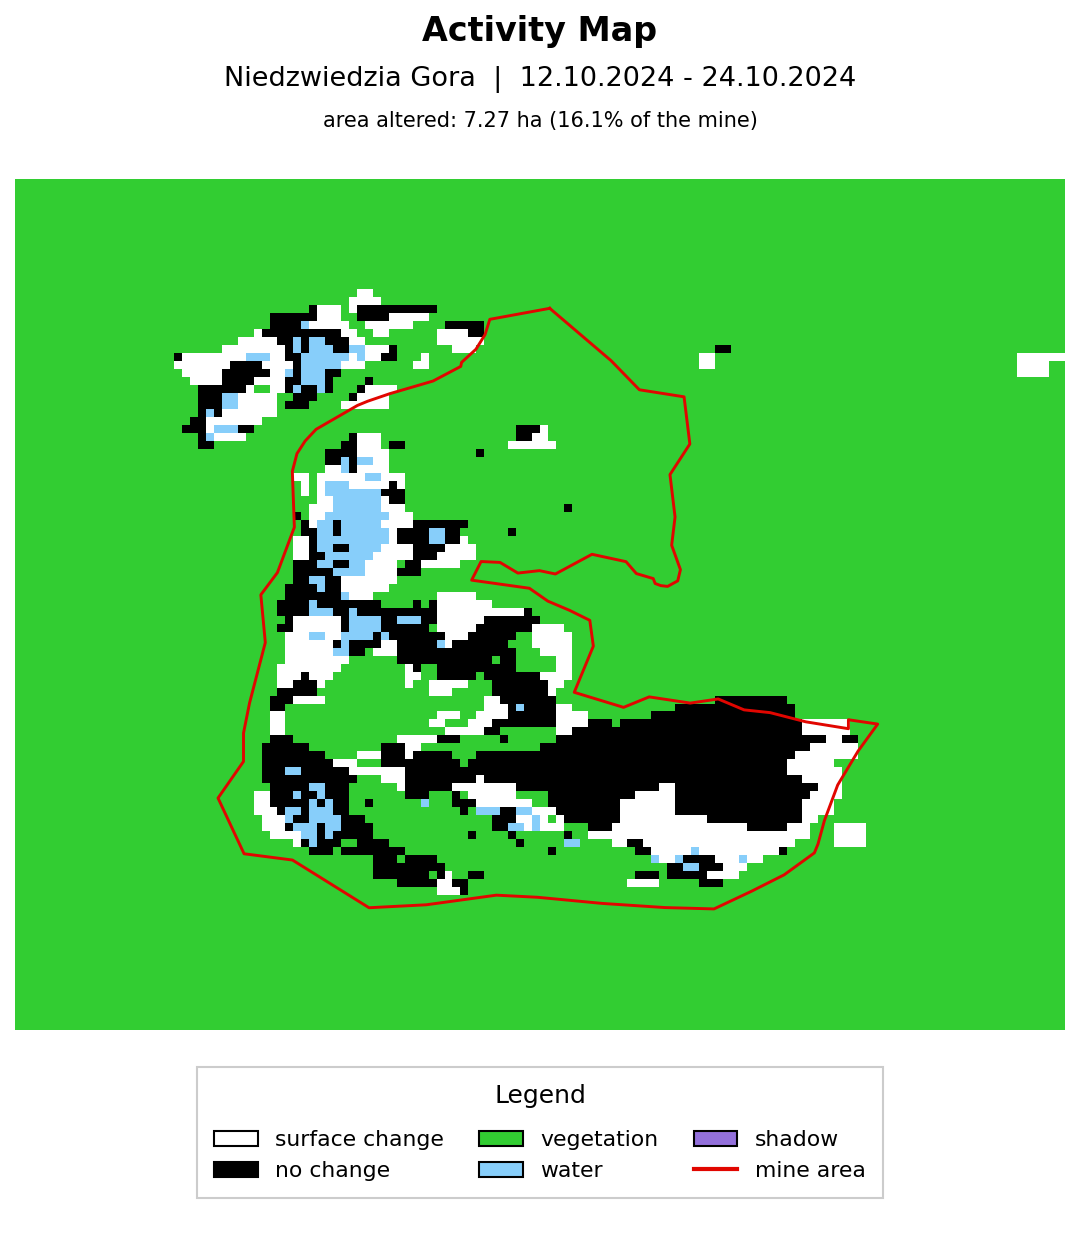

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.10.12-2024.10.24_activity_map.png


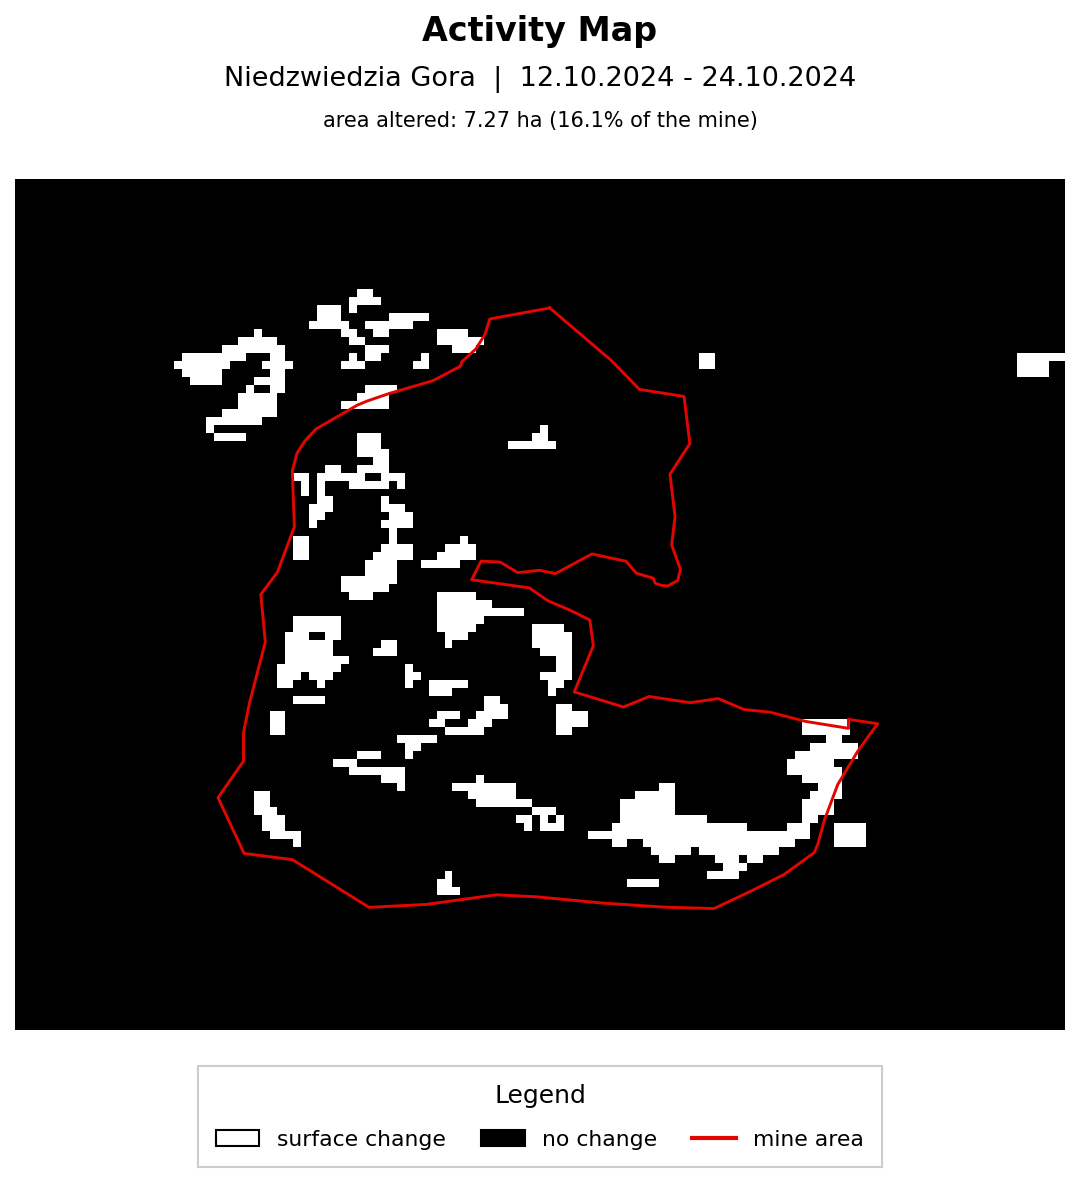

    searching for Sentinel-2 images ...
      date range: 2024-09-12 - 2024-10-11
    Sentinel-2 image scelected: 2024.10.10 20241010T094029_20241010T094629_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-10-25 - 2024-11-24
    Sentinel-2 image scelected: 2024.10.25 20241025T094101_20241025T094347_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.10.12-2024.10.24_activity_map_optical_images.png


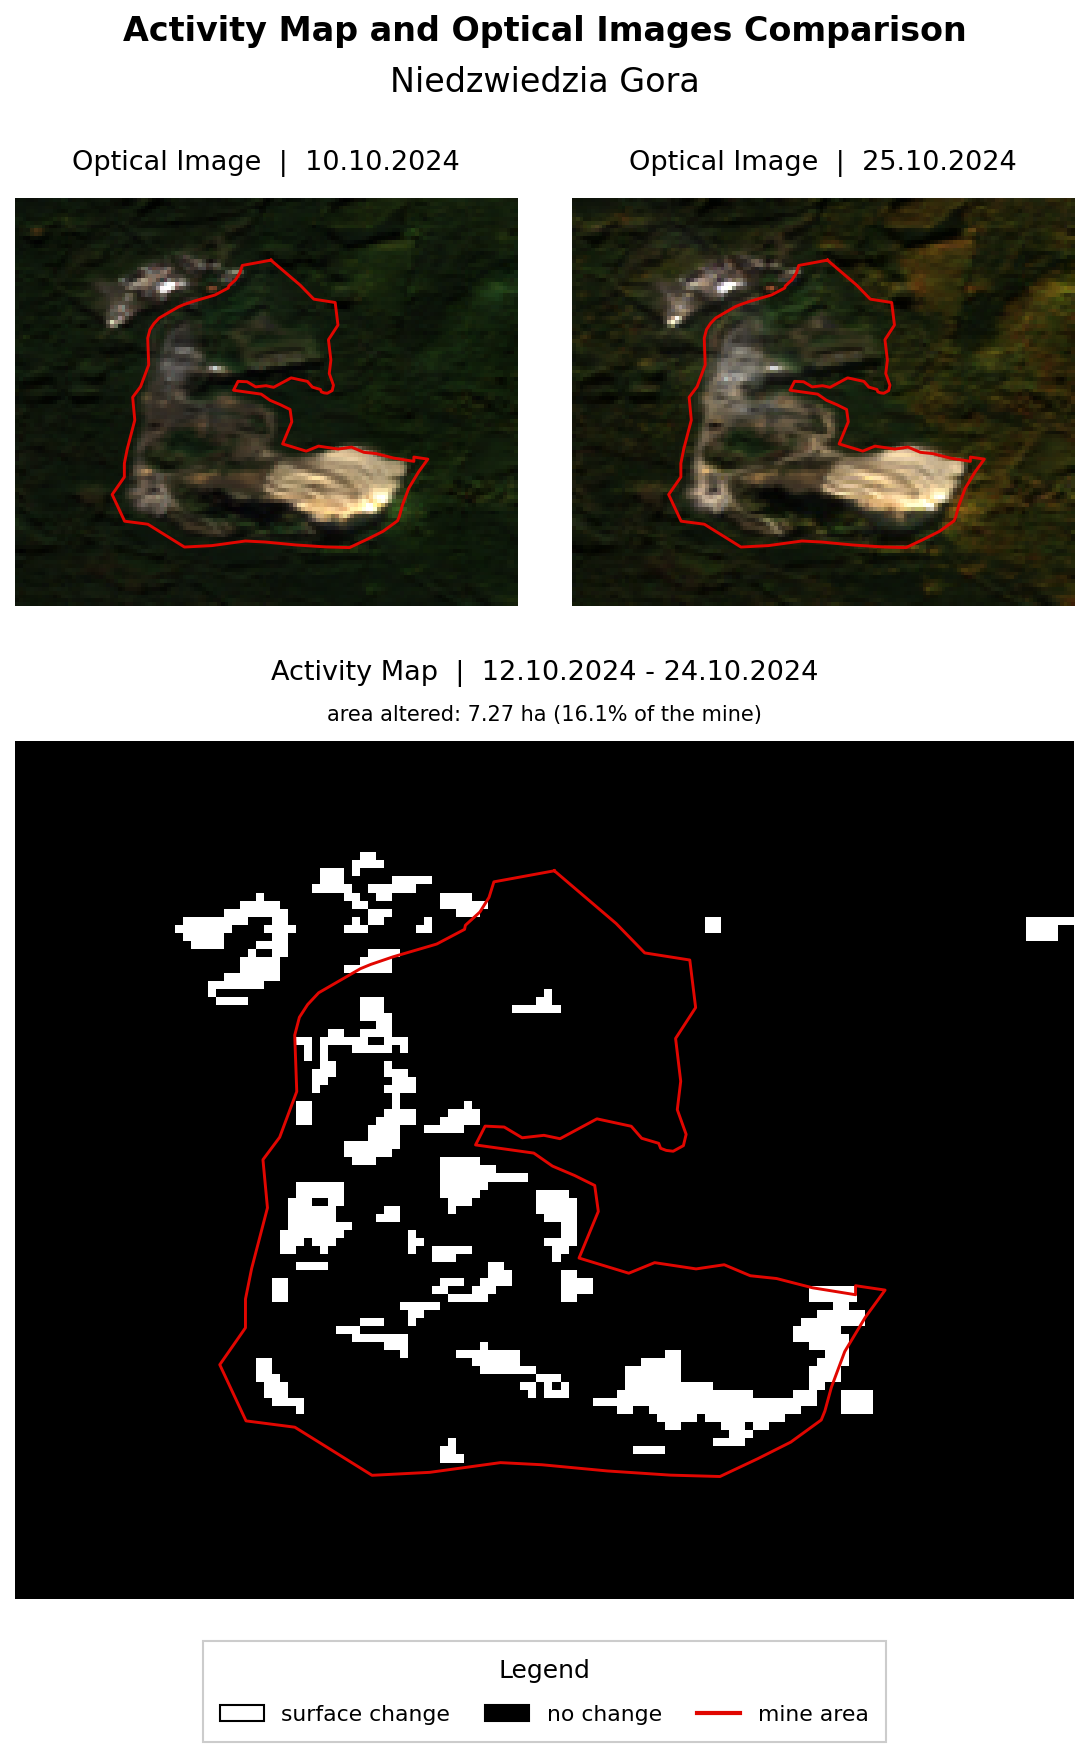

  pair 18/18: 2024.11.17 - 2024.11.29
    area changed inside the polygon: 151531 m2, 33.5% of the polygon
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.11.17-2024.11.29_activity_map_with_mask.png


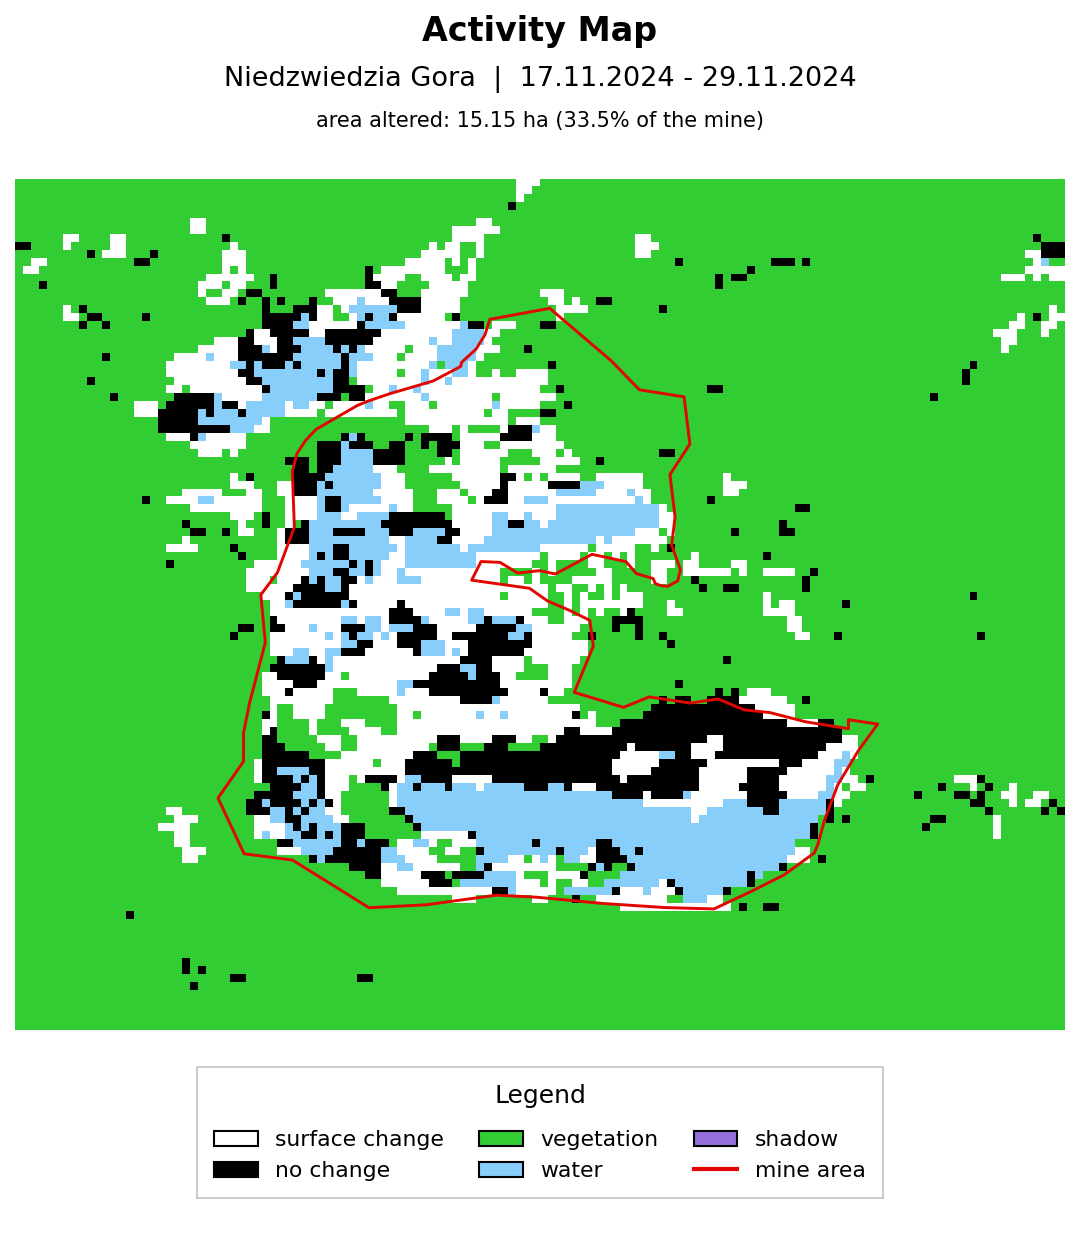

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.11.17-2024.11.29_activity_map.png


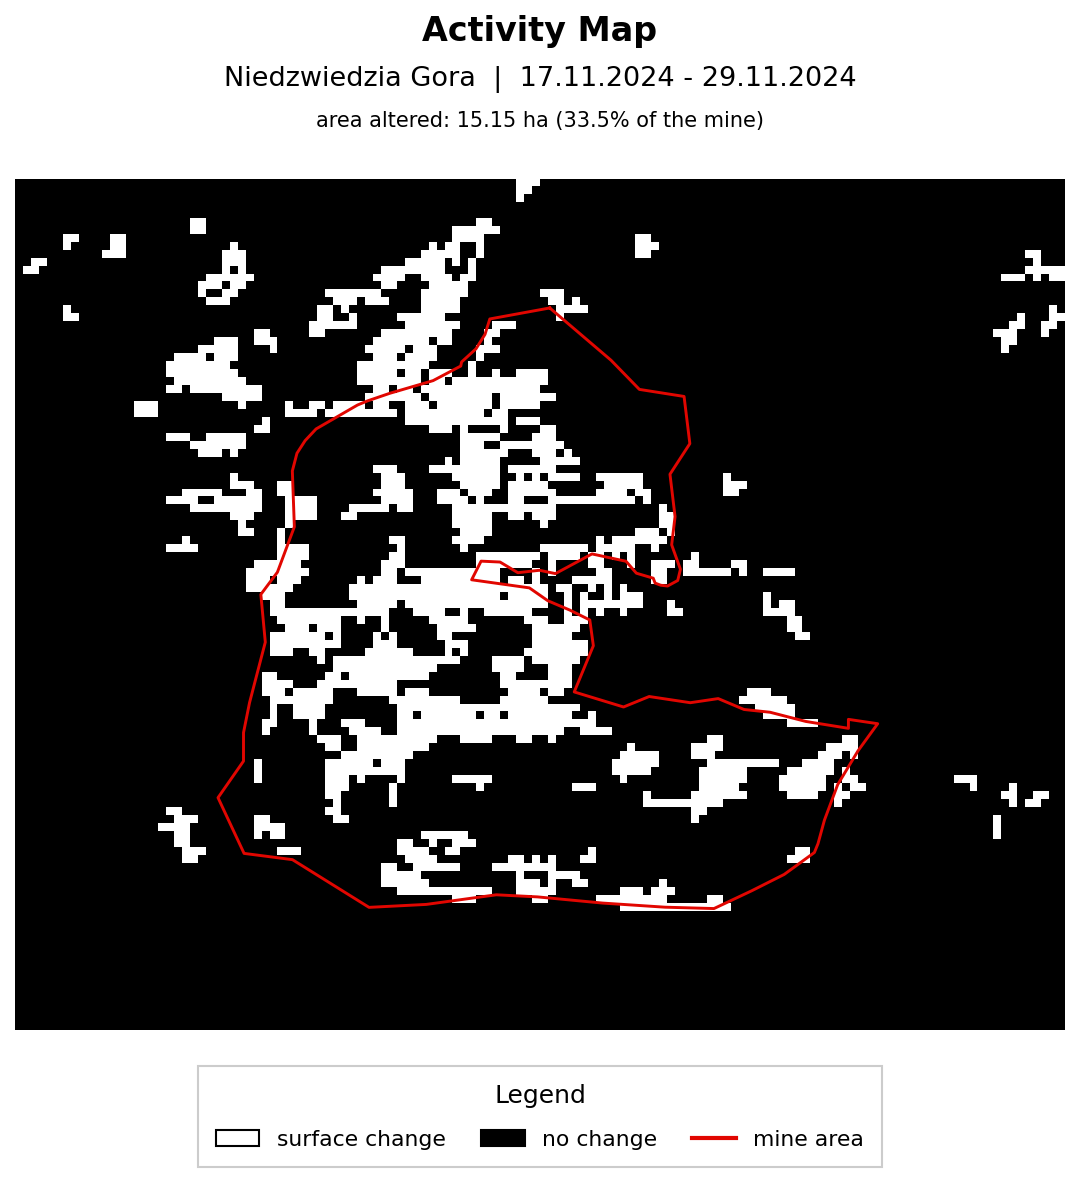

    searching for Sentinel-2 images ...
      date range: 2024-10-17 - 2024-11-16
    Sentinel-2 image scelected: 2024.10.25 20241025T094101_20241025T094347_T34UCA
    searching for Sentinel-2 images ...
      date range: 2024-11-30 - 2024-12-29
    Sentinel-2 image scelected: 2024.12.27 20241227T095421_20241227T095423_T34UDA
Saved map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\2024.11.17-2024.11.29_activity_map_optical_images.png


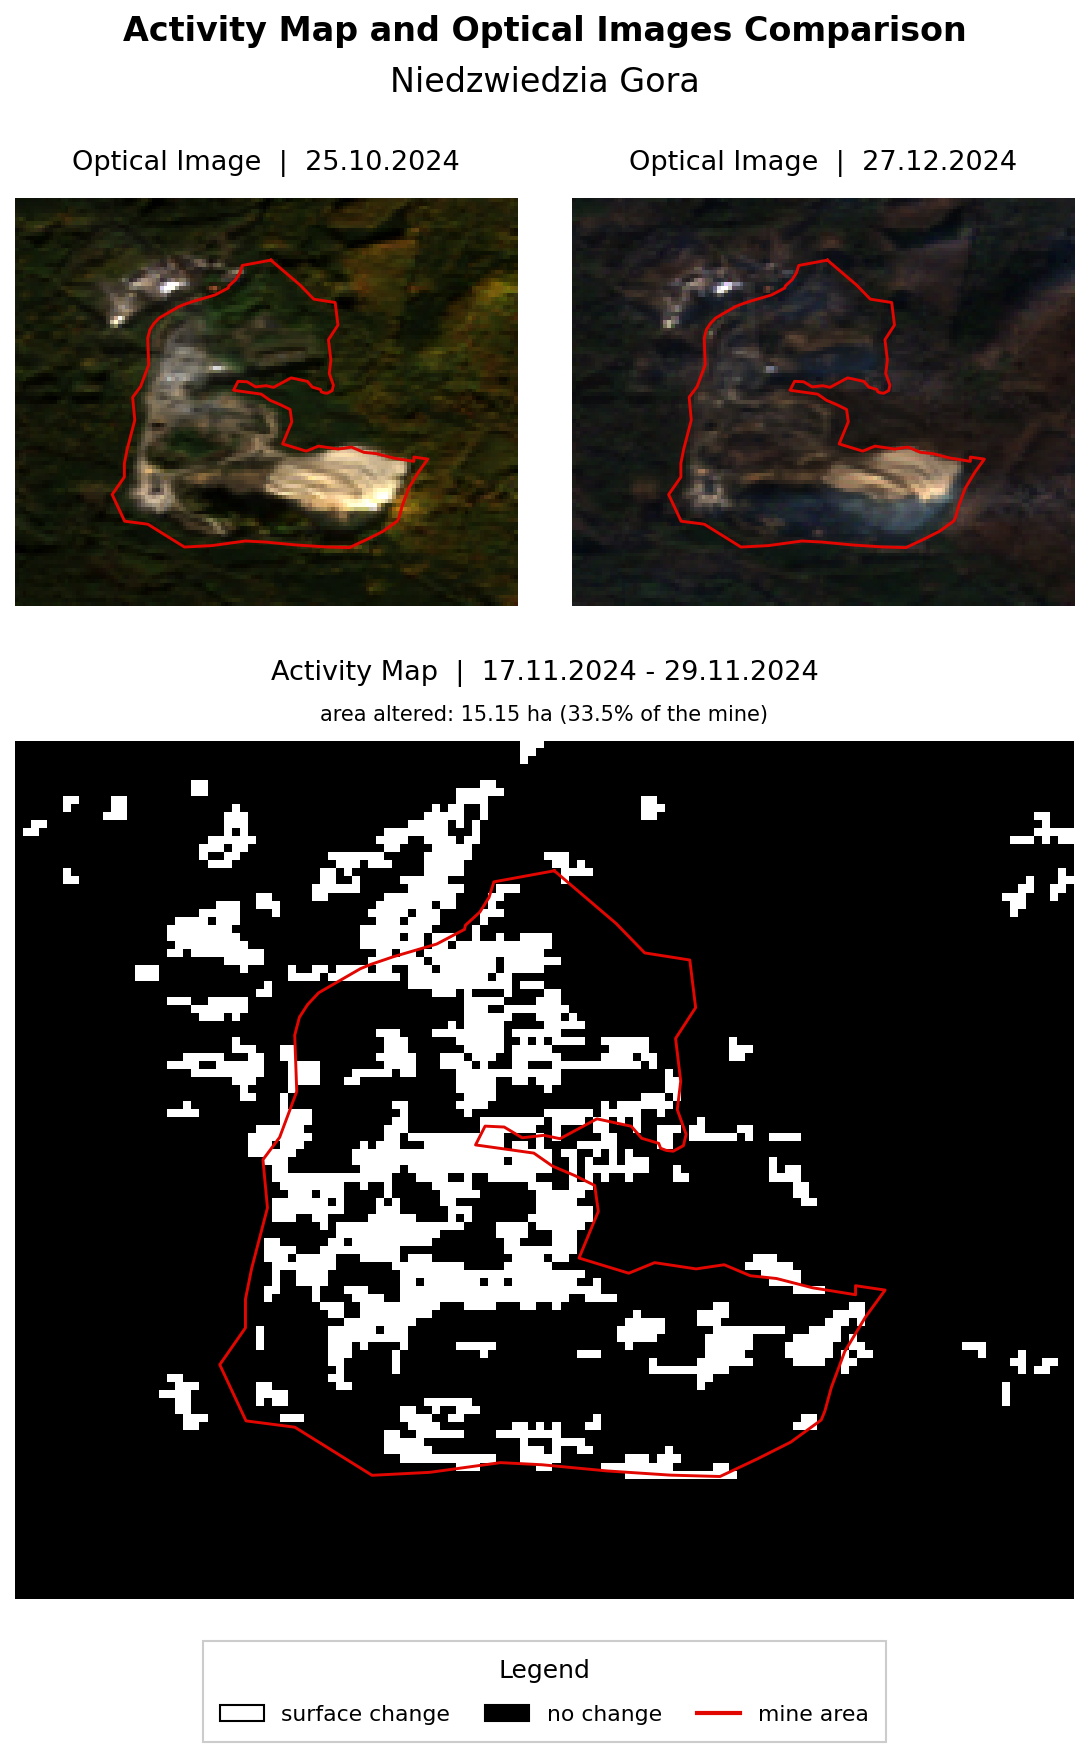

Saved GIF: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_activity_maps_niedzwiedzia_gora\activity_maps.gif


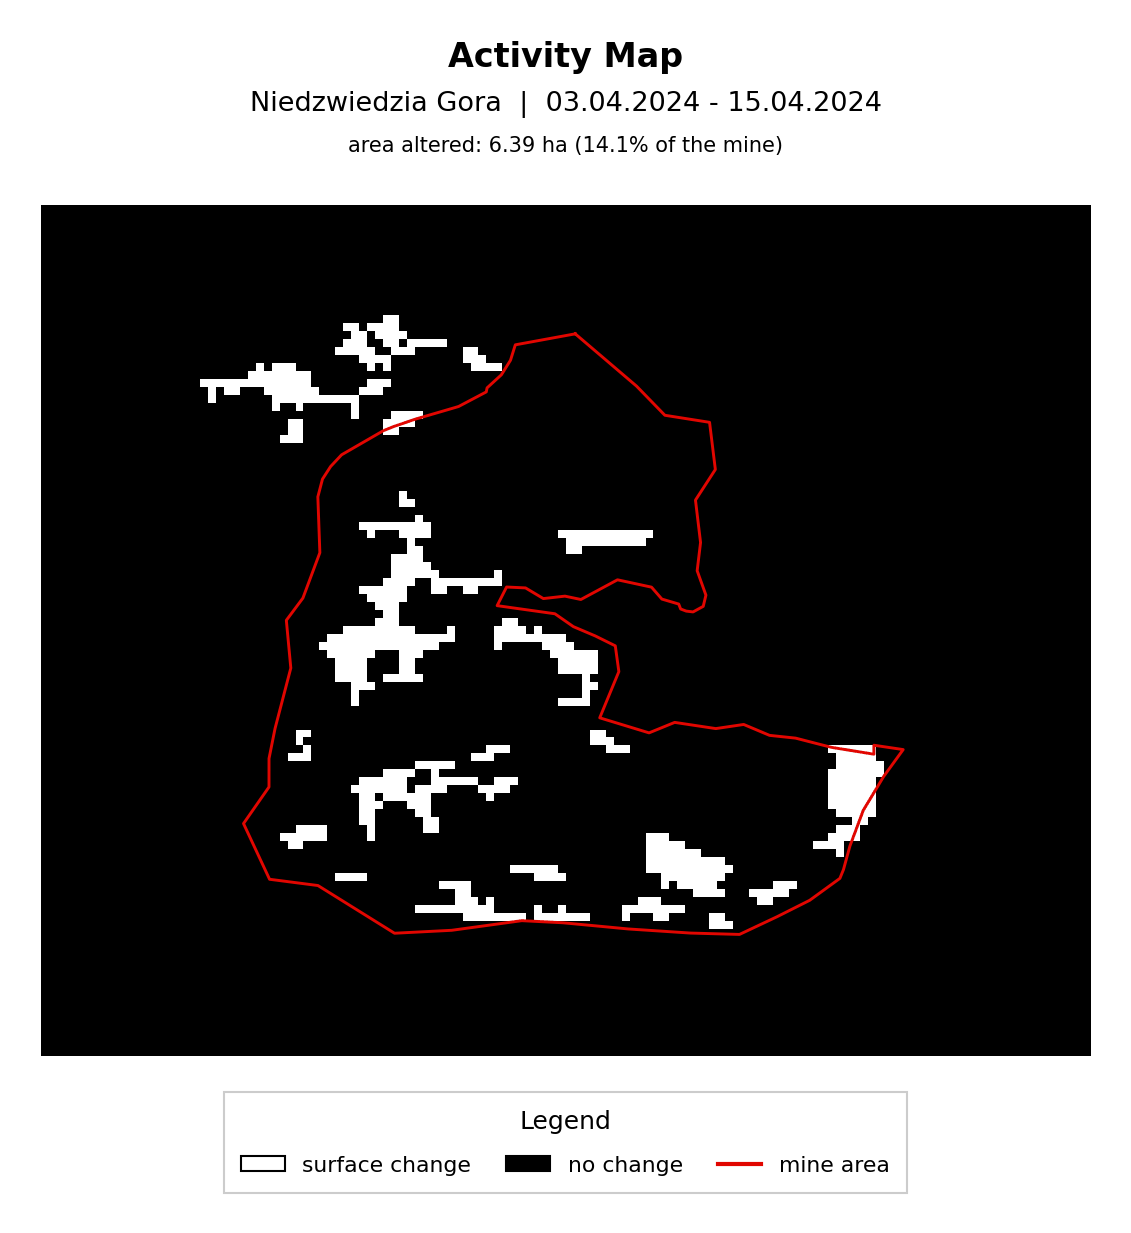

In [442]:
def coherence_analysis(master_zip, slave_zip):
    master_slc = open_slc(master_zip)
    slave_slc = open_slc(slave_zip)

    master_orb = apply_orbit_file(master_slc)
    slave_orb = apply_orbit_file(slave_slc)

    subswath = choose_subswaths_for_aoi(master_orb)

    master_orb_split = { swath: topsar_split(master_orb, swath) for swath in subswath }
    slave_orb_split = { swath: topsar_split(slave_orb, swath) for swath in subswath }

    orb_split_stack = { swath: back_geocoding(master_orb_split[swath], slave_orb_split[swath]) for swath in subswath }
    orb_split_stack_coh = { swath: coherence_estimation(orb_split_stack[swath]) for swath in subswath }
    orb_split_stack_coh_deb = { swath: topsar_deburst(orb_split_stack_coh[swath]) for swath in subswath }

    if len(orb_split_stack_coh_deb) > 1:
        orb_split_stack_coh_deb_merge = topsar_merge([orb_split_stack_coh_deb[swath] for swath in subswath])
    else:
        orb_split_stack_coh_deb_merge = orb_split_stack_coh_deb[subswath[0]]

    orb_split_stack_coh_deb_merge_multi = multilook(orb_split_stack_coh_deb_merge)
    orb_split_stack_coh_deb_merge_multi_tc = terrain_correction(orb_split_stack_coh_deb_merge_multi)

    mine_sub = subset(orb_split_stack_coh_deb_merge_multi_tc, AOI_MINE)
    stable_points_sub = subset(orb_split_stack_coh_deb_merge_multi_tc, AOI_STABLE_POINTS)

    opened = [
        master_slc, slave_slc, master_orb, slave_orb,
        *master_orb_split.values(), *slave_orb_split.values(),
        *orb_split_stack.values(),
        *orb_split_stack_coh.values(),
        *orb_split_stack_coh_deb.values(),
        orb_split_stack_coh_deb_merge,
        orb_split_stack_coh_deb_merge_multi, 
        orb_split_stack_coh_deb_merge_multi_tc, 
        mine_sub, stable_points_sub,
    ]

    mine = raster_to_array(mine_sub, master_zip, slave_zip, "mine")
    stable_points = raster_to_array(stable_points_sub, master_zip, slave_zip, "stable_points")

    close_products(opened)

    return {"mine": mine, "stable_points": stable_points}


AOI_MINE = make_polygon_buffer(POLYGON_PATH)
AOI_STABLE_POINTS = make_reference_window()
AOI_PROCESSING = unary_union([
    shapely_wkt.loads(AOI_MINE),
    shapely_wkt.loads(AOI_STABLE_POINTS),
]).wkt

stack_sentinel1_scenes = find_sentinel_1_scenes()

session = start_asf_session()
master_day = download_images(stack_sentinel1_scenes[0], session)
slave = download_images(stack_sentinel1_scenes[1], session)

stack_coherence_mine = []
stack_coherence_reference = []

for scene in range(len(stack_sentinel1_scenes) - 1):
    print("Pair %d/%d  %s  x  %s" % (scene + 1, len(stack_sentinel1_scenes) - 1, master_day.name, slave.name))

    gap_days = (scene_day(slave) - scene_day(master_day)).days
    if gap_days <= 13:
        coherence = coherence_analysis(master_day, slave)
        stack_coherence_mine.append(coherence["mine"])
        stack_coherence_reference.append(coherence["stable_points"])
    else:
        print("  skip pair, %d days between scenes, pair is valid when gap is 13 days or less" % gap_days)

    #remove_scene(master)

    if scene + 2 < len(stack_sentinel1_scenes):
        master_day = slave
        slave = download_images(stack_sentinel1_scenes[scene + 2], session)

gamma_stable_for_raster = calculate_stable_points(stack_coherence_reference)
saved_ndai_maps = ndai_maps(stack_coherence_mine, gamma_stable_for_raster)

show_activity_gif(saved_ndai_maps)
